# 2026年の経済モデル統合
## ── 価格と信用と土地と災害、そして一人の暮らし

## 第 0 章 このノートについて

文責: JRF ( http://jrf.cocolog-nifty.com/statuses/ )<br>
模型・実験・Lean の証明の補助: Claude Opus 5.5 (Anthropic)<br>
2026年10月

---

### この文書について

この文書は、同じ作者の古い考えを読み直すシリーズの、締めくくりの一冊である。

これまでのノートは、作者の模型を一つずつ取り出し、今の目で読み直してきた。このノートでは、それらを**一つの経済**に組み上げる。組み上げた模型を **im**(integrated model)と呼ぶ。

作者がもともと「ミクロ経済学の我流シミュレーション」(2020 年まで)で考えたかったのは、次のようなことだった。

- 企業の数を、離散ではなく連続にできないか。
- 輸出入を考えられないか。
- どの企業も生産したがらないとき、「危機時の生産」の仕組みを入れたら、シミュレーションはうまくいかないか。
- そして、経済を**最適化で簡単に書いてしまう**という考えそのものを、発展させられないか。

信用循環モデル(credit_simulation)のシリーズも、もとは企業の数を連続にしたいという関心から始まった。im は、その二つの流れ ── 価格を最適化で決める micro_economy と、信用と分配の credit_simulation ── を合わせ、シリーズの各ノートで見つけた部品(土地と知財、災害と安全網、学習、投票、貸し手、文化、年金)を、一つずつ差し込んで育てた模型である。

模型は、ノートの外で**段階ごとに**育てた(段 0〜19)。段ごとに、帳簿が閉じていること、新しい部品を切れば前の段と同じ数が出ること、その段の問いへの答えが出たことを確かめた。うまくいかなかった試みも、そのまま記録に残してある。このノートは、その記録を順に語り直したものである。

### このシリーズ

同じ作者(JRF)の、AI 以前の経済の模型と構想を、今の目で読み直すシリーズである。書かれた順に並べる(読む順の勧めも同じ)。ノート O の O は Origin(始まり)で、作者の経済のシミュレーションの始まりにあたる 2011 年の模型を扱う。

- ノート 1「価格を最適化で決める経済 ── 2020年までの micro_economy モデルの解剖」(`micro_economy_anatomy.ipynb`)
- ノート O「経済の中で経済が育つ ── 2011年の外作用モデルと『埋め込み』の遷移」(`embedded_economy.ipynb`)
- ノート 2「土地と知財と借金 ── 2019年の資産市場シミュレーションの解剖」(`asset_market.ipynb`)
- ノート P「ポイントと年金と信用 ── ネットの小さな通貨の設計(2006〜2018)」(`points_pension.ipynb`)
- ノート I「必需品と贅沢品の宇宙的独立関係 ── 絶滅の確率、0 × ∞、ナイト的不確実性、そして学習」(`cosmic_independence.ipynb`)
- ノート 3「誰が一家離散するのか ── シミュレーション仏教の経済と、裾の重い運」(`simbd_economy.ipynb`)
- ノート M「雑多なモデルの再検討 ── 必需品と贅沢品、縁故主義、投票、AI と弾圧」(`misc_models.ipynb`)
- ノート 4「2026年の経済モデル統合 ── 価格と信用と土地と災害、そして一人の暮らし」(`integrated_model.ipynb`) ← **この文書**

### このノートの問い

1. **作者の「経済を最適化で書く」は、統合した経済で成り立つか**。財の価格(均衡の残差の最小化)と、信用・資産(部門の帳簿)と、家計の分布(標本)を、一つにつなげるか。
2. **分配の集中は、何を起こすか**。集中 → 貸し手の慎重さ → 金利 → 投資と雇用、という筋書きは出るか。信用循環モデルの実効準備率 ρ_eff = ρ + μ·max(0, Φ − θ) は、この経済の中で正当化できるか。
3. **政策のつまみの効き方は、行動の仮定でどう変わるか**。
4. **危機にどう備えるか**。災害、品不足、財政の行き詰まり、輸出入、安全網。
5. **簡単な版と詳細な版は、どう関係するか**。部品を一つずつ入れたとき、どの部品がどの結論を変えるか。

そして、作り終えたあとで、JRF から新しい問いが加わった。**この箱庭の中で、一人の人間として暮らしたら、何が見えるか**(第 16 章)。

### 答えの見通し

結論を先に書いておく(詳しくは各章と、第 18 章のまとめで)。

1. **書ける**(第 1〜3 章)。一年の三つの価格を均衡の残差の最小化で解き、帳簿を毎年閉じたまま、信用・土地・知財・株・地域・災害・年金・貸し手・一人のプレイヤーまで積み上げられた。どの段の関門でも、帳簿と標本の差は所得の 1e-12 以下である。ただし、最適化で解くのは「年の中の釣り合い」だけで、年をまたぐ動き(投資、値上げ幅、信念)は規則で書いた。模型が暴れたとき(投資の発散、値上げ幅の積み上がり、文化と技術の帰還)、その元はいつも規則の側にあった。
2. **分配の集中は、貸し手の慎重さを通じて雇用を下げ、土地がそれを一段強める**(第 3、4 章)。集中への反応を切ると、効き目のほとんどが消える。ρ_eff の折れ線の形は、富む家計の**死蔵**と、量の決まった準備から、そのまま出てくる(第 8 章)。ただし、雇用を動かす主役は量の縛りではなく、金利の上乗せである。
3. **政策の向きは、行動の仮定と、ほかの政策のつまみの組み合わせで変わる**(第 2、3、17 章)。価格のない骨組み(gj)では、再分配の向きが、投資の利潤への反応で逆になった。価格と信用のある im では、既定の財政のルールのもとで、再分配はどの投資の仮定でも雇用を上げた。逆向きが出たのは、財政のルールが需要を締めるとき(赤字を 0 に)だった。このノートを書くときに確かめ直して、わかったことである。
4. **打撃の相関で、効く備えが変わる**(第 5〜7 章)。ばらばらの打撃には相互の保険、局地の打撃には地域の間の分け合い(共通の通貨)、共通の打撃には打撃の前の守り。長い品不足には「最後の生産者」(政府が生存の量まで作らせる)がよく、作者の元の規則(損失の分担)はそれに近い。「災害 → 財政破綻」は、災害そのものより、災害のあとの物価の上昇に金利で戦うことから起きる。
5. **部品を切れば、前の段と同じ数が出る**(第 17 章)。どの部品がどの結論を変えたかを、表にまとめる。

ほかに、作者の構想のいくつかが、模型の中で形になった。

- 作者の「国庫」の案(部門の利益の一部を、研究の当たりに比例して配る)は、知財の保護よりよく、公の研究所に並ぶ(第 10 章)。
- 文化(贅沢品の種類)が技術の学習に効く道を入れると、技術の進みは 2 倍になる。ただ、その道に頭打ちがないと、経済は必ず発散する(第 11 章)。
- 積立の年金で株を買っても、倹約のパラドックスは解けない(第 12 章)。
- 関係融資は探索を細らせ、市場型の貸し手は「株式的富のペテン」に乗りやすい。ペテンは、投資の外部性のもとで半ば本当になる(第 13 章)。
- 平行世界(危機に近づいた世界を複製して未来を分ける方法)は、偏りなく推定できるが、この経済の稀な危機では素朴な数え上げに勝てない(第 14 章)。
- 一票は決め手にならない(ダウンズ)が、群れの相関を動かす呼びかけは、投票の相転移の手前でだけ政策を替える(第 16 章)。

### 模型を育てた「段」

im は、一度に作ったのではなく、部品を一つずつ差し込む**段**(段 0〜19)に分けて育てた。本文では「段 1 の記録では……」のように、段の番号で言うことがある。記録の台本と結果も、段ごとに `im/results_stage1.py`・`im/results_stage1.txt` のような名前で置いてある。段ごとに、次の三つを確かめた(関門)。

1. 帳簿が閉じている(第 2 章)。
2. 新しい部品を切れば、前の段と同じ数が出る(部品はすべて既定では切ってある)。
3. その段の問いへの答えが出ている。

| 段 | 入れた部品 | 章 |
|---|---|---|
| 0 | 帳簿の骨組み、パラメータの登録簿(ノート M の二財の模型 gj で試す) | 2 |
| 1 | me_c の価格と生産、銀行の信用、標本の家計、貸し手の慎重さ | 3 |
| 2、2b | 土地と知財の市場 | 4 |
| 3、3b、3c | 二つ・三つの地域、共通の通貨・固定・変動の為替 | 5 |
| 4、4b | 災害、守り、救済、財政の行き詰まりの道 | 6 |
| 5 | 災害の頻度の学習、投票、企業の研究、株式の市場、規則的に研究する企業と真似る企業(世界樹) | 9、10、4 |
| 6 | 資本の移動、財政同盟、富裕税 | 5 |
| 7 | 危機時の生産(価格の上限、最後の生産者、損失の分担、在庫、備蓄、公共事業) | 7 |
| 8、8b | 文化(贅沢品の種類)、文化から技術への波及 | 11 |
| 9 | 家計ごとの資産の運、子を育てる費用 | 12 |
| 10、10b | 年齢と年金、BI、児童手当、積立の基金が株を買う | 12 |
| 11 | 自動化 | 10 |
| 12 | 人間の有限の注意(慣性) | 9 |
| 13 | 信念の区間、三つの勘定 | 9 |
| 14 | 作り手の流出、国庫の案 | 10 |
| 15、15b、15c | 関係融資と市場型融資、探索の借入、株式的富のペテン | 13 |
| 16 | 死蔵と準備率 | 8 |
| 17、17b、17c | 時間の層、歴史の重点標本化、平行世界 | 14 |
| 18 | 格上げ(別枠の模型) | 15 |
| 19 | 箱庭の中の一人(プレイヤー) | 16 |

段 7 からあとは、段 0〜6 で一通りの経済ができたあと、まだ入れていなかった作者の構想と、シリーズの各ノートの部品を、一つずつ足したものである。章の順は、段の順ではなく、話の流れに合わせた。

また、どの段でも、作る前に**当初の目論見**(こうなるはず、という予想)を書き、結果と比べた。本文では、外れたときに「当初の目論見『……』は外れた」と書く。外れた目論見の一覧と、その教訓は、第 18 章にまとめる。

### このノートの組み立て

| 部 | 章 | 中身 | 段 |
|---|---|---|---|
| I 道具立て | 0〜3 | 素材の模型(me_c と v6b)、帳簿の骨組み、価格と信用と標本の家計 | 0、1 |
| II 資産と世界 | 4、5 | 土地と知財と株、地域と通貨と資本の移動 | 2、2b、3、3b、3c、6 |
| III 危機 | 6〜8 | 災害と財政、危機時の生産、死蔵と準備率 | 4、4b、7、16 |
| IV 学び、探し、楽しむ | 9〜11 | 学習と政治、研究と世界樹、文化と多様性 | 5、11〜14、8、8b |
| V 人と暮らしと貸し手 | 12、13 | 運と家族と年金、貸し手 | 9、10、10b、15、15b、15c |
| VI 時間と、経済の外側 | 14〜16 | 時間の層と平行世界、格上げ、箱庭の中の一人 | 17、17b、17c、18、19 |
| VII まとめ | 17、18 | 部品の表と地図、まとめ | |

### Lean による証明

議論の要の命題のいくつかを、定理証明支援系 **Lean 4**(と数学ライブラリ Mathlib)で証明する。章ごとに `%%writefile -a integrated_model.lean` でファイルに書き足していき、第 18 章の付録 A で一括して確かめる。

| 章 | 定理 | 中身 |
|---|---|---|
| 1 | `lift_shift_sum`、`lift_ratio_sum`、`lift_keeps_gap` | 標本の持ち上げ(人数に比例してずらす、比で掛ける)で、総額はマクロに一致し、散らばりは保たれる |
| 2 | `entry_sum_zero`、`ledger_sum_zero` | どの取引も、部門の和を 0 に保つ(帳簿の恒等式) |
| 3 | `kalecki_general`、`kalecki_capitalist_income` | 労働者も貯めるときのカレツキの式 |
| 5 | `rentier_trade_deficit`、`deficit_equals_interest` | 経常収支が釣り合っていても、外からの利子が正なら、貿易収支は赤字(利子生活者の国)。赤字の大きさは利回り × 対外の純資産 |
| 8 | `credit_factor_antitone` | 準備が決まっているとき、死蔵が増えるほど、銀行が新しく貸せる割合は下がる |
| 11 | `capped_growth_bound` | 文化から技術への波及に上限があれば、伸びは指数で押さえられる |
| 16 | `turnout_monotone`、`carve_keeps_total` | 群れの相関が高まるほど投票率は上がる。プレイヤーを切り出しても総量は変わらない |

### 読み方

- 模型 im の本体は、公開リポジトリ( https://github.com/JRF-2018/jrf_economy_models_2026 )の `im/` にある。ノートは、それを取ってきて使う(リポジトリの `notebooks/` から開けば `../im` を、そうでなければ git clone する)。ソースは、主なアイデアのところだけを示す。
- 各章の実験は、その場で回す小さな版(標本 1000 記入、種 4 個ほど)と、ノートの外で回した記録(標本 2000 記入、種 8〜12 個。`im/results_stage*.txt`)の両方を示す。数が少しずれるのは、標本と種の数が違うためで、結論は変わらない。記録の台本は `im/results_stage*.py` で、誰でも回し直せる。
- 並列の計算(`multiprocessing` の fork)を使うので、Linux か macOS を想定している。並列の数は環境変数 `IM_WORKERS`(既定 4)で決める。多くしすぎるとメモリが足りなくなる(作者の計算機で、28 並列のときに一度落ちた)。
- 図の見出しや軸は英語にしてある(どの環境でも字が化けないように)。

### 目次

- 第 0 章 このノートについて
- **第 I 部 道具立て**
  - 第 1 章 素材の模型 ── me_c と v6b
  - 第 2 章 帳簿の骨組み
  - 第 3 章 価格と信用と標本の家計
- **第 II 部 資産と世界**
  - 第 4 章 土地と知財と株
  - 第 5 章 地域と通貨と資本の移動
- **第 III 部 危機**
  - 第 6 章 災害と財政
  - 第 7 章 誰も作りたがらないとき ── 危機時の生産
  - 第 8 章 お金が眠るとき ── 死蔵と準備率、ρ_eff の正体
- **第 IV 部 学び、探し、楽しむ**
  - 第 9 章 学習と政治
  - 第 10 章 研究と世界樹
  - 第 11 章 文化と多様性
- **第 V 部 人と暮らしと貸し手**
  - 第 12 章 運と家族と年金
  - 第 13 章 貸し手 ── 関係融資と市場型融資、株式的富のペテン
- **第 VI 部 時間と、経済の外側**
  - 第 14 章 時間の層と平行世界
  - 第 15 章 格上げ ── 経済の中で新しい経済が育つ
  - 第 16 章 箱庭の中の一人
- **第 VII 部 まとめ**
  - 第 17 章 部品の表と地図
  - 第 18 章 まとめと、シリーズの振り返り
- 付録 A: 再現のために
- 付録 B: 用語集
- 付録 C: 過去の議論
- 参考文献

### 準備

実験の道具(模型を探して読み込む、並列に回す、記録を読む、表にする)を書き出す。

In [1]:
%%writefile nb4_tools.py
# nb4_tools.py: ノート 4 の実験の道具(模型 im を探して読み込む、並列に回す、記録を読む、表にする)
import os
import sys
import subprocess
import warnings
import numpy as np
from concurrent.futures import ProcessPoolExecutor
from multiprocessing import get_context

REPO = 'https://github.com/JRF-2018/jrf_economy_models_2026'


def find_im():
    """模型 im の置き場所。公開リポジトリの notebooks/ から開けば ../im、なければ git clone で取ってくる。"""
    for d in ('../im', 'im', 'jrf_economy_models_2026/im'):
        if os.path.exists(os.path.join(d, 'im1.py')):
            return os.path.abspath(d)
    subprocess.run(['git', 'clone', '--depth', '1', REPO, 'jrf_economy_models_2026'], check=True)
    return os.path.abspath('jrf_economy_models_2026/im')


IM = find_im()
if IM not in sys.path:
    sys.path.insert(0, IM)
WORKERS = int(os.environ.get('IM_WORKERS', min(4, os.cpu_count() or 1)))   # 並列の数(多すぎるとメモリが足りなくなる)
FAIL = (ValueError, FloatingPointError, AssertionError, np.linalg.LinAlgError)

# どの実験でも使う一国の経済(段 1〜2 の基準): 標本の家計(連続の分布)、信用、土地と知財、技術の進歩なし
BASE = dict(households='continuous', Ns=1000, g_gamma=0.0, credit=True, land=True, c_h=0.005)


def pmap(fn, jobs):
    """jobs を並列に回す(fork を使う。Linux か macOS。fork なら、ノートの中で定義した関数もそのまま使える)。"""
    if WORKERS <= 1:
        return [fn(j) for j in jobs]
    with ProcessPoolExecutor(max_workers=WORKERS, mp_context=get_context('fork')) as ex:
        return list(ex.map(fn, jobs))


def _run(args):
    """一本の経済を T 年回し、記録のうち keys の列を返す。shocks は (年, パラメータの変更) の列。壊れたら None。"""
    import im1
    kw, seed, T, keys, shocks = args
    e = im1.Im1(seed=seed, **kw)
    out = {k: [] for k in keys}
    try:
        for t in range(T):
            for ts, ch in shocks:
                if t == ts:
                    e.p.set(**ch)
            r = e.step()
            for k in keys:
                out[k].append(r.get(k, np.nan))
    except FAIL:
        return None
    return {k: np.array(v, float) for k, v in out.items()}


def runs(cases, seeds=range(4), T=300, keys=('E',), shocks=(), base=BASE):
    """cases: (名前, パラメータ) の列。戻り値: {名前: [種ごとの記録(列の辞書)、壊れた種は None]}。"""
    keys = tuple(dict.fromkeys(tuple(keys) + ('Y', 'books', 'sample_gap')))   # 重なりを除く
    jobs = [(dict(base, **kw), s, T, keys, tuple(shocks)) for _, kw in cases for s in seeds]
    res = pmap(_run, jobs)
    n = len(list(seeds))
    return {lab: res[i * n:(i + 1) * n] for i, (lab, _) in enumerate(cases)}


def stat(a, how, burn):
    a = a[burn:]
    return {'mean': np.nanmean, 'std': np.nanstd, 'last': lambda x: x[-1], 'min': np.nanmin, 'max': np.nanmax,
            'sum100': lambda x: np.nansum(x) / len(x) * 100}[how](a)


def table(res, cols, burn=100, width=30):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)       # 記録のない列(nan)の警告を出さない
        _table(res, cols, burn, width)


def _table(res, cols, burn, width):
    """cols: (見出し, 記録の名前 か 関数(列の辞書 → 数), 'mean' などの集め方, 書式)。種の平均 ± 標準誤差を表にする。"""
    print('  ' + '場合'.ljust(width) + ' | ' + ' | '.join(c[0] for c in cols))
    worst = 0.0
    for lab, rs in res.items():
        ok = [r for r in rs if r is not None]
        if not ok:
            print('  ' + lab.ljust(width) + ' | すべて壊れた'); continue
        cells = []
        for _, key, how, fmt in cols:
            v = np.array([key(r) if callable(key) else stat(r[key], how, burn) for r in ok], float)
            se = np.nanstd(v) / np.sqrt(len(v)) if len(v) > 1 else 0.0
            cells.append(f'{np.nanmean(v):{fmt}}±{se:{fmt}}')
        for r in ok:
            worst = max(worst, np.nanmax(np.maximum(r['books'], r['sample_gap']) / np.maximum(np.abs(r['Y']), 1.0)))
        tail = f'  ({len(ok)}/{len(rs)})' if len(ok) < len(rs) else ''
        print('  ' + lab.ljust(width) + ' | ' + ' | '.join(cells) + tail)
    print(f'  (帳簿と標本の差/所得の最大 {worst:.0e})')


def mean_series(rs, key):
    """種の平均の時系列。"""
    ok = [r[key] for r in rs if r is not None]
    return np.nanmean(np.array(ok), axis=0)


def record(stage, start=None):
    """記録 results_<stage>.txt(標本 2000 記入、種 8〜12 個)を示す。start があれば、その文字列で始まる節だけ(次の節の見出しの手前まで)。
    節の見出しは、行の頭の「E1」「Y2」「V8b」「S17c」のような印(大文字と数字)で見分ける。"""
    import re
    lines = open(os.path.join(IM, f'results_{stage}.txt'), encoding='utf-8').read().splitlines()
    if start is None:
        print('\n'.join(lines)); return
    head = re.compile(r'^(== ?)?[A-Z]+[0-9]+[a-z]?[ \-:(]')
    out, on = [], False
    for ln in lines:
        if ln.startswith(start):
            on = True
        elif on and head.match(ln):
            break
        if on:
            out.append(ln)
    print('\n'.join(out))

Overwriting nb4_tools.py


In [2]:
import os, sys, shutil, subprocess, time, importlib, inspect
import numpy as np
import matplotlib, matplotlib.pyplot as plt

PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 2.0, 'font.size': 10, 'axes.titlesize': 11, 'legend.frameon': False,
    'figure.dpi': 100,
})
import nb4_tools as nt
from nb4_tools import runs, table, record, mean_series, BASE
import im1
print('Python', sys.version.split()[0], '/ numpy', np.__version__, '/ matplotlib', matplotlib.__version__)
print('CPU の数:', os.cpu_count(), '/ 並列の数:', nt.WORKERS)
print('模型 im の置き場所:', os.path.relpath(nt.IM))   # このノートからの相対の場所
LEANDIR = open('.leandir').read().strip() if os.path.exists('.leandir') else None
print('Lean のプロジェクト:', 'あり(.leandir に書いた場所)' if LEANDIR else 'なし(第 18 章の確かめの前に、elan と Mathlib を入れる)')
T0 = time.time()

Python 3.14.4 / numpy 2.5.4 / matplotlib 3.11.2
CPU の数: 28 / 並列の数: 4
模型 im の置き場所: ../im
Lean のプロジェクト: あり(.leandir に書いた場所)


Lean のファイルの頭を書いておく(定理は、章ごとに書き足す)。

In [3]:
%%writefile integrated_model.lean
/-
  「2026年の経済モデル統合」(ノート 4)の模型 im の、Lean による定式化
  文責: JRF / 定式化・証明: Claude Opus 5.5
  Lean 4 v4.34.1 + Mathlib
-/
import Mathlib

open Finset

namespace IntegratedModel

Overwriting integrated_model.lean


---

# 第 I 部 道具立て

## 第 1 章 素材の模型 ── me_c と v6b

im は、二つの模型を骨と肉にしている。**me_c**(micro_economy の現代化)が価格と生産の骨組みを、**v6b**(信用循環モデル v6 に資産市場を足し、家計を「標本」で持つ版)が信用と資産と家計の分布を与える。どちらも、シリーズの途中(ノート 3 の前、2026-10-27)に、ノート 4 の素材として作った。この章では、この二つを詳しく説明し、ソースの全文も載せる。ほかの素材(ノート M の二財の模型・縁故主義・投票、ノート 3 の災害、ノート I の信念の区間)は、使う章で必要な分だけ説明する。

| 素材 | 中身 | im のどこで使うか |
|---|---|---|
| me_c | 三財(必需品・贅沢品・原料)の価格を均衡の残差の最小化で解く。生産能力は連続、粘着的な賃金 | 一年の中の釣り合い(第 3 章) |
| v6b | 信用循環の部門(銀行の預金と貸出、国債)、土地と知財の市場、担保の上限、家計を「標本」として持つ(制限と持ち上げ) | 信用(第 3 章)、土地と知財(第 4 章)、家計の重みつきの標本(第 3 章〜) |
| ノート M 第 2 章(gj) | 帳簿を閉じた二財。ストーン–ギアリーの需要 | 帳簿の骨組みの試験(第 2 章) |
| ノート M 第 3、4 章 | 縁故主義の貸し手と投資の外部性、相関のある有権者の群れ | 貸し手(第 13 章)、投票(第 9、16 章) |
| ノート 3 | 家族の資産配分と裾の重い運、一家離散、災害と守りと学習 | 災害(第 6 章)、運(第 12 章) |
| ノート I | 信念の区間、探索と活用 | 学習(第 9 章) |
| ノート 2 | 土地と知財と借金、借入の上限 | 第 4 章 |

### 1.1 me_c: 価格を最適化で決める経済

ノート 1 で読んだ作者の micro_economy(2020 年まで)は、企業を一社ずつ持ち、価格を「最適化」で決めていた。ノート 1 は、その最適化がじつは「均衡の条件の二乗和を 0 にする」ことに当たる、と読んだ。そして、残る問いとして、企業の数の飽和(社の数を連続にできないか)、段差(人数を数えるところの不連続)、名目の錨(価格の水準が決まらない)を挙げた。

me_c は、それに答えて作り直した、読んで追える版である。

- **財は三つ**: 必需品 N、贅沢品 L、原料 I。どれも労働と原料から作る(一製品あたり労働 γ_j、原料 α_j)。生産能力一単位には、原料 κ_j が要る(固定資産)。
- **企業は社の数ではなく、分野ごとの生産能力 K_j(連続量)**で表す。参入と退出は、投資と減耗による能力の増減になる。投資は、前の期の利潤率と稼働率に反応する:
  能力の伸び g_j = δ + φ_r(ρ_j − r̄) + φ_u(u_j − u*)。
- **価格**: 三つの価格 (P_N, P_L, P_I) を、「価格 = (1 + マークアップ) × 単位費用」の三本の条件の残差の二乗和を最小にして決める。マークアップは稼働率で上下し(需要が強いと上がる)、能力を超えると残業で一製品あたり労働が増える。
- **名目の錨**: 賃金は粘着的で、労働の需給のずれに応じて期ごとに動く(フィリップス曲線)。価格の最適化の中では、名目の水準は決まらない(ノート 1 第 1.3 節)ので、錨を外に置く。
- **需要**: 生存量 q0 までは必需品、それを超えた支出の b_N を必需品、残りを贅沢品に(線形支出体系、ストーン–ギアリー)。すべて softplus でなめらかにして、段差をなくした。

me_c の全文を、ファイル `me_c.py` に書き出しておく(長いので、このあとは要の部分を取り出して説明する)。

In [4]:
%%writefile me_c.py
# me_c: micro_economy の「現代化」(v0.1、2026-10-27)
#
# 元の micro_economy_*.py(ノート 1)の骨格を残し、ノート 1 の「残る問い」に沿って作り直した、理解しやすさを優先した模型。
#   * 財は三つ: 必需品 N、贅沢品 L、原料 I(原料は原料にも要る。レオンチェフの投入)。
#   * 企業は「社の数」ではなく、分野ごとの生産能力 K_j(連続量)で表す。参入・退出は、投資と減耗による能力の増減になる。
#     新しい能力ほど一製品あたりの労働が少ない(機械の高度化。元の 0.95〜0.99 倍の連続版)。
#   * 人の数・働く人数・贅沢品の需要は、すべて連続でなめらか(段差がない)。
#   * 三つの価格は、毎期「均衡の残差」の最小化で決める(作者の「価格を最適化で決める」を、ノート 1 第 8 章の
#     教訓どおり、「いくらでも大きく」の項を入れず、0 になれば均衡という条件の二乗和で書く)。
#     条件は 3 本: 三つの分野の「価格 = (1 + マークアップ) × 単位費用」。マークアップは稼働率(需要の強さ)で上下する。
#     解の選び方の戦術として「前の期の価格に近い解」を小さな重みで加える。
#   * 賃金は粘着的で、労働の需給のずれに応じて期ごとに動く(フィリップス曲線)。これが名目の水準の錨になる
#     (ノート 1 第 1.3 節: 名目の水準は、価格の最適化の中では決まらない)。
#   * 家計の消費の支出は、前の期の所得と手持ちのお金で決まる(期の中の循環をなくし、解を安定させる)。
#   * 資本市場はない。企業の利潤は資本家にそのまま渡り、投資は資本家の手元のお金で賄う。お金は政府の負債(社会的負債)だけ。
#   * 政府は、失業者に必需品の生存量を給付し、賃金と配当に課税する。税率は、赤字の対所得比を目標(既定は 0 = 均衡予算)に動く。
#
# 将来の版で足す候補: 輸出入(二地域)、危機時の生産(在庫、最後の生産者)、家計の分布、信用(ノート 4)。
import numpy as np
from scipy.optimize import least_squares

SECT = ('N', 'L', 'I')


def softplus(x, k=1.0):
    return np.logaddexp(0.0, k * x) / k


def softmin(a, b, k=50.0):
    """なめらかな min(段差をなくすため)。min(a, b) = a − max(a − b, 0) の max を softplus でなめらかにする。"""
    return a - softplus(a - b, k / max(abs(b), 1e-9))


class Params:
    def __init__(self, **kw):
        # 人
        self.pop_w = 1000.0         # 労働者(働く人と働かない人の合計)
        self.n_cap = 5.0            # 資本家
        self.q0 = 1.0               # 一人あたり必需品の生存量
        # 技術(初期値は元のモデルの各分野の最初の企業に合わせる)
        self.gamma0 = np.array([0.1, 0.3, 0.3])    # 一製品あたり労働
        self.alpha = np.array([0.3, 0.5, 0.3])     # 一製品あたり原料
        self.kappa = np.array([1.0, 1.0, 1.0])     # 生産能力一単位に要る原料(固定資産)
        self.delta = 0.1                           # 能力の減耗(元の固定資産の寿命 10 期)
        self.g_gamma = 0.01                        # 新しい能力の一製品あたり労働が、毎期下がる率(機械の高度化)
        # 価格と稼働
        self.m0 = np.array([0.3, 0.3, 0.3])        # 基準のマークアップ(初期値)
        self.zeta = 0.5                            # 稼働率がマークアップに効く強さ(tanh で上下に頭打ち)
        self.u_star = 0.85                         # 目標の稼働率
        self.omega = 1.0                           # 稼働率が 1 を超えたときの割増(残業)の強さ
        self.eta = 0.05                            # 競争で基準のマークアップが利潤率の差に寄る速さ
        self.r_bar = 0.06                          # 標準の利潤率(元の「市場利子率」。経済の中では決まらない: ノート 1 第 8.3 節)
        # 投資(連続の参入・退出)
        self.phi_r = 0.5                           # 利潤率の差への反応
        self.phi_u = 0.3                           # 稼働率の差への反応
        # 賃金(フィリップス曲線)
        self.phi_w = 0.1                           # 労働の需給のずれへの反応
        self.chi = 0.2                             # 前の期の必需品の値上がりへの連動
        # 家計
        self.c_y = 0.9                             # 労働者の可処分所得からの消費性向
        self.c_m = 0.2                             # 労働者の手持ちのお金からの消費性向
        self.c_yc = 0.5                            # 資本家の可処分所得からの消費性向
        self.c_mc = 0.05                           # 資本家の手持ちのお金からの消費性向
        self.b_N = 0.3                             # 生存量を超えた支出のうち、必需品に回る割合(残りは贅沢品)
        self.beta_s = 3.0                          # 労働の供給の、実質賃金への反応
        self.w_res = 2.0                           # 留保の実質賃金(必需品の単位)
        # 政府
        self.tau0 = 0.2
        self.deficit_target = 0.0                  # 赤字 / 名目の最終需要 の目標(0 なら均衡予算)
        self.k_tau = 0.2                           # 税率の調整の速さ
        self.benefit = 1.0                         # 失業者への給付(必需品の生存量の何倍か)
        # 解き方
        self.tactic = 1e-4                         # 前の期の価格に近い解を選ぶ重み
        for k, v in kw.items():
            if not hasattr(self, k):
                raise KeyError(k)
            setattr(self, k, v)


class Economy:
    def __init__(self, p=None, **kw):
        self.p = p or Params(**kw)
        P = self.p
        self.t = 0
        self.K = np.array([1250.0, 400.0, 1100.0])          # 生産能力
        self.gamma = P.gamma0.copy()                        # 能力の平均の一製品あたり労働
        self.gamma_new = P.gamma0.copy()                    # 新しい能力の一製品あたり労働
        self.m0 = P.m0.copy()
        self.W = 10.0
        self.prices = np.array([3.0, 8.0, 6.0])             # P_N, P_L, P_I
        self.PN_prev = self.prices[0]
        self.M_w, self.M_c = 3000.0, 1000.0                 # 手持ちのお金(労働者、資本家)
        self.G = self.M_w + self.M_c                        # 政府の負債(= 家計のお金。銀行はない)
        self.tau = P.tau0
        self.Yd_w, self.Yd_c = 4500.0, 500.0                # 前の期の可処分所得
        self.rho_prev = np.full(3, P.r_bar)
        self.u_prev = np.full(3, P.u_star)
        self.profit_prev = 0.0
        self.log = []

    # ---------------------------------------------------------------- 一期のなかの計算
    def plan_investment(self):
        """投資は、前の期の利潤率と稼働率で決める(期のはじめに決めるので、今期の価格の計算とは切り離される)。"""
        P = self.p
        g = P.delta + P.phi_r * (self.rho_prev - P.r_bar) + P.phi_u * (self.u_prev - P.u_star)
        inv = self.K * softplus(g, 50.0)                      # 投資は負にならない(退出は減耗で起きる)
        # 資本市場がないので、投資は、前の期の利潤(内部留保)と、資本家の手持ちのお金の半分までで賄う
        cost = self.prices[2] * P.kappa @ inv
        avail = max(self.profit_prev, 0.0) + max(self.M_c, 0.0) * 0.5
        self.inv_limited = bool(cost > avail and cost > 0)
        if self.inv_limited:
            inv = inv * avail / cost
        return inv

    def budgets(self):
        """消費の支出(名目)。前の期の可処分所得と、手持ちのお金で決まる。"""
        P = self.p
        B_w = P.c_y * self.Yd_w + P.c_m * max(self.M_w, 0.0)
        B_c = P.c_yc * max(self.Yd_c, 0.0) + P.c_mc * max(self.M_c, 0.0)
        return max(B_w, 0.0), max(B_c, 0.0)

    def demand(self, price, inv, B):
        """価格のもとでの需要(なめらか)。生存量までは必需品、それを超えた支出を必需品と贅沢品に分ける(線形支出体系)。"""
        P = self.p
        PN, PL, PI = price
        xN = xL = 0.0
        for Bk, heads in zip(B, (P.pop_w, P.n_cap)):
            base = PN * heads * P.q0
            disc = softplus(Bk - base, 10.0 / max(base, 1e-9))     # 生存量を超えた支出(なめらか)
            xN += (Bk - disc) / PN + P.b_N * disc / PN
            xL += (1 - P.b_N) * disc / PL
        xI = (P.alpha[0] * xN + P.alpha[1] * xL + P.kappa @ inv) / (1 - P.alpha[2])
        return np.array([xN, xL, xI])

    def evaluate(self, price, inv, B):
        P = self.p
        x = self.demand(price, inv, B)
        u = x / self.K
        geff = self.gamma * (1 + P.omega * softplus(u - 1.0, 20.0))          # 能力を超えると、残業で一製品あたり労働が増える
        cost = self.W * geff + price[2] * P.alpha
        m = self.m0 + P.zeta * np.tanh(u - P.u_star)
        return x, u, geff, cost, m

    def residual(self, z, inv, B):
        P = self.p
        price = np.exp(z)
        x, u, geff, cost, m = self.evaluate(price, inv, B)
        res = list(z - np.log((1 + m) * cost))                             # 価格 = (1 + マークアップ) × 単位費用
        res += list(np.sqrt(P.tactic) * (z - np.log(self.prices)))         # 戦術: 前の期の価格に近い解
        return np.array(res)

    def solve_prices(self, inv, B):
        sol = least_squares(self.residual, np.log(self.prices), args=(inv, B), method='lm', xtol=1e-13, ftol=1e-13)
        return np.exp(sol.x), sol

    # ---------------------------------------------------------------- 一期を進める
    def step(self):
        P = self.p
        inv = self.plan_investment()
        B = self.budgets()
        price, sol = self.solve_prices(inv, B)
        x, u, geff, cost, m = self.evaluate(price, inv, B)
        PN, PL, PI = price
        W = self.W
        # 労働
        S = P.pop_w / (1.0 + np.exp(-P.beta_s * (np.log(W / PN) - np.log(P.w_res))))
        D = float(geff @ x)
        E = softmin(D, S)
        unemp = P.pop_w - E
        # お金の動き
        wage_bill = W * D                                   # 残業も含めた賃金の総額
        ben = P.benefit * P.q0 * PN * unemp
        profit = (price - cost) * x
        div = profit.sum() - PI * P.kappa @ inv            # 投資は利潤(と資本家の手持ち)で賄う
        tax_w, tax_c = self.tau * wage_bill, self.tau * max(div, 0.0)
        spend = PN * x[0] + PL * x[1]                       # = B の合計(作り方から)
        self.Yd_w = wage_bill - tax_w + ben
        self.Yd_c = div - tax_c
        self.M_w += self.Yd_w - B[0]
        self.M_c += self.Yd_c - B[1]
        deficit = ben - tax_w - tax_c
        self.G += deficit
        # 利潤率(能力の再調達価格に対する、減耗を引いた純の利潤率)と、能力の更新(連続の参入・退出)
        rho = profit / (PI * P.kappa * self.K) - P.delta
        K_old = self.K.copy()
        self.K = (1 - P.delta) * self.K + inv
        self.gamma_new *= (1 - P.g_gamma)
        self.gamma = ((1 - P.delta) * K_old * self.gamma + inv * self.gamma_new) / self.K
        # 競争: 基準のマークアップは、利潤率が標準より高ければ下がる
        self.m0 = np.clip(self.m0 - P.eta * (rho - P.r_bar), 0.01, 2.0)
        # 賃金(フィリップス曲線)と財政のルール
        infl = np.log(PN / self.PN_prev)
        self.W = W * np.exp(P.phi_w * (D / S - 1.0) + P.chi * infl)
        Y = spend + PI * P.kappa @ inv                      # 名目の最終需要
        self.tau = float(np.clip(self.tau + P.k_tau * (deficit / Y - P.deficit_target), 0.0, 0.6))
        self.rho_prev, self.u_prev = rho, u
        self.profit_prev = float(profit.sum())
        self.PN_prev = PN
        self.prices = price
        rec = dict(t=self.t, W=W, PN=PN, PL=PL, PI=PI, real_wage=W / PN, S=S, D=D, E=E, unemp=unemp,
                   invol=S - E, nonpart=P.pop_w - S,
                   xN=x[0], xL=x[1], xI=x[2], uN=u[0], uL=u[1], uI=u[2], KN=K_old[0], KL=K_old[1], KI=K_old[2],
                   rhoN=rho[0], rhoL=rho[1], rhoI=rho[2], mN=m[0], mL=m[1], mI=m[2],
                   gN=self.gamma[0], gL=self.gamma[1], gI=self.gamma[2], div=div, tau=self.tau, G=self.G,
                   M_w=self.M_w, M_c=self.M_c, deficit=deficit, Y=Y, spend=spend, Btot=B[0] + B[1],
                   resid=float(np.linalg.norm(sol.fun[:3])), inv_limited=self.inv_limited, acct=self.M_w + self.M_c - self.G)
        self.log.append(rec)
        self.t += 1
        return rec


def simulate(T=200, shocks=(), **kw):
    """shocks: (期, dict) の列。その期のはじめに Params の値を変える。"""
    e = Economy(**kw)
    for t in range(T):
        for (ts, ch) in shocks:
            if ts == t:
                for k, v in ch.items():
                    setattr(e.p, k, v)
        e.step()
    return {k: np.array([r[k] for r in e.log]) for k in e.log[0]}, e

Overwriting me_c.py


In [5]:
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())        # このノートが書き出した me_c.py と v6b.py を使う

作者の「最適化で書く」の中身は、次の数行である。

In [6]:
import me_c
print(inspect.getsource(me_c.Economy.evaluate))
print(inspect.getsource(me_c.Economy.residual))
print(inspect.getsource(me_c.Economy.solve_prices))

    def evaluate(self, price, inv, B):
        P = self.p
        x = self.demand(price, inv, B)
        u = x / self.K
        geff = self.gamma * (1 + P.omega * softplus(u - 1.0, 20.0))          # 能力を超えると、残業で一製品あたり労働が増える
        cost = self.W * geff + price[2] * P.alpha
        m = self.m0 + P.zeta * np.tanh(u - P.u_star)
        return x, u, geff, cost, m

    def residual(self, z, inv, B):
        P = self.p
        price = np.exp(z)
        x, u, geff, cost, m = self.evaluate(price, inv, B)
        res = list(z - np.log((1 + m) * cost))                             # 価格 = (1 + マークアップ) × 単位費用
        res += list(np.sqrt(P.tactic) * (z - np.log(self.prices)))         # 戦術: 前の期の価格に近い解
        return np.array(res)

    def solve_prices(self, inv, B):
        sol = least_squares(self.residual, np.log(self.prices), args=(inv, B), method='lm', xtol=1e-13, ftol=1e-13)
        return np.exp(sol.x), sol



残差は三本の「価格 = (1 + マークアップ) × 単位費用」と、小さな重みの「前の期の価格に近い解」(作者の言う「戦術」)だけである。ノート 1 第 8 章の教訓どおり、「いくらでも大きく」の項は入れていない。条件がちょうど 0 になる解が一つあるので、最小化はそのまま均衡を解くことになる。

400 期回して、定常の様子を見る。

In [7]:
o, e = me_c.simulate(T=400, g_gamma=0.0)
last = slice(300, 400)
print('純利潤率(三分野):', np.round([o['rhoN'][last].mean(), o['rhoL'][last].mean(), o['rhoI'][last].mean()], 4))
print('稼働率(三分野):', np.round([o['uN'][last].mean(), o['uL'][last].mean(), o['uI'][last].mean()], 3))
print(f"働く人 {o['E'][last].mean():.0f}、実質賃金 {o['real_wage'][last].mean():.3f}、税率 {o['tau'][last].mean():.3f}、"
      f"価格の残差の最大 {o['resid'].max():.1e}、帳簿(家計のお金 − 政府の負債)の最大 {np.abs(o['acct']).max():.1e}")

純利潤率(三分野):

 [0.0596 0.06   0.0601]
稼働率(三分野): [0.85  0.849 0.849]
働く人 674、実質賃金 2.584、税率 0.155、価格の残差の最大 3.7e-05、帳簿(家計のお金 − 政府の負債)の最大 3.6e-11


**利潤率は三つの分野で同じ値(r̄ = 0.06)にそろう**。これは、価格の条件として課したのではなく、能力の連続の増減から出てくる。利潤率の高い分野に投資が集まり、能力が増えて稼働率と値上げ幅が下がる、という「重力」(古典派の利潤率の均等化)である。元の micro_economy の「企業数の飽和」は、ここにはない。

標準の利潤率 r̄ は、me_c の中では決まらない(外から与える)。r̄ を変えると、長い目で何が変わるか。

  r̄     実質賃金   働く人   贅沢品の量
  0.00     3.163      788        546
  0.03     2.863      735        489
  0.06     2.584      674        422
  0.10     2.244      577        314
  0.15     1.861      441        172


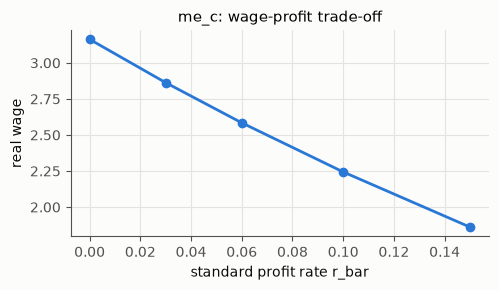

In [8]:
rows = []
for rb in (0.0, 0.03, 0.06, 0.10, 0.15):
    o, _ = me_c.simulate(T=400, g_gamma=0.0, r_bar=rb)
    rows.append((rb, o['real_wage'][300:].mean(), o['E'][300:].mean(), o['xL'][300:].mean()))
print('  r̄     実質賃金   働く人   贅沢品の量')
for rb, rw, E, xL in rows:
    print(f'  {rb:.2f}   {rw:7.3f}   {E:6.0f}   {xL:8.0f}')
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot([r[0] for r in rows], [r[1] for r in rows], 'o-', color=PAL[0])
ax.set(xlabel='standard profit rate r_bar', ylabel='real wage', title='me_c: wage-profit trade-off')
plt.tight_layout(); plt.show()

**r̄ が高いほど、実質賃金も雇用も贅沢品も下がる**。スラッファの賃金と利潤の取り換え(ノート 1 第 8.3 節)が、この模型でも出る。r̄ は経済の中では決まらず、金利と信用から与えるのが自然である。ここが、me_c を信用循環モデルとつなぐ入口になる(第 3 章で、r̄ を貸出の金利から与える)。

もう一つ、作者の元の関心だった「危機時の生産」の、me_c での姿を見ておく。必需品の生産能力を一度に半分にする。

In [9]:
e2 = me_c.Economy(g_gamma=0.0)
rec = []
for t in range(260):
    if t == 200:
        e2.K[0] *= 0.5
    rec.append(e2.step())
s = {k: np.array([r[k] for r in rec]) for k in ('PN', 'real_wage', 'E', 'uN', 'KN')}
print(f"打撃の前: 必需品の価格 {s['PN'][190:200].mean():.2f}、実質賃金 {s['real_wage'][190:200].mean():.2f}、働く人 {s['E'][190:200].mean():.0f}")
print(f"打撃の年: 稼働率 {s['uN'][200]:.2f}、必需品の価格 {s['PN'][200]:.2f}、実質賃金 {s['real_wage'][200]:.2f}、働く人 {s['E'][200]:.0f}")
print(f"5 年後の必需品の能力 / 打撃の前: {s['KN'][205] / s['KN'][199]:.2f}")

打撃の前: 必需品の価格 1.06、実質賃金 2.59、働く人 676


打撃の年: 稼働率 1.50、必需品の価格 1.42、実質賃金 1.93、働く人 472
5 年後の必需品の能力 / 打撃の前: 1.07


能力が半分になると、稼働率が 1 を大きく超え、残業の割増で費用が上がり、必需品の価格が上がって実質賃金が下がる。それでも、高い利潤率で投資が急増し、数年で能力が戻る。me_c の中では、「どの企業も作りたがらない」ことは起きない。それが起きるのは、価格に上限があるとき(第 7 章)である。

### 1.2 v6b: 資産市場つきの信用循環モデル、家計は「標本」

信用循環モデル v6(公開済みのリポジトリ credit_simulation_v6)は、銀行の預金と貸出、国債、株式的な富 E、分配の集中 Φ と実効準備率 ρ_eff を持つマクロの模型だった。物価はなく、家計は二つの階級にまとめていた。v6b は、それに、ノート 2 で立て直した 2019 年の資産市場(土地と知財と借金)を足し、家計の分布を「標本」として持つようにした模型である。

**マクロ**(人口 Npop の経済。一期 = 一年、物価の水準は 1 に固定):

- **企業**(一つにまとめた部門): 資本 K(生産能力 K/v)と借入 L_f を持つ。株式的な富 E = 期待利潤 / (貸出の金利 + 上乗せ)(v6 と同じ)。E が縮むと資本の損耗が増える。投資は利潤率と稼働率と q に反応し、足りない分は借りる。借入には担保の上限 λ(E + K) がかかる。
- **支払い**: 賃金 ωY、地代 ρ_T Y(土地の持ち主へ)、知財の使用料(操業利潤の φ_R を知財の持ち主へ)、利子、配当。
- **銀行**: 資産は企業への貸出、家計への貸出、国債。負債は家計の預金。自己資本は 0 に保つ(利益も損失も、持分に応じて家計へ)。金利は、貸出 = 政策金利 + 上乗せ、預金と国債 = 政策金利。
- **政府**: 支出、失業者への給付、家計の所得への税、国債(銀行が持つ)。
- **帳簿**: 家計部門のお金は、銀行の自己資本が 0 なので、いつも「企業の借入 + 国債」に等しい。マクロの帳簿だけで閉じる。

**家計の資産**(ノート 2 から):

- **土地**(減耗しない、総量一定): 値段は、借りて払える買い手の望む保有(正味資産の割合。割合は地代の利回りと値上がりの期待で動く)の和が総量に等しくなるように、二分法で解く。土地は担保になる(Kiyotaki–Moore の回路)。
- **知財**(減耗する): 家計の贅沢品の支出のうち「自主研究」の分から生まれ、企業から使用料を受け取る。
- **借入の上限**: 担保の上限と、稼ぎに応じた無担保の上限。上限を超えたら土地を売り、それでも足りなければ借金は棒引き(貸倒れ)になる。
- 世代の入れ替わりと相続。

**標本**(ミクロ): JRF は、ここで次のように考えた(2026-10-27)。

> 個人の主体を持つミクロの経済をマクロに「直接」統合するのは、本来理想的でない。個人の経済は「標本」として扱い、そこで得られた統計の量をマクロに反映させるべきではないか。物理学でもミクロとマクロを統合するが、直接ガッチャンコはしない。

v6b の家計は、人口の全員ではなく、Ns 人の**標本**である。一人は、人口の Npop / Ns 人を代表する。標本の大きさは、人口と関係なく選べる。

- **制限**(ミクロ → マクロ): 標本で「ミクロの実験」をして、マクロが使う関係式(構成則)を推定する。たとえば、所得を三つの値に置いたときの一人あたりの贅沢品の消費から、所得への応答の二次式を当てはめる。マクロは、この関係式だけを使って、所得 Y = 消費 + 投資 + 政府の支出 を解く。土地の需要曲線(値段ごとの望む保有)、貸倒れの率、預金と借金の総額も、標本から推定する。
- **持ち上げ**(マクロ → ミクロ): 毎期、標本の平均を、マクロの一人あたりの量(お金、土地、知財)に合わせ直す。だから、標本の誤差はマクロに積もらない。標本の一人ひとりは、マクロの「場」(賃金、雇用の率、地代、使用料、配当、金利、税率、土地の値段)のもとで動く。

物理学の多重スケールの方法(E と Engquist の heterogeneous multiscale method、Kevrekidis らの equation-free の方法)が、マクロの方程式の閉じていない部分(流体の応力とひずみの関係など)を、小さなミクロの模擬計算で補うのと同じ形である。経済学では、Krusell と Smith(1998)の近似集計が近い。計算の量は標本の大きさだけで決まり、人口によらない(人口を 10³ から 10⁷ にしても、一人あたりの量も計算の時間も同じだった)。

v6b の全文を、ファイル `v6b.py` に書き出しておく(一つのファイルで動くように、既定の値と小さな補助の関数も含めた)。

In [10]:
%%writefile v6b.py
"""v6b.py -- 資産市場つきの信用循環モデル v6。家計は「標本」として扱い、その統計だけをマクロに渡す(ノート 4 第 1 章)。

個人とマクロを「直接」つながず(個人の和をマクロの量にしない)、二つを分ける(物理学の多重スケールの方法: 制限 restriction と持ち上げ lifting。Kevrekidis らの equation-free、
E と Engquist の heterogeneous multiscale method。経済学では Krusell と Smith の近似集計に近い)。

* マクロ: 人口 Npop(連続量)の経済。企業・銀行・政府は v6 の骨格(株式的な富 E、損耗の増幅、投資の規則、担保の上限)に、地代と知財の使用料を足したもの。家計部門のお金は、銀行の自己資本が 0 なので、
  いつも M_h = L_f + B(マクロの帳簿だけで閉じる)。土地の総量、知財の総量もマクロの量として持つ。
* ミクロ: Ns 人の「標本」。一人は人口の Npop / Ns 人を代表する。標本の大きさは Npop と独立に選べる。
* 制限(ミクロ → マクロ): 標本で「ミクロの実験」をして、マクロが使う関係式を推定する。
    - 一人あたりの贅沢品の消費の、所得 Y への応答(三つの Y で標本を動かし、二次式を当てはめる)
    - 土地の需要曲線(価格の格子で、標本の望む保有を数える)
    - 借入の上限を超える人の割合と額(貸倒れの率)、預金と借金の総額の比
* 持ち上げ(マクロ → ミクロ): 毎期、標本の平均を、マクロの総量(一人あたりのお金、土地、知財)に合わせ直す。
  だから、標本の誤差はマクロに積もらない。標本は、マクロの「場」(賃金の水準、雇用の率、地代、使用料、配当、金利、税率、土地の値段)
  のもとで、一人ずつ動く。
"""
import numpy as np

DEFAULT_A = dict(   # 信用循環モデルの部門と、土地・知財の市場の既定の値
    
    N=1000, T=150, burn=150, seed=0,
    a=1.0,          # 一人あたりの生産(雇用 = Y / a)
    v=2.5,          # 資本係数: 生産能力 Y_p = u_max K / v
    u_max=1.1,
    omega=0.6,      # 賃金分配率
    rho_T=0.05,     # 地代: 所得 Y のこの割合を、土地の持ち主に払う
    phi_R=0.05,     # 知財の使用料: 操業利潤のこの割合を、知財の持ち主に払う
    d0=0.05,        # 平時の損耗率
    kappa=3.0,      # E が縮むときの損耗の増幅
    f_R=0.5,        # 純投資(I − δ0 K)のうち、内部留保で賄う割合。利潤のうち、それを除いた残りを配当にする
    g0=-0.02, g1=0.75, g2=0.1, g_q=0.0, q_ref=0.9,   # 投資の規則(v6 と同じ形。g2 は稼働率 u − 0.85 への反応)
    prem=0.02,      # E を評価するときのリスクプレミアム
    lam=0.6,        # 企業の担保の上限 λ(E + K)
    T_adj=2.0,      # 上限を超えたときの返済の速さ(年)
    tau_e=2.0,      # 期待利潤の適応の時定数
    default_share=0.5,
    r_cb=0.03, spread=0.01,
    gG=0.15,        # 政府支出 G = gG × 生産能力 / u_max
    tau=0.25,       # 税率(賃金・地代・使用料・配当・預金利子に)
    fiscal=0.05,    # 財政ルール: 税率を (B/Y − b_target) に比例して上げる強さ(v6 と同じ形)
    b_target=0.6,
    u_b=0.3,        # 失業者への給付(一人)
    n_c=0.3,        # 必需品(一人、実物の単位)
    c_y=0.8,        # 可処分所得の余りからの贅沢品の消費性向
    c_m=0.05,       # 預金からの贅沢品の消費性向
    c_h=0.005,      # 土地の値打ち(借金を引いた分)からの贅沢品の消費性向(資産効果)
    sigma_R=0.1,    # 贅沢品のうち、自主研究にあてる割合
    eta=1.0,        # 自主研究一単位が生む知財
    delta_IP=0.2,   # 知財の陳腐化の率
    T_land=1000.0,  # 土地の総量
    theta0=0.15, theta1=3.0,   # 土地に置きたい財産の割合 θ = θ0 exp(θ1 x)、x = 地代の利回り + 値上がりの期待 − 貸出金利(±0.2 で頭打ち)
    nu=0.2,         # 値上がりの期待の適応の速さ(外挿)
    chi=0.2,        # 望む土地へ、一期に近づく割合
    turnover=0.025, # 毎年、この割合の人が去り、財産のない若い人と入れ替わる(世代の入れ替わり)
    inherit='random',  # 去った人の財産の行き先: 'random'(くじで他の一人)、'equal'(全員に等しく)
    h_y=10.0,       # 土地の望む量に数える「稼ぐ力」(労働所得の何年分か。住宅ローンで買う働き手の需要)
    lam_T=0.6,      # 土地の担保の掛け目
    mu_u=0.5,       # 無担保で借りられる上限(平均の賃金の何年分か)
    shocks=(),      # [(年, {パラメータ: 値}, かける年数)]
)


def _softmin(a, b, w):
    return -w * np.logaddexp(-a / w, -b / w)


def _sp(x, w):
    return w * np.logaddexp(0.0, x / w)


def gini(x):
    x = np.sort(np.asarray(x, float))
    x = x - min(0.0, x.min())
    n = len(x)
    return (2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum())



DEFAULT = dict(DEFAULT_A, Npop=1000.0, Ns=1000, T_land_pc=1.0)
REC = ['tau', 'u', 'Y', 'C', 'I', 'G', 'K', 'L_f', 'B', 'E', 'q', 'delta', 'p_T', 'HL', 'D', 'theta', 'gT_e', 'emp',
       'wo_f', 'wo_h', 'lux', 'res', 'IP', 'Pi', 'gini_nw', 'top10_nw', 'fit_err', 'land_err']


class Sample:
    """ミクロの標本。量はすべて「一人あたり」の単位(平均がマクロの一人あたりの量に一致するように持ち上げる)。"""

    def __init__(self, p, rng, M_pc, IP_pc):
        Ns = p['Ns']
        self.Ns, self.rng = Ns, rng
        m = rng.exponential(1.0, Ns); self.m = m / m.mean() * M_pc
        ld = rng.exponential(1.0, Ns); self.land = ld / ld.mean() * p['T_land_pc']
        ip = rng.exponential(1.0, Ns); self.ip = ip / ip.mean() * IP_pc
        eq = rng.exponential(1.0, Ns) ** 2; self.eq = eq / eq.mean()      # 持分(平均 1。人口全体の配当を一人あたりに割ったものに掛ける)
        self.order = np.arange(Ns)

    def lift(self, M_pc, T_pc, IP_pc):
        """持ち上げ: 標本の平均をマクロの一人あたりの量に合わせる。お金は全員を同じ額だけずらし(散らばりを保つ)、
        土地と知財は比で合わせる。"""
        self.m += M_pc - self.m.mean()
        if self.land.mean() > 0:
            self.land *= T_pc / self.land.mean()
        if self.ip.mean() > 0:
            self.ip *= IP_pc / self.ip.mean()

    def incomes(self, f):
        """マクロの場 f のもとでの、一人ずつの所得と贅沢品の消費。f は一人あたりの量の dict。"""
        p = f['p']
        Ns = self.Ns
        n_emp = f['e'] * Ns                                   # 雇用の率 × 標本の人数(端数は、境目の一人が一部だけ働く)
        k = int(np.floor(n_emp)); frac = n_emp - k
        work = np.zeros(Ns); work[self.order[:k]] = 1.0
        if k < Ns:
            work[self.order[k]] = frac
        HL0 = np.maximum(-self.m, 0.0); D0 = np.maximum(self.m, 0.0)
        inc_w = work * f['wage']
        inc_u = (1 - work) * p['u_b']
        inc_T = f['rent'] * self.land
        inc_R = f['roy'] * self.ip
        inc_d = f['div'] * self.eq
        inc_i = f['r_D'] * D0 - f['r_L'] * HL0
        taxable = inc_w + inc_T + inc_R + np.maximum(inc_d, 0.0) + f['r_D'] * D0
        tax = f['tau'] * taxable
        y_d = inc_w + inc_u + inc_T + inc_R + inc_d + inc_i - tax
        lux = p['c_y'] * np.maximum(0.0, y_d - p['n_c']) + p['c_m'] * D0 + p['c_h'] * np.maximum(0.0, f['p_T'] * self.land - HL0)
        return dict(work=work, inc=inc_w + inc_u + inc_T + inc_R + inc_d + inc_i - tax, lux=lux, tax=tax, HL0=HL0, D0=D0,
                    labor=(inc_w + inc_u) * (1 - f['tau']))


class Economy:
    def __init__(self, **kw):
        p = dict(DEFAULT, **kw)
        self.p = p
        self.rng = np.random.default_rng(p['seed'])
        Np = p['Npop']
        self.T_land = p['T_land_pc'] * Np
        self.K = p['v'] * 0.9 * p['a'] * Np / 0.9
        self.L_f = 0.3 * self.K
        self.B = 0.6 * 0.9 * p['a'] * Np
        self.IP = 1.0 * Np
        self.S = Sample(p, self.rng, (self.L_f + self.B) / Np, self.IP / Np)
        self.p_T = 1.0
        self.gT_e = 0.0
        Y0 = 0.9 * p['a'] * Np
        self.Pi_e = (1 - p['omega'] - p['rho_T']) * Y0 - p['d0'] * self.K - (p['r_cb'] + p['spread']) * self.L_f
        self.Pi_prev = self.Pi_e
        self.E_prev = None
        self.Y_prev = Y0
        self.HL_share = 0.0                                   # 標本から推定した、家計の借金の総額(一人あたり)
        self.t = 0
        self._shock_base = {}

    def apply_shocks(self):
        p = self.p
        for k_, (ts, ch, dur) in enumerate(p['shocks']):
            if self.t >= ts:
                base = self._shock_base.setdefault(k_, {k: p[k] for k in ch})
                w = 1.0 if dur <= 0 else min(1.0, (self.t - ts + 1) / dur)
                for k, v in ch.items():
                    p[k] = base[k] + w * (v - base[k])

    def fields(self, Y, tau, I, r_L, r_D):
        """所得 Y のもとでの、マクロの一人あたりの「場」。"""
        p = self.p; Np = p['Npop']
        e = min(1.0, Y / (p['a'] * Np))
        W = p['omega'] * Y
        R_T = p['rho_T'] * Y
        OP = Y - W - R_T - p['d0'] * self.K
        Roy = p['phi_R'] * max(OP, 0.0)
        Pi = OP - Roy - r_L * self.L_f
        div_f = Pi - p['f_R'] * (I - p['d0'] * self.K)
        return dict(p=p, e=e, W=W, R_T=R_T, OP=OP, Roy=Roy, Pi=Pi, div_f=div_f,
                    wage=W / max(e * Np, 1e-9), rent=R_T / self.T_land, roy=Roy / max(self.IP, 1e-9),
                    div=(div_f + self.pi_b_pre) / Np, r_D=r_D, r_L=r_L, tau=tau, p_T=self.p_T)

    def step(self):
        p = self.p
        self.apply_shocks()
        Np = p['Npop']
        r_L = p['r_cb'] + p['spread']; r_D = r_B = p['r_cb']
        K, L_f, B = self.K, self.L_f, self.B
        M = L_f + B                                           # 家計部門のお金(マクロの帳簿)
        # 0. 持ち上げ
        self.S.lift(M / Np, self.T_land / Np, self.IP / Np)
        S = self.S
        # 1〜2. E、損耗、投資(マクロだけ)
        disc = r_L + p['prem']
        E = _sp(self.Pi_e, 0.001 * K) / (_sp(disc, 0.005) + 0.005)
        delta = p['d0']
        if self.E_prev is not None:
            delta = p['d0'] * (1 + p['kappa'] * max(0.0, -(E - self.E_prev) / max(self.E_prev, 1e-9)))
        self.E_prev = E
        u_prev = self.Y_prev / (K / p['v'])
        g_net = p['g0'] + p['g1'] * self.Pi_prev / K + p['g2'] * (u_prev - 0.85) + p['g_q'] * (E / K - p['q_ref'])
        I_des = K * max(0.0, p['d0'] + g_net)
        bor_des = (1 - p['f_R']) * (I_des - p['d0'] * K)
        bor = _softmin(bor_des, (p['lam'] * (E + K) - L_f) / p['T_adj'], 0.01 * K)
        I = max(0.0, p['d0'] * K + bor / (1 - p['f_R']))
        Y_p = _softmin(p['u_max'] * K / p['v'], p['a'] * Np, 0.01 * p['a'] * Np)
        G = p['gG'] * Y_p / p['u_max']
        tau = min(max(p['tau'] + p['fiscal'] * (B / self.Y_prev - p['b_target']), 0.0), 0.8)
        # 銀行の利子の利益(貸倒れの前)。家計の預金と借金の総額は、標本の分布から推定する
        HL_pc = np.maximum(-S.m, 0).mean(); D_pc = np.maximum(S.m, 0).mean()
        self.pi_b_pre = r_L * (L_f + HL_pc * Np) + r_B * B - r_D * D_pc * Np
        # 3. 制限: 標本で「ミクロの実験」をして、一人あたりの贅沢品の消費の Y への応答を二次式で推定する
        Ys = self.Y_prev * np.array([0.85, 1.0, 1.15])
        lux_pc = [S.incomes(self.fields(y, tau, I, r_L, r_D))['lux'].mean() for y in Ys]
        coef = np.polyfit(Ys, lux_pc, 2)
        lux_fn = lambda y: max(np.polyval(coef, y), 0.0)
        # マクロの所得の決定(推定した関係式だけを使う)
        Y = self.Y_prev
        for _ in range(200):
            C = Np * (p['n_c'] + lux_fn(Y))
            Yd = C + I + G
            Y_new = max(_softmin(Yd, Y_p, 0.01 * Y_p), 1e-9)
            if abs(Y_new - Y) < 1e-10 * Y:
                Y = Y_new; break
            Y = 0.5 * Y + 0.5 * Y_new
        f = self.fields(Y, tau, I, r_L, r_D)
        gap = max(0.0, Yd - Y)
        lux_tot = Np * lux_fn(Y)
        if gap > 0 and lux_tot > 0:
            lux_tot *= max(0.0, 1 - gap / lux_tot)
        C = Np * p['n_c'] + lux_tot
        Y = C + I + G
        f = self.fields(Y, tau, I, r_L, r_D)
        # 標本を、その場で一期動かす(推定の誤差を測るため、標本自身の贅沢品の消費も記録する)
        mi = S.incomes(f)
        lux_s = mi['lux'].mean()
        scale = (lux_tot / Np) / lux_s if lux_s > 0 else 1.0      # 標本の消費を、マクロの消費の総量に合わせる(制限と持ち上げの整合)
        lux_i = mi['lux'] * scale
        fit_err = (lux_s - lux_tot / Np) / max(lux_tot / Np, 1e-9)
        S.m = S.m + mi['inc'] - (p['n_c'] + lux_i)
        res_i = p['sigma_R'] * lux_i
        S.ip = S.ip * (1 - p['delta_IP']) + p['eta'] * res_i
        self.IP = self.IP * (1 - p['delta_IP']) + p['eta'] * p['sigma_R'] * lux_tot
        # 4〜6. マクロの帳簿: 企業、政府(税はマクロの所得の流れから)
        W, R_T, Roy, Pi, div_f = f['W'], f['R_T'], f['Roy'], f['Pi'], f['div_f']
        n_emp = f['e'] * Np
        D0_tot = D_pc * Np
        div_tot = div_f + self.pi_b_pre
        tax_tot = tau * (W + R_T + Roy + max(div_tot, 0.0) + r_D * D0_tot)
        dL_f = I + W + R_T + Roy + r_L * L_f + div_f - Y
        CF = Y - W - R_T - r_L * L_f
        wo_f = min(p['default_share'] * max(0.0, -CF), 0.5 * L_f)
        U = p['u_b'] * (Np - n_emp)
        dB = G + U + r_B * B - tax_tot
        # 7. 土地の市場: 標本の需要曲線(一人あたり)× 人口 = 土地の総量 となる値段を、マクロが解く
        wbar = W / max(n_emp, 1e-9)
        U_lim = p['mu_u'] * wbar
        v_IP = Roy / (max(self.IP, 1e-9) * (r_L + p['delta_IP']))
        y_T = R_T / self.T_land / self.p_T
        x_T = 0.2 * np.tanh((y_T + self.gT_e - r_L) / 0.2)
        theta = float(min(p['theta0'] * np.exp(p['theta1'] * x_T), 0.9))
        other = S.m + v_IP * S.ip + (E / Np) * S.eq
        human = p['h_y'] * mi['labor']
        land, chi, lT = S.land, p['chi'], p['lam_T']

        def holdings(pr):
            nw = other + pr * land
            d = np.maximum(0.0, theta * (nw + human) / pr)
            cap = (U_lim + S.m + pr * land) / ((1 - lT) * pr)
            return np.clip(land + chi * (d - land), 0.0, np.maximum(cap, 0.0))
        T_pc = self.T_land / Np
        lo, hi = np.log(self.p_T) - 8, np.log(self.p_T) + 8
        for _ in range(100):
            mid = 0.5 * (lo + hi)
            if holdings(np.exp(mid)).mean() > T_pc:
                lo = mid
            else:
                hi = mid
        pT = float(np.exp(0.5 * (lo + hi)))
        new = holdings(pT)
        land_err = new.mean() / T_pc - 1
        new = new * (T_pc / new.mean())
        S.m = S.m - pT * (new - land)
        S.land = new
        self.gT_e += p['nu'] * (np.log(pT / self.p_T) - self.gT_e)
        self.p_T = pT
        # 8. 貸倒れの率を標本から推定し、マクロの額にする
        limit = lT * pT * S.land + U_lim
        over = np.maximum(0.0, -S.m - limit)
        wo_h = over.mean() * Np
        S.m = S.m + over
        S.m = S.m - (wo_f + wo_h) / Np * S.eq                   # 銀行の損失を持分に応じて負担(一人あたり)
        # 10. マクロのストック
        self.L_f = L_f + dL_f - wo_f
        self.B = B + dB
        self.K = max(K + I - delta * K, 1e-3)
        self.Pi_e += (Pi - self.Pi_e) / p['tau_e']
        self.Pi_prev = Pi
        self.Y_prev = Y
        # 世代の入れ替わり(標本の中で)
        n_out = self.rng.binomial(S.Ns, p['turnover']) if p['turnover'] > 0 else 0
        for i in (self.rng.choice(S.Ns, n_out, replace=False) if n_out else []):
            h = self.rng.integers(S.Ns - 1); h = h + (h >= i)
            for arr in (S.m, S.land, S.ip, S.eq):
                arr[h] += arr[i]; arr[i] = 0.0
        S.eq *= 1.0 / S.eq.mean()
        k = int(round(f['e'] * S.Ns))
        S.order = np.concatenate([self.rng.permutation(S.order[:k]), self.rng.permutation(S.order[k:])])
        self.t += 1
        nw = S.m + pT * S.land + v_IP * S.ip + (E / Np) * S.eq
        srt = np.sort(nw)
        return dict(tau=tau, u=Y / (K / p['v']), Y=Y, C=C, I=I, G=G, K=self.K, L_f=self.L_f, B=self.B, E=E, q=E / K, delta=delta,
                    p_T=pT, HL=HL_pc * Np, D=D_pc * Np, theta=theta, gT_e=self.gT_e, emp=f['e'], wo_f=wo_f, wo_h=wo_h,
                    lux=lux_tot, res=p['sigma_R'] * lux_tot, IP=self.IP, Pi=Pi, gini_nw=gini(nw),
                    top10_nw=srt[-max(S.Ns // 10, 1):].sum() / srt.sum(), fit_err=fit_err, land_err=land_err)


def simulate(**kw):
    """予備走行(burn 年)のあと T 年回し、記録の列の辞書と経済を返す。"""
    p = dict(DEFAULT, **kw)
    shocks = p['shocks']
    e = Economy(**dict(kw, shocks=()))
    for _ in range(p['burn']):
        e.step()
    e.p['shocks'] = [(ts + e.t, ch, dur) for ts, ch, dur in shocks]
    out = {k: np.empty(p['T']) for k in REC}
    for t in range(p['T']):
        r = e.step()
        for k in REC:
            out[k][t] = r[k]
    return out, e

Overwriting v6b.py


持ち上げは、次の数行である。お金は全員を同じ額だけずらし(散らばりを保つ)、土地と知財は比で合わせる。

In [11]:
import v6b
print(inspect.getsource(v6b.Sample.lift))

    def lift(self, M_pc, T_pc, IP_pc):
        """持ち上げ: 標本の平均をマクロの一人あたりの量に合わせる。お金は全員を同じ額だけずらし(散らばりを保つ)、
        土地と知財は比で合わせる。"""
        self.m += M_pc - self.m.mean()
        if self.land.mean() > 0:
            self.land *= T_pc / self.land.mean()
        if self.ip.mean() > 0:
            self.ip *= IP_pc / self.ip.mean()



この二つの操作で、総額がマクロに一致し、散らばりが保たれることを、Lean で確かめておく(重みつきの標本の版。im の標本は、記入ごとに人数 h_i を持つ)。

In [12]:
%%writefile -a integrated_model.lean
/-! ## 第 1 章 標本の家計: 制限と持ち上げ

持ち上げ(lifting)は、標本の記入の量 m_i を、マクロの総額 M に合わせ直す。
人数 h_i に比例してずらしても(預金)、比で掛けても(土地・知財)、和は M になる。 -/

/-- 人数に比例してずらす持ち上げ: Σ (m_i + h_i (M − Σm) / Σh) = M。 -/
theorem lift_shift_sum {ι : Type*} (s : Finset ι) (m h : ι → ℝ) (M : ℝ) (hH : (∑ i ∈ s, h i) ≠ 0) :
    ∑ i ∈ s, (m i + h i * ((M - ∑ j ∈ s, m j) / ∑ j ∈ s, h j)) = M := by
  rw [Finset.sum_add_distrib, ← Finset.sum_mul, mul_div_assoc', mul_div_cancel_left₀ _ hH]
  ring

/-- 比で掛ける持ち上げ: Σ x_i · (M / Σx) = M。 -/
theorem lift_ratio_sum {ι : Type*} (s : Finset ι) (x : ι → ℝ) (M : ℝ) (hX : (∑ i ∈ s, x i) ≠ 0) :
    ∑ i ∈ s, x i * (M / ∑ j ∈ s, x j) = M := by
  rw [← Finset.sum_mul, mul_div_cancel₀ _ hX]

/-- 人数に比例してずらしても、同じ人数の二つの記入の差(散らばり)は変わらない。 -/
theorem lift_keeps_gap (mi mj h c : ℝ) : (mi + h * c) - (mj + h * c) = mi - mj := by ring

Appending to integrated_model.lean


標本の大きさで、何が変わるか。人口 1000 の経済で、標本を人口と同じ 1000 人にした場合を基準に、標本 25 人・100 人・500 人を比べる(定常の 40 年の平均、種 4 個)。

In [13]:
def steady(a):
    kw, seed = a
    o, _ = v6b.simulate(T=60, seed=seed, **kw)
    return {k: float(o[k][20:].mean()) for k in ('Y', 'p_T', 'HL', 'gini_nw', 'top10_nw')}

print('  標本                   生産 Y              土地の値段        家計の借金       正味資産の Gini    上位 10% の取り分')
for ns in (1000, 500, 100, 25):
    R = nt.pmap(steady, [(dict(Ns=ns), s) for s in range(4)])
    lab = f'{ns} 人' + ('(人口と同じ、基準)' if ns == 1000 else '')
    print(f'  {lab:20s}' + ''.join(f'  {np.mean([r[k] for r in R]):8.3f}±{np.std([r[k] for r in R]):6.3f}'
                                   for k in ('Y', 'p_T', 'HL', 'gini_nw', 'top10_nw')))

  標本                   生産 Y              土地の値段        家計の借金       正味資産の Gini    上位 10% の取り分


  1000 人(人口と同じ、基準)       901.464± 0.127     1.267± 0.000    93.424± 0.268     0.715± 0.001     0.692± 0.004


  500 人                  901.605± 0.097     1.266± 0.000    94.282± 2.858     0.716± 0.002     0.692± 0.005


  100 人                  901.562± 0.375     1.269± 0.001    94.265± 4.898     0.731± 0.012     0.679± 0.014


  25 人                   902.511± 0.891     1.268± 0.003   105.180± 8.129     0.741± 0.015     0.579± 0.071


**マクロの量(生産、土地の値段)は、標本 25 人でも 0.1% ほどの精度で基準に一致する**。一方、**分布の量(家計の借金、Gini、上位の取り分)は、標本を大きくしないと定まらない**。上位 10% の取り分は、小さい標本では低く出る(偏り)。何を標本から取るかで、要る標本の大きさが違う。平均で決まる量は小さな標本で足り、分布の裾で決まる量(貸倒れ、上位の取り分)は大きな標本が要る。危機の分析は、まさに裾の量で決まるので、ここが弱点になる。

### 1.3 im の家計: 重みつきの標本

im の家計は、v6b の考えを一歩進めた**重みつきの標本**である。

- 一つの**記入**が、人数 h_i の世帯の集まりを代表する(量は、その集まりの合計で持つ)。全体の人数は約 1000(労働者 1000、資本家 5 の me_c の人口)。
- 記入ごとに、預金(負なら借金)、労働の取り分、持分(株)の取り分、土地、知財などを持つ。**労働者と資本家の二つの階級は置かず**、記入ごとの「所得のうち資産所得の割合」の分布として連続に持つ(JRF の決定)。消費性向は、その割合で労働者の値と資本家の値のあいだを動く。
- マクロの帳簿(家計部門の預金の総額など)は、標本の和に頼らずに閉じる。標本の和とマクロの総額の差(**帳簿と標本の差**)は、毎年記録して、関門で確かめる。
- **重点標本化**: 重みを変えれば、危ない層(借金の上限に近い記入)を多めに取れる。毎年、危ない記入を二つに分け(重みは半分ずつ)、似た安全な記入を二つ併せる。分けた二つは、そのあとの乱数で別々の道をたどる。ノート 3 で、一家離散のような裾の量の推定の分散を小さくするのに使った方法の、im の版である。

標本の重みを変えても、マクロの量が変わらないことを、関門(`test_im.py`)で確かめている。記入をそれぞれ二つの同じ記入に分けて(重みは半分)回すと、同じ数になる。ただし、世代の入れ替わり(去る世帯の財産を、くじで選んだ相続人に渡す)は乱数を使い、記入の数が変わると引く乱数の道が変わるので、確かめるときは入れ替わりを切る。

In [14]:
x, _ = im1.simulate(T=50, **dict(BASE, Ns=300, turnover=0.0))
y, _ = im1.simulate(T=50, **dict(BASE, Ns=300, turnover=0.0), split=2)
print('記入を二つずつに分けたときの、雇用・賃金・必需品の価格の相対のずれの最大:',
      f"{max(np.max(np.abs(x[k] - y[k]) / (np.abs(x[k]) + 1)) for k in ('E', 'W', 'PN')):.1e}")

記入を二つずつに分けたときの、雇用・賃金・必需品の価格の相対のずれの最大: 2.2e-11


### 1.4 この章のまとめ

- me_c は、作者の「価格を最適化で決める」を、三本の均衡の条件の残差の最小化として残した。生産能力を連続にすると、利潤率の均等化が能力の増減から出てきて、企業の数の飽和はなくなる。r̄ は外から与える必要があり、それが信用とつなぐ入口になる。
- v6b は、家計を標本として持ち、制限と持ち上げでマクロとつなぐ。マクロの量は小さな標本で足りるが、分布の裾の量は大きな標本か、重点標本化が要る。
- im は、me_c の価格と生産をマクロの骨格にし、v6b の考えで、家計を重みつきの標本にする。次の章では、その二つをつなぐ帳簿の骨組みを作る。

---

## 第 2 章 帳簿の骨組み

部品をたくさん差し込んでいくと、どこかでお金が湧いたり消えたりしやすい。たとえば、誰かの支払いが誰の所得にもならない、借金を棒引きにしたのに貸し手の損を書き忘れる、といった誤りである(ノート 3 で読んだ simbd の「死者の一家離散」も、二つの時計のずれから来る帳簿の誤りだった)。im では、それを防ぐために、すべての部品が**一つの帳簿**に書き込む形にした。これが段 0 である。

### 2.1 二つの表

帳簿は、ストック・フロー一貫の模型(Godley and Lavoie 2007)の二つの表を、そのままデータとして持つ。

- **部門の貸借の表**(ストック): 行が金融の手段(預金、貸出、国債、外の資産)と実物の資産(資本、在庫、備蓄)、列が部門(家計、三つの企業、銀行、政府)。持ち主から見た符号で持つ(資産は正、負債は負)。金融の手段の行は、部門の和がいつも 0 になる(誰かの資産は誰かの負債)。
- **取引の流れの表**(フロー): 行が流れの名前(賃金、消費、利子、税、配当……)、列が部門。受け取りは正、支払いは負。どの行も、部門の和が 0 になる(すべての支払いに受け取り手がいる)。

部品は、次の四つの書き込み方だけを使う。

| 書き込み | 意味 | 例 |
|---|---|---|
| `pay(名前, 払う側, 受け取る側, 額)` | 経常の支払い。預金で決済する | 賃金、消費、利子、税、移転 |
| `trade(手段, 買う側, 売る側, 額)` | 金融の取引。預金で決済する | 銀行が企業に貸す、銀行が国債を買う |
| `produce_real(手段, 部門, 額)` | 実物の資産の増減(金融には効かない) | 投資による資本の増加、減耗 |
| `revalue(手段, 部門, 額)` | 取引でない評価の変化 | 値上がり、貸倒れの棒引き |

一年の終わりに、四つの恒等式を確かめる。

In [15]:
import inspect, im_core
print(inspect.getsource(im_core.Ledger.pay))
print(inspect.getsource(im_core.Ledger.check))

    def pay(self, name, frm, to, amount):
        """経常の支払い(賃金、消費、利子、税、移転など)。預金で決済する。"""
        if amount == 0:
            return
        self.flows[name][frm] -= amount
        self.flows[name][to] += amount
        self._move('deposits', frm, -amount)
        self._move('deposits', to, +amount)
        self._settle(frm, to, amount)

    def check(self, tol=1e-9):
        """帳簿の恒等式を確かめ、最大のずれを返す。
        (1) 経常の流れの各行は、部門の和が 0(すべての支払いに受け取り手がいる)。
        (2) 金融の手段の各列は、ストックの部門の和が 0。
        (3) ストックとフローの整合: 期末 = 期首 + 取引 + 評価の変化。
        (4) 部門ごとの予算: 経常の収支の和 = 金融の資産の取引による純増(預金を含む)。"""
        err = {}
        err['flow_rows'] = max([abs(sum(row.values())) for row in self.flows.values()], default=0.0)
        fin_instr = [i for i in self.instruments if i not in self.real]
        err['stock_cols'] = max(abs(sum(self.stock[(s, i)] for s in self.sectors)) for i in fin_instr)
        err['stock_flow'] = max(abs(self.stock[(s, i)] - self.open[(s, i)] - self.fin[i][s] - self.reval[i][s])
     

(1) 流れの各行の和が 0、(2) 金融の手段の各行(ストック)の和が 0、(3) 期末のストック = 期首 + 取引 + 評価の変化、(4) 部門ごとに、経常の収支の和 = 金融の資産の純増。どれか一つでも崩れれば、どこかでお金が湧いたか消えたかである。

この恒等式が、取引をいくつ重ねても保たれることは、Lean で証明できる(一つの取引は、払う側に −a、受け取る側に +a を書くので、部門の和は 0。取引の列についても帰納法で 0)。

In [16]:
%%writefile -a integrated_model.lean
/-! ## 第 2 章 帳簿の骨組み

一つの取引は、払う側から受け取る側へ額 a を動かす。どの部門 s についても、
取引ごとの増減(受け取りなら +a、支払いなら −a、どちらでもなければ 0)を足すと、部門の和は 0 になる。
取引をいくつ重ねても、和は 0 のまま。 -/

/-- 一つの取引の、部門 s への効き目。 -/
def entry {S : Type*} [DecidableEq S] (src dst : S) (a : ℝ) (s : S) : ℝ :=
  (if s = dst then a else 0) - (if s = src then a else 0)

theorem entry_sum_zero {S : Type*} [Fintype S] [DecidableEq S] (src dst : S) (a : ℝ) :
    ∑ s, entry src dst a s = 0 := by
  simp [entry, Finset.sum_sub_distrib]

/-- 取引の列(払う側、受け取る側、額)を重ねても、部門の和は 0。 -/
theorem ledger_sum_zero {S : Type*} [Fintype S] [DecidableEq S] (tx : List (S × S × ℝ)) :
    ∑ s, (tx.map fun x => entry x.1 x.2.1 x.2.2 s).sum = 0 := by
  induction tx with
  | nil => simp
  | cons x xs ih =>
    simp only [List.map_cons, List.sum_cons]
    rw [Finset.sum_add_distrib, ih, entry_sum_zero, add_zero]

Appending to integrated_model.lean


数値でも確かめる。でたらめな取引を 1 万件(5 年に分けて)書き込んでも、恒等式のずれは丸めの誤差だけである。

In [17]:
from test_im import test_ledger_random
print(f'でたらめな取引 1 万件のあとの、帳簿の恒等式のずれの最大: {test_ledger_random():.1e}')

でたらめな取引 1 万件のあとの、帳簿の恒等式のずれの最大: 1.4e-13


### 2.2 im の一年の帳簿

im の一年が、帳簿に実際に何を書き込むかを見ておく。基準の経済(標本の家計、信用、土地と知財)を 30 年回し、31 年目の帳簿を、閉じる前に取り出す。

In [18]:
def step_open(e):
    """im1 の一年を、帳簿を閉じる前まで進める(Im1.step と同じ手順。最後の close だけをしない)。"""
    inv, B = e.begin_year()
    price, sol = e.solve_prices(inv, B)
    x, u, geff, cost, m = e.evaluate(price, inv, B)
    qc = x[:2] if e._cx is None else np.array([e._cx['hhN'], x[1]])
    return e.finish_year(price, price, x, u, geff, cost, qc, float(np.linalg.norm(sol.fun[:3])))

e = im1.Im1(seed=0, **dict(BASE, Ns=500))
for _ in range(30):
    e.step()
rec = step_open(e)
L = e.L
names, F = L.flow_table()
secs = L.sectors
print('取引の流れの表(31 年目。受け取りは正、支払いは負。単位は名目)')
print('  ' + '流れ'.ljust(22) + ''.join(f'{s:>10s}' for s in secs) + '     行の和')
for n, row in zip(names, F):
    if np.abs(row).max() > 1e-9:
        print('  ' + n.ljust(22) + ''.join(f'{v:10.1f}' for v in row) + f'  {row.sum():9.1e}')
print('  ' + '列の和(経常の収支)'.ljust(18) + ''.join(f'{v:10.1f}' for v in F.sum(0)))
print()
print('部門の貸借の表(年末。資産は正、負債は負)')
Bt = L.balance_table()
print('  ' + '手段'.ljust(22) + ''.join(f'{s:>10s}' for s in secs) + '     行の和')
for inst, row in zip(L.instruments, Bt):
    if np.abs(row).max() > 1e-9:
        tag = '(実物)' if inst in L.real else ''
        print('  ' + (inst + tag).ljust(20) + ''.join(f'{v:10.1f}' for v in row) + (f'  {row.sum():9.1e}' if inst not in L.real else ''))
err = L.check(tol=None)
print()
print('恒等式のずれ:', {k: f'{v:.1e}' for k, v in err.items()})
print(f"家計の標本の預金の和 − 家計部門の預金(帳簿と標本の差): {rec['sample_gap']:.1e}")
L.close()

取引の流れの表(31 年目。受け取りは正、支払いは負。単位は名目)
  流れ                            hh        fN        fL        fI      bank       gov     行の和
  wages                    20039.6   -3523.1   -3834.2  -12682.3       0.0       0.0    1.8e-12
  consumption             -23985.5   14679.3    9306.2       0.0       0.0       0.0   -1.8e-12
  intermediate                 0.0   -6035.6   -3653.0    9688.6       0.0       0.0    0.0e+00
  investment goods             0.0   -2732.4   -1450.5    4182.9       0.0       0.0    0.0e+00
  loan interest              -59.4    -330.6    -143.0    -520.5    1053.5       0.0    0.0e+00
  dividends                 1961.6    -849.1    -344.1    -241.6    -526.7       0.0   -1.1e-13
  land rent                 1467.9   -1467.9       0.0       0.0       0.0       0.0    0.0e+00
  royalties                  181.9       0.0    -181.9       0.0       0.0       0.0    0.0e+00
  deposit interest           584.4       0.0       0.0       0.0    -584.4       0.0    0.0e+00
  bond in

家計(hh)の列は、標本のすべての記入をまとめた一つの部門である。標本の記入ごとの内訳(誰がいくら賃金を受け取り、いくら預金を持つか)は、帳簿の外の標本が持つ。毎年、標本の預金の和と、家計部門の預金が一致することを確かめる(**帳簿と標本の差**)。どの段の関門でも、この差は所得の 1e-12 以下だった。

流れの表の列の和は、部門ごとの収支(貯蓄 − 投資。金融の資産の純増)である。部門の収支を足すと 0 になる。誰かの黒字は誰かの赤字である。この年は、政府と原料の企業が黒字、家計と必需品・贅沢品の企業が赤字だった(家計は、預金を取り崩して消費し、企業は借りて投資した)。この「部門の収支の和は 0」(Godley の部門の収支)は、第 12 章で、積立の年金が倹約のパラドックスで崩れる理由になる。家計がみなで貯めようとしても、誰かがその分だけ赤字にならなければ、貯蓄は実現しない。

### 2.3 パラメータの登録簿

im のパラメータは、すべて登録簿に、名前・既定値・種類・説明とともに登録してある。種類は三つに分けた(PLAN の「ノート 4 への引き継ぎ」)。

- **政策のつまみ**(policy): 税と再分配、公共事業、金利、準備率、安全網、年金、価格の上限など。
- **行動の仮定**(behavior): 消費性向、投資の反応、貸し手の慎重さ、学習の速さ、注意の割合など。
- **構造**(structure): 技術、人口、部品を入れるかどうかのスイッチなど。

新しい部品は、どれも既定では切ってあり、切れば前の段と同じ数が出る(第 17 章の部品の表は、このスイッチの一覧から作る)。

In [19]:
from collections import Counter
P = im1.default_params()
cnt = Counter(prm.kind for prm in P._reg.values())
print(f"登録されたパラメータ: {len(P._reg)} 個(政策のつまみ {cnt['policy']}、行動の仮定 {cnt['behavior']}、構造 {cnt['structure']})")
print()
for name in ('tau0', 'r_cb', 'mu_prem', 'phi_r', 'phi_u', 'c_y', 'land', 'research', 'player'):
    prm = P._reg[name]
    print(f'  {prm.kind:9s} {name:9s} = {prm.value!r:8}  {prm.doc[:70]}')

登録されたパラメータ: 247 個(政策のつまみ 53、行動の仮定 99、構造 95)

  policy    tau0      = 0.2       税率の初期値
  policy    r_cb      = 0.02      政策金利(預金と国債の金利)。テイラー・ルールを入れたときは、その中立の値
  behavior  mu_prem   = 0.0       貸し手の慎重さ: 所得の集中 Φ が θ を超えた分に掛ける係数(ρ_eff の形)
  behavior  phi_r     = 0.5       投資の、利潤率の差への反応
  behavior  phi_u     = 0.3       投資の、稼働率の差への反応
  behavior  c_y       = 0.9       労働者の可処分所得からの消費性向
  structure land      = False     土地と知財の市場を入れるか
  structure research  = False     企業が研究する(探索)か。当たると最先端の技術が下がり、新しい生産能力に乗る
  structure player    = False     標本の中に、プレイヤーの記入(一人の世帯)を切り出す。規則の代わりに、外から選び方を与えられる(e.act)


### 2.4 骨組みの試験: ノート M の二財の模型

骨組みが正しく働くかを、すでに答えのわかっている模型で試した。ノート M 第 2 章の gj の模型(帳簿を閉じた二財。資本家の所得 = 赤字 ÷ 漏れの率)を、骨組みの上に書き直すと、元の模型と 13 通りの設定で一致した(最大のずれ 1e-15)。

In [20]:
from test_im import test_gj_equivalence
print(f'骨組みの上の gj と、ノート M の gj の最大のずれ(13 通り): {test_gj_equivalence():.1e}')

骨組みの上の gj と、ノート M の gj の最大のずれ(13 通り): 1.1e-15


この書き直しで、gj の仮定を一つ外して試した。gj では、労働者は貯めず、政府の赤字はすべて資本家の所得になる。労働者も貯める(年金基金などを通じて国債を持つ。Pasinetti 1962)ようにすると、資本家の所得は、もう赤字だけでは決まらない。一般のカレツキの式 (1 − ι)s·Mk + s_w·Mw = 赤字 が成り立ち、**労働者が貯めるほど、また再分配するほど、資本家の所得は減る**。ただし、赤字が同じまま労働者の貯蓄が加わると、漏れが増えて失業が大きくなる(倹約のパラドックス)。

In [21]:
record('stage0', 'E1')

E1 労働者の貯蓄 s_w と再分配 τ(国債は初め資本家が 1 持つ)
s_w=0.0 τ=0.0            L=0.800 unemp=0.200 Mw=0.800 Mk=0.160 I=0.040 pL=1.373 資本家の実質消費=0.058
s_w=0.0 τ=0.2            L=0.961 unemp=0.039 Mw=1.001 Mk=0.160 I=0.040 pL=1.373 資本家の実質消費=0.058
s_w=0.0 τ=0.4            L=1.000 unemp=0.000 Mw=1.107 Mk=0.160 I=0.040 pL=1.511 資本家の実質消費=0.053
s_w=0.05 τ=0.0           L=0.437 unemp=0.563 Mw=0.437 Mk=0.073 I=0.018 pL=1.373 資本家の実質消費=0.026
s_w=0.05 τ=0.2           L=0.464 unemp=0.536 Mw=0.480 Mk=0.064 I=0.016 pL=1.373 資本家の実質消費=0.023
s_w=0.05 τ=0.4           L=0.495 unemp=0.505 Mw=0.531 Mk=0.054 I=0.013 pL=1.373 資本家の実質消費=0.020
s_w=0.1 τ=0.0            L=0.295 unemp=0.705 Mw=0.295 Mk=0.042 I=0.010 pL=1.373 資本家の実質消費=0.015
s_w=0.1 τ=0.2            L=0.302 unemp=0.698 Mw=0.311 Mk=0.036 I=0.009 pL=1.373 資本家の実質消費=0.013
s_w=0.1 τ=0.4            L=0.309 unemp=0.691 Mw=0.328 Mk=0.029 I=0.007 pL=1.373 資本家の実質消費=0.010
一般のカレツキの式: (1 − ι)s·Mk + s_w·Mw = 赤字
  s_w=0.0: 左辺 0.040000、赤字 0.040000
  s_w=0.1: 左辺 0.040000、赤字 0.040000


カレツキの式そのものは、帳簿の恒等式から一行で出る。Lean で書いておく。

In [22]:
%%writefile -a integrated_model.lean
/-! ## 第 3 章 カレツキの式の一般化(労働者も貯めるとき)

資本家は所得 Mk の割合 s を貯め、その割合 ι を投資し、残りで国債を買う。
労働者は所得 Mw の割合 s_w を貯めて国債を買う。国債の発行は政府の赤字 D に等しい。
このとき (1 − ι) s Mk + s_w Mw = D。s_w = 0 なら、資本家の所得は D / ((1 − ι) s) に決まる(ノート M の gj_capitalist_income)。
s_w > 0 なら、労働者の所得が増えるほど、資本家の所得は減る(パシネッティの問題の形)。 -/
theorem kalecki_general {Mk Mw s ι sw D : ℝ}
    (hbonds : (Mk - (1 - s) * Mk - ι * s * Mk) + sw * Mw = D) :
    (1 - ι) * s * Mk + sw * Mw = D := by
  linarith

theorem kalecki_capitalist_income {Mk Mw s ι sw D : ℝ} (h : 0 < (1 - ι) * s)
    (hbonds : (1 - ι) * s * Mk + sw * Mw = D) :
    Mk = (D - sw * Mw) / ((1 - ι) * s) := by
  rw [eq_div_iff h.ne']
  linarith

Appending to integrated_model.lean


もう一つ、投資の利潤への反応(バドゥリ–マーグリン)を入れて、再分配の効き方を見た。**投資が利潤の取り分にあまり反応しなければ、再分配は雇用を増やし(賃金主導)、強く反応すれば減らす(利潤主導)**。境目は反応の強さ 0.5 と 1 のあいだにある。再分配が雇用を増やすか減らすかは、行動の仮定で逆になる。この結論は、価格と信用を入れた第 3 章でも、形を変えて残る。

In [23]:
record('stage0', 'E3')

E3 投資の関数(バドゥリ–マーグリン): I = i0 + i_h·h(h は税と再分配のあとの利潤の取り分)。基準 τ = 0.2 で I が gj と同じになるよう i0 を合わせる
  基準: 利潤の取り分 h = 0.138、投資 I = 0.040
i_h=0.0 τ=0.1            L=0.871 unemp=0.129 Mw=0.889 Mk=0.160 I=0.040 pL=1.373 資本家の実質消費=0.058
i_h=0.0 τ=0.2            L=0.961 unemp=0.039 Mw=1.001 Mk=0.160 I=0.040 pL=1.373 資本家の実質消費=0.058
i_h=0.0 τ=0.3            L=1.000 unemp=0.000 Mw=1.069 Mk=0.160 I=0.040 pL=1.418 資本家の実質消費=0.056
i_h=0.5 τ=0.1            L=0.949 unemp=0.051 Mw=0.968 Mk=0.176 I=0.048 pL=1.373 資本家の実質消費=0.064
i_h=0.5 τ=0.2            L=0.961 unemp=0.039 Mw=1.001 Mk=0.160 I=0.040 pL=1.373 資本家の実質消費=0.058
i_h=0.5 τ=0.3            L=0.977 unemp=0.023 Mw=1.038 Mk=0.144 I=0.032 pL=1.373 資本家の実質消費=0.052
i_h=1.0 τ=0.1            L=1.000 unemp=0.000 Mw=1.068 Mk=0.615 I=0.268 pL=4.010 資本家の実質消費=0.077
i_h=1.0 τ=0.2            L=0.961 unemp=0.039 Mw=1.001 Mk=0.160 I=0.040 pL=1.373 資本家の実質消費=0.058
i_h=1.0 τ=0.3            L=0.859 unemp=0.141 Mw=0.913 Mk=0.125 I=0.022 pL=1.373 資本家の実質消費=0.045
i_h=2.0 τ=0.1 

### 2.5 この章のまとめ

- im のすべての部品は、四つの書き込み方(支払い、金融の取引、実物の増減、評価の変化)で一つの帳簿に書く。年末に四つの恒等式を確かめ、家計の標本の和と家計部門の預金の一致(帳簿と標本の差)も確かめる。
- パラメータは、政策のつまみ・行動の仮定・構造の三種類に分けて登録する。新しい部品は既定で切ってある。
- 骨組みの上に書き直したノート M の gj は、元と一致した。労働者も貯めると、資本家の所得は再分配で減る(一般のカレツキの式)。再分配が雇用を増やすか減らすかは、投資の利潤への反応で逆になる。

---

## 第 3 章 価格と信用と標本の家計

段 1 では、me_c の価格と生産を骨格にし、お金を政府の負債から**銀行の預金**に替え、家計を重みつきの標本にした。そして、信用循環モデル v6 の「貸し手の慎重さ」を入れ、このノートの問い 2(分配の集中は何を起こすか)の核を確かめた。

### 3.1 im の一年

im の一年は、三つの層で進む(第 14 章で詳しく)。

1. **年のはじめ**: 投資の計画(前の年の利潤率と稼働率から。me_c と同じ)と、家計の予算(標本の記入ごとに、前の年の所得と預金から)。
2. **年の中の釣り合い**: 三つの価格を、均衡の残差の最小化で解く(me_c と同じ)。
3. **年の終わり**: 支払いをすべて帳簿に書き(賃金、消費、利子、配当、税、給付……)、標本の記入ごとの所得と預金を更新し、遅い量(能力、技術、値上げ幅の目標、賃金、税率、金利)を進める。帳簿の恒等式と、帳簿と標本の差を確かめて、年を閉じる。

In [24]:
import inspect
print(inspect.getsource(im1.Im1.step))

    def step(self):
        """一国の一年: 年のはじめ、価格を解く(年の中の釣り合い)、支払いを書く、帳簿を閉じる。"""
        inv, B = self.begin_year()
        price, sol = self.solve_prices(inv, B)
        x, u, geff, cost, m = self.evaluate(price, inv, B)
        qc = x[:2] if self._cx is None else np.array([self._cx['hhN'], x[1]])
        rec = self.finish_year(price, price, x, u, geff, cost, qc, float(np.linalg.norm(sol.fun[:3])))
        rec['books'] = self.L.check(tol=1e-6 * max(1.0, abs(self.L.stock[(self.sec['gov'], 'bonds')])))['max']
        self.L.close()
        self.log.append(rec)
        return rec



### 3.2 r̄ を金利から与える

me_c では、標準の利潤率 r̄ を外から与えた(第 1 章)。im では、それを信用から与える。

- 政策金利 r_policy(預金と国債の金利)。既定は固定(テイラー・ルールは 3.5 節)。
- 貸出の金利 r_loan = r_policy + 上乗せ(平時 0.02)+ **貸し手の慎重さの上乗せ**。
- 標準の利潤率 r̄ = r_loan + 持分の持ち主が求める上乗せ(0.02)。

企業は、利潤率が r̄ を上回れば値上げ幅を下げ、下回れば上げる(me_c の競争)。だから、**貸出の金利が上がると、値上げ幅が上がり、実質賃金が下がる**。これは、ノート M 第 2 章の「金利の費用の経路」であり、スラッファの「利潤率は金利で決まる」の閉じ方である(Pivetti 1991)。

貸し手の慎重さは、v6 の実効準備率と同じ形にした。前の年の上位 10% の所得の取り分 Φ が閾値 θ を超えた分に、係数 μ を掛けて上乗せする(角はなめらかにする)。

In [25]:
print(inspect.getsource(im1.Im1.set_rates))

    def set_rates(self):
        """金利と標準の利潤率。貸し手の慎重さ(前の年の所得の集中 Φ による上乗せ)を、貸出の金利に足す。"""
        P = self.p
        if not P.credit:
            self.prem, self.r_loan, self.rbar = 0.0, 0.0, P.r_bar
            return
        phi = self.top10_prev if P.phi_fixed < 0 else P.phi_fixed
        self.prem = P.mu_prem * softplus(phi - P.theta_prem, 50.0)
        infl = getattr(self, 'infl_prev', 0.0)
        self.r_policy = max(0.0, P.r_cb + P.phi_pi * (infl - P.pi_target))
        self.r_loan = self.r_policy + P.spread + self.prem
        r_ref = P.r_cb + P.spread
        self.rbar = P.r_eq + P.rbar_link * self.r_loan + (1 - P.rbar_link) * r_ref
        # 国債の金利: 政策金利 + 上乗せ(国債/所得が θ_B を超えた分)。金融抑圧の道では上乗せを払わない
        b = getattr(self, 'b_last', 0.0)
        self.premB = P.mu_B * softplus(b - P.theta_B, 50.0)
        if P.resolve == 'repression' and b > P.theta_resolve:
            self.premB = 0.0
        self.r_bond = self.r_policy + self.premB



### 3.3 分配の集中 → 金利 → 雇用

貸し手の慎重さ μ を上げると、何が起きるか。ここで大事なのは、**回り道**である。集中が進む → 金利が上がる → 利子と配当で金持ちの所得が増える → 集中がさらに進む。この回り道の効き目を見るために、貸し手が見る Φ を、慎重さのない経済の値に固定した場合(フィードバックを切った場合)と比べる。

段 1 の経済(技術の進歩なし、土地なし、θ = 0.15)。財政は、im の既定の「利払いの重さ」のルール(第 6 章。許される赤字を、国債の利払いの重さで決める)にする。400 年回して最後の 100 年の平均、種 6 個。

In [26]:
B1 = dict(households='continuous', Ns=1000, g_gamma=0.0, credit=True, theta_prem=0.15)
cases = []
for mu in (0.0, 0.5, 1.0):
    cases.append((f'μ = {mu}、回り道あり', dict(mu_prem=mu)))
    cases.append((f'μ = {mu}、Φ を固定', dict(mu_prem=mu, phi_fixed=0.165)))   # 0.165: 慎重さのない経済の Φ
res3 = runs(cases, seeds=range(6), T=400, keys=('E', 'real_wage', 'top10_inc', 'rbar', 'tau'), base=B1)
table(res3, [('雇用', 'E', 'mean', '.0f'), ('実質賃金', 'real_wage', 'mean', '.3f'), ('上位10%の所得', 'top10_inc', 'mean', '.3f'),
             ('r̄', 'rbar', 'mean', '.3f'), ('税率', 'tau', 'mean', '.3f')], burn=300)

  場合                             | 雇用 | 実質賃金 | 上位10%の所得 | r̄ | 税率
  μ = 0.0、回り道あり                  | 657±1 | 2.576±0.003 | 0.164±0.002 | 0.060±0.000 | 0.131±0.002
  μ = 0.0、Φ を固定                  | 657±1 | 2.576±0.003 | 0.164±0.002 | 0.060±0.000 | 0.131±0.002
  μ = 0.5、回り道あり                  | 628±5 | 2.435±0.019 | 0.181±0.006 | 0.078±0.002 | 0.167±0.007
  μ = 0.5、Φ を固定                  | 631±1 | 2.491±0.002 | 0.172±0.003 | 0.071±0.000 | 0.158±0.002
  μ = 1.0、回り道あり                  | 519±19 | 2.073±0.054 | 0.211±0.007 | 0.123±0.007 | 0.309±0.031
  μ = 1.0、Φ を固定                  | 603±1 | 2.390±0.002 | 0.182±0.003 | 0.083±0.000 | 0.190±0.002
  (帳簿と標本の差/所得の最大 1e-14)


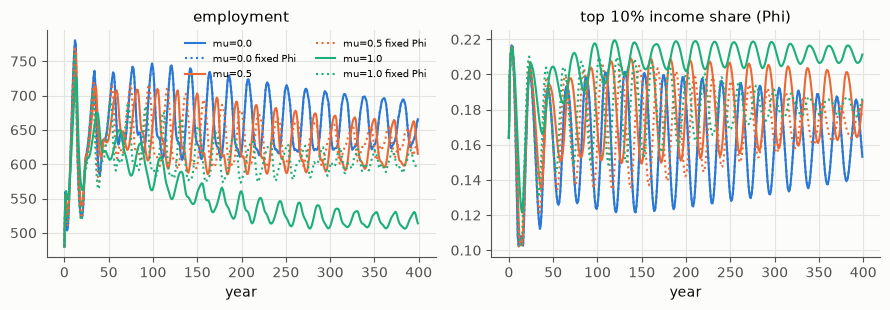

In [27]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
for i, mu in enumerate((0.0, 0.5, 1.0)):
    for j, (tag, ls) in enumerate((('回り道あり', '-'), ('Φ を固定', ':'))):
        lab = f'μ = {mu}、{tag}'
        axs[0].plot(mean_series(res3[lab], 'E'), color=PAL[i], ls=ls, lw=1.5, label=f'mu={mu}' + (' fixed Phi' if j else ''))
        axs[1].plot(mean_series(res3[lab], 'top10_inc'), color=PAL[i], ls=ls, lw=1.5)
axs[0].set(xlabel='year', title='employment'); axs[1].set(xlabel='year', title='top 10% income share (Phi)')
axs[0].legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

**慎重さ μ が 0 → 1 で、雇用は大きく落ち、実質賃金も下がる。Φ を固定すると、同じ μ でも落ち込みは小さい**。集中 → 金利 → 金持ちの所得 → 集中、の回り道が、雇用の落ち込みを数倍に増幅する(どの種でも同じ向き。落ち込みの大きさは、標本の分布の裾によって種ごとに違う)。

ノートの外の記録(標本 400 記入、種 0 だけ、μ を 0.2 刻みで上げて下げた)では、μ = 1 で雇用 665 → 497、Φ を固定すると 640 で、増幅は 7 倍ほどだった。この記録は、段 1 のときの財政のルール(赤字を 0 に近づける)で出した。このノートを書くときに種を増やして確かめたところ、そのルールでは、種によっては慎重さがなくても、税率が上限 0.6 に張り付いて毎年 6% のデフレに落ちる(雇用 340)ことがわかった(増税 → 需要が減る → 物価が下がる → 名目の所得が縮む → 赤字の比が上がる → さらに増税、の輪)。上の表は、その輪のない既定のルールで回し直したものである。結論(回り道が落ち込みを増幅する)は同じだが、記録の「7 倍」は一つの種の値として読んでほしい。

In [28]:
record('stage1', 'E2')

E2 貸し手の慎重さ μ を上げ、下げる(閾値 θ = 0.15。各 150 年の最後の値。Φ 固定は、集中を基準の値に止めた比較。G/Y は国債の対所得比)
  μ=0.0  E=665  real_wage=2.586  top10_inc=0.158  rbar=0.060  tau=0.174  G/Y=0.25   | Φ 固定: E=664 rbar=0.060
  μ=0.2  E=664  real_wage=2.549  top10_inc=0.164  rbar=0.064  tau=0.173  G/Y=0.30   | Φ 固定: E=662 rbar=0.063
  μ=0.4  E=650  real_wage=2.490  top10_inc=0.174  rbar=0.072  tau=0.186  G/Y=0.37   | Φ 固定: E=658 rbar=0.066
  μ=0.6  E=624  real_wage=2.396  top10_inc=0.187  rbar=0.084  tau=0.209  G/Y=0.48   | Φ 固定: E=652 rbar=0.069
  μ=0.8  E=574  real_wage=2.228  top10_inc=0.208  rbar=0.107  tau=0.258  G/Y=0.67   | Φ 固定: E=646 rbar=0.072
  μ=1.0  E=497  real_wage=1.999  top10_inc=0.226  rbar=0.137  tau=0.347  G/Y=0.85   | Φ 固定: E=640 rbar=0.075
  μ=1.2  E=439  real_wage=1.856  top10_inc=0.226  rbar=0.151  tau=0.437  G/Y=0.90   | Φ 固定: E=633 rbar=0.078
  μ=1.4  E=411  real_wage=1.786  top10_inc=0.219  rbar=0.158  tau=0.492  G/Y=0.86   | Φ 固定: E=626 rbar=0.081
  μ=1.6  E=391  real_wage=1.740  top10_inc=0.214

μ を上げてから下げると、少しだけ経路による差が出る(μ = 0.8 で、上りのとき 574、下りのとき 531)。ただ、はっきりした二つの釣り合い(履歴)はない。

**問い 2 への答えの核**: 分配の集中は、貸し手の慎重さ(集中に反応する金利の上乗せ)を通じて、雇用と実質賃金を下げる。その効き目の大部分は、集中が金利を上げ、金利が集中を進める回り道から来る。第 4 章で、土地がこの回り道を一段強めることを、第 8 章で、この上乗せの形(ρ_eff の折れ線)が、富む家計の死蔵と準備の縛りから出てくることを見る。

### 3.4 再分配の効き方は、行動の仮定で変わる

資本所得に税をかけ、税収を一人あたり同じ額で配る(τ_k)。それが雇用を増やすか減らすかは、投資の行動の仮定で変わる。第 2 章の骨組みの試験(gj)と同じ結論が、価格と信用のある経済でも出る(以下の記録は、3.3 節と同じく、段 1 のときの財政のルールと種 0 の値)。

In [29]:
record('stage1', 'E3')

E3 再分配(資本所得の税 τ_k、税収を一人あたり同額で配る)と、投資の行動の仮定(μ = 0.5、θ = 0.15)
  需要主導(稼働率に強く反応)
    τ_k=0.2  E=462  real_wage=2.383  top10_inc=0.182  rbar=0.083  tau=0.363  infl=0.032±0.081
    τ_k=0.4  E=496  real_wage=2.483  top10_inc=0.151  rbar=0.069  tau=0.297  infl=0.032±0.064
    τ_k=0.6  E=506  real_wage=2.470  top10_inc=0.129  rbar=0.063  tau=0.286  infl=0.041±0.066
  基準
    τ_k=0.2  E=633  real_wage=2.440  top10_inc=0.181  rbar=0.077  tau=0.246  infl=0.000±0.003
    τ_k=0.4  E=576  real_wage=2.549  top10_inc=0.134  rbar=0.065  tau=0.226  infl=0.019±0.036
    τ_k=0.6  E=549  real_wage=2.536  top10_inc=0.126  rbar=0.063  tau=0.237  infl=0.031±0.048
  利潤主導(利潤率に強く反応)
    τ_k=0.2  E=337  real_wage=1.966  top10_inc=0.216  rbar=0.098  tau=0.577  infl=0.060±0.141
    τ_k=0.4  E=330  real_wage=1.856  top10_inc=0.204  rbar=0.091  tau=0.578  infl=0.120±0.223
    τ_k=0.6  E=343  real_wage=1.859  top10_inc=0.172  rbar=0.077  tau=0.568  infl=0.164±0.285


- **需要主導**(投資が稼働率に強く、利潤率に弱く反応する): 再分配で消費が増え、稼働率が上がって投資も増え、雇用が上がる(462 → 506)。
- **基準**: 再分配で雇用が下がる(633 → 549)。利潤率が下がって投資が減る効き目が勝つ。
- **利潤主導**(利潤率に強く反応する): 雇用はほとんど変わらず、物価が大きく揺れる。

どの場合も、集中(上位 10% の所得)は下がる。

ただし、この記録は、段 1 のときの財政のルール(赤字を 0 に)で出したものである。第 17 章で、既定の財政のルール(利払いの重さ)で回し直すと、**再分配はどの投資の仮定でも雇用を上げ、基準の経済での逆転は消える**。逆転を作っていたのは、投資の仮定そのものより、再分配の税収と給付を財政のルールがどう吸うか、のほうだった。

もう一つ注意がある。段 1 の作業の途中で、標本の持分の分布の作り方に誤りが見つかり(一つの世帯が持分の 84% を持っていた)、直した。直す前と後で、回り道の増幅(3.3 節)と、次の節のテイラー・ルールの不安定は残ったが、**基準の経済での再分配の向きは変わった**(直す前は増えた)。家計の分布の裾(最大の世帯の持分)が、集中の回り道の強さを決めるからである。政策の向きの結論は、行動の仮定だけでなく、分布の形にも敏感である(問い 3)。

### 3.5 テイラー・ルールは、両方向に不安定

中央銀行が、物価の上昇に応じて政策金利を上げるルール(政策金利 = max(0, 0.02 + φ_π × 物価上昇率))を入れると、どうなるか。im では、r̄ が貸出の金利に連動する(3.2 節)ので、**利上げ → r̄ → 値上げ幅 → 物価**、と回る。利上げが物価を上げ、利下げが物価を下げる。

In [30]:
record('stage1', 'E5')

E5 テイラー・ルール(政策金利 = max(0, 0.02 + φ_π × 物価上昇率))。r̄ が貸出の金利に連動するので、利上げは費用を通じて物価を上げる
  基準                           φ_π=0.0  E=664  real_wage=2.586  top10_inc=0.158  rbar=0.060  tau=0.174  infl=-0.003±0.001  政策金利=0.020
  基準                           φ_π=0.6  E=513  real_wage=2.770  top10_inc=0.111  rbar=0.040  tau=0.320  infl=-0.037±0.001  政策金利=0.000
  基準                           φ_π=1.0  E=516  real_wage=2.770  top10_inc=0.111  rbar=0.040  tau=0.313  infl=-0.036±0.001  政策金利=0.000
  基準                           φ_π=1.5  E=430  real_wage=2.759  top10_inc=0.107  rbar=0.040  tau=0.447  infl=-0.051±0.003  政策金利=0.000
  慎重さ μ = 1                    φ_π=0.0  E=488  real_wage=1.980  top10_inc=0.225  rbar=0.136  tau=0.364  infl=0.002±0.000  政策金利=0.020
  慎重さ μ = 1                    φ_π=0.6  E=491  real_wage=1.983  top10_inc=0.229  rbar=0.141  tau=0.358  infl=0.003±0.001  政策金利=0.022
  慎重さ μ = 1                    φ_π=1.0  E=583  real_wage=2.270  top10_inc=0.206  rbar=0.118  tau=0.247  infl=0.001±0.

基準の経済では、φ_π = 0.6 でも金利が 0 に張り付き、毎年 4% ほどのデフレと低い雇用の釣り合いに落ちる。テイラー・ルールが、意図しない二つ目の定常状態(金利 0 とデフレ)を作る(Benhabib, Schmitt-Grohé and Uribe 2001)。逆に、慎重さが強いときや需要主導の経済では、物価が発散する。im の既定は、金利の固定(φ_π = 0)にした。この「金利で物価と戦うと危ない」は、第 6 章で、災害のあとの財政の行き詰まりの原因として、もう一度現れる。

### 3.6 この章のまとめ

- im の一年は、年のはじめの計画、年の中の価格の釣り合い(最小化)、年の終わりの支払いと遅い量の更新、の三層で進む。
- r̄ は貸出の金利から与える。貸出の金利が上がると、値上げ幅が上がり、実質賃金が下がる。
- **分配の集中は、貸し手の慎重さを通じて雇用を下げ、その効き目の大部分は、集中と金利の回り道から来る**(問い 2)。
- 再分配の効き方は、投資の行動の仮定と、家計の分布の裾の形で、向きまで変わる(問い 3)。
- テイラー・ルールは、この閉じ方では両方向に不安定になる。

---

# 第 II 部 資産と世界

## 第 4 章 土地と知財と株

ノート 2 では、2019 年の資産市場シミュレーションを読み、土地(減耗しない)と知財(減耗する)と借金の模型を立て直した。v6b(第 1 章)は、それを信用循環モデルに足した。段 2 では、その土地と知財の市場を、im の標本の家計の上に入れ直した。

### 4.1 土地の市場

土地は、必需品を作るのに要る(地代は必需品一単位あたり ρ_T × 必需品の価格)。地代は土地の持ち主の所得になる。土地の値段は、標本の記入ごとの**望む保有**の和が土地の総量に等しくなる値段として、二分法で解く(v6b と同じ)。

- 望む保有 = θ × (正味資産 + 稼ぐ力) ÷ 値段。土地に置きたい割合 θ は、地代の利回りと値上がりの期待が貸出の金利を上回るほど高い(頭打ちつき)。
- 毎年、望む保有へ一部だけ近づく。
- 借りて買える上限は、土地の値打ちの λ_T(担保の掛け目)と、稼ぎに応じた無担保の上限まで。上限を超えた借金は棒引きになり(一家離散)、銀行の損は預金者が預金に応じて負う(預金の 3 割を超える分は政府が救済する)。
- 世代の入れ替わり: 毎年 2.5% の世帯が去り、財産をくじで選んだ相続人に渡す。新しい世帯は財産なしで始まる。

In [31]:
src = inspect.getsource(im1.Im1.land_market)
print(src[src.index('        def holdings'):src.index('        land_err')])

        def holdings(pr):
            nw = other + pr * land
            d = np.maximum(0.0, theta * (nw + human) / pr)
            cap = (U_lim + H.M + pr * land) / ((1 - lT) * pr)
            return np.clip(land + chi * (d - land), 0.0, np.maximum(cap, 0.0))
        lo, hi = np.log(self.pT) - 8, np.log(self.pT) + 8
        for _ in range(100):
            mid = 0.5 * (lo + hi)
            if holdings(np.exp(mid)).sum() > T:
                lo = mid
            else:
                hi = mid
        pT = float(np.exp(0.5 * (lo + hi)))
        new = holdings(pT)



土地を入れると、何が変わるか。そして、第 3 章の「集中 → 金利 → 雇用」の回り道は、土地でどう変わるか(慎重さ μ と、Φ を固定した比べ。θ = 0.15)。種 4 個、400 年の最後の 100 年。

In [32]:
B2 = dict(households='continuous', Ns=1000, g_gamma=0.0, credit=True, theta_prem=0.15, c_h=0.005)
cases = []
for land in (False, True):
    tag = '土地あり' if land else '土地なし'
    phi0 = 0.218 if land else 0.165          # 慎重さのない経済の Φ
    cases += [(f'{tag}、μ = 0', dict(land=land)),
              (f'{tag}、μ = 1', dict(land=land, mu_prem=1.0)),
              (f'{tag}、μ = 1、Φ を固定', dict(land=land, mu_prem=1.0, phi_fixed=phi0))]
res4 = runs(cases, seeds=range(4), T=400, keys=('E', 'real_wage', 'top10_inc', 'top10_nw', 'rbar', 'land_value', 'hh_debt', 'Y'), base=B2)
table(res4, [('雇用', 'E', 'mean', '.0f'), ('実質賃金', 'real_wage', 'mean', '.3f'), ('上位10%の所得', 'top10_inc', 'mean', '.3f'),
             ('上位10%の富', 'top10_nw', 'mean', '.3f'), ('r̄', 'rbar', 'mean', '.3f'),
             ('土地の値打ち/所得', lambda r: np.nanmean(r['land_value'][300:] / r['Y'][300:]), None, '.2f')], burn=300)

  場合                             | 雇用 | 実質賃金 | 上位10%の所得 | 上位10%の富 | r̄ | 土地の値打ち/所得
  土地なし、μ = 0                     | 658±1 | 2.579±0.003 | 0.164±0.003 | nan±nan | 0.060±0.000 | nan±nan
  土地なし、μ = 1                     | 517±26 | 2.070±0.074 | 0.211±0.010 | nan±nan | 0.123±0.009 | nan±nan
  土地なし、μ = 1、Φ を固定               | 604±1 | 2.392±0.003 | 0.182±0.004 | nan±nan | 0.083±0.000 | nan±nan
  土地あり、μ = 0                     | 585±1 | 2.335±0.003 | 0.217±0.001 | 0.638±0.001 | 0.060±0.000 | 1.67±0.01
  土地あり、μ = 1                     | 285±1 | 1.501±0.005 | 0.272±0.000 | 0.745±0.001 | 0.181±0.000 | 1.01±0.00
  土地あり、μ = 1、Φ を固定               | 418±0 | 1.814±0.000 | 0.279±0.000 | 0.770±0.001 | 0.129±0.000 | 1.08±0.00
  (帳簿と標本の差/所得の最大 3e-14)


- **土地を入れるだけで、雇用と実質賃金が下がる**(地代が必需品の費用に乗る)。地代は土地の持ち主に入り、所得と富の集中が進む。土地の値打ちは所得の 1.5 倍ほどで、住宅ローンが自然に生まれる(ノート 2、v6b と同じ)。
- **土地は、集中の回り道を大きく強める**。慎重さ μ = 1 で、雇用は土地なしなら 2 割ほど落ちるが、土地ありでは半分ほどに落ちる。Φ を固定すれば、落ち込みは 1 割と 3 割に縮む。地代と土地の値上がりが金持ちに入って集中が進み、金利が上がり、金利が上がると土地の持ち主の利子と配当がさらに増える。**問い 2 への答えは、土地を入れて一段強くなった**。

### 4.2 泡と利上げ、資産効果

土地に置きたい割合が一時的に高まる(ユーフォリア)と、土地の値段は膨らみ、そのあとの利上げで崩れる。担保の掛け目を上げると、借金と貸倒れは深くなるが、生産の落ち込みはほとんど変わらない(v6b と同じ。担保は貸倒れを深くするが、生産への効き方は小さい)。生産を大きく揺らすのは、土地の値打ちを消費に回す**資産効果**のほうで、その強さが境目(0.02 と 0.04 のあいだ)を越えると、土地の泡が自分で膨らむらせんになる。

In [33]:
record('stage2', 'S2')
record('stage2', 'S3')

S2 ユーフォリア(300 年目から 10 年、土地に置きたい割合 +0.15)のあと、利上げ(政策金利 0.02 → 0.06 を 5 年)。担保の掛け目 λ_T を変える
   値は直前 20 年の平均に対する比(土地の値段は実質 = 土地の値段 / 必需品の価格)。貸倒れと救済は、直前の所得に対する 40 年の合計
  λ_T=0.0  土地の頂 ×3.51  底 ×0.46  雇用の底 ×0.869  借金/所得の頂 0.151  貸倒れ 0.0331  救済 0.0000
  λ_T=0.6  土地の頂 ×3.68  底 ×0.41  雇用の底 ×0.860  借金/所得の頂 0.223  貸倒れ 0.0586  救済 0.0000
  λ_T=0.9  土地の頂 ×3.68  底 ×0.40  雇用の底 ×0.864  借金/所得の頂 0.224  貸倒れ 0.0893  救済 0.0000
S3 資産効果 c_h(土地の正味の値打ちの割合を消費に足す)。同じユーフォリアと利上げ。λ_T = 0.6
  c_h=0.000  土地の頂 ×3.56  底 ×0.44  雇用の底 ×0.899  借金/所得の頂 0.243  貸倒れ 0.0447
  c_h=0.005  土地の頂 ×3.68  底 ×0.41  雇用の底 ×0.860  借金/所得の頂 0.223  貸倒れ 0.0586
  c_h=0.010  土地の頂 ×3.83  底 ×0.43  雇用の底 ×0.840  借金/所得の頂 0.202  貸倒れ 0.0904
  c_h=0.020  土地の頂 ×3.98  底 ×0.39  雇用の底 ×0.772  借金/所得の頂 0.353  貸倒れ 0.0491
  c_h=0.040  土地の頂 ×11.14  底 ×0.35  雇用の底 ×0.852  借金/所得の頂 0.991  貸倒れ 3.1127


### 4.3 相続のしかたが、格差を決める

世代の入れ替わりがなければ、借金も、富の順位の入れ替わりもない。くじの相続(去る世帯の財産を一つの世帯がまるごと継ぐ)で、富のジニは 0.72 になる。等しく分ける相続では 0.39 に下がる。v6b でも、ノート 3 の simbd でも、同じことが出た。富の格差の大きな部分は、相続のしかたという制度から来る(第 12 章で、運と合わせてもう一度見る)。

In [34]:
record('stage2', 'S5')

S5 世代の入れ替わりと相続(400 年。最後の 100 年の平均。順位の相関は、350 年目と 360 年目の一人あたりの正味資産)
  入れ替わり 0.000 相続 lottery   正味資産のジニ 0.471  上位 10% 0.463  借金/所得 0.000  借り手 0 人  雇用 601  10 年の順位の相関 1.00
  入れ替わり 0.025 相続 lottery   正味資産のジニ 0.721  上位 10% 0.682  借金/所得 0.064  借り手 255 人  雇用 597  10 年の順位の相関 0.42
  入れ替わり 0.025 相続 equal     正味資産のジニ 0.388  上位 10% 0.256  借金/所得 0.030  借り手 177 人  雇用 571  10 年の順位の相関 0.56
  入れ替わり 0.050 相続 lottery   正味資産のジニ 0.794  上位 10% 0.734  借金/所得 0.100  借り手 392 人  雇用 590  10 年の順位の相関 0.29


### 4.4 知財は、買えば不利か

ノート 2 で、2019 年の模型の知財は「買えば不利になる」ことを見た。JRF は、それがどうにかなったのかを問うた。段 2 の im では、知財は自主研究(贅沢品の支出の一部が創作になる)で生まれ、使用料を受け取り、相続で動くだけで、売り買いされなかった。段 2b で、知財の市場を土地の市場と同じ仕組みで足した(違いは、減耗することと、利回りが使用料から来ること)。

In [35]:
record('stage2b', 'P1')
record('stage2b', 'P6')

P1 知財の市場(400 年、最後の 200 年)。需要の決まり方は土地と同じ(利回りの差は ±0.2 で頭打ち、反応 3)
  使用料あり(φ_R = 0.1)                   知財の値打ち/所得 0.366  値段/使用料の割引の値      13.4  持ち主の利回り -0.093(貸出の金利 0.040、物価 -0.004)  新しい知財の値打ち/所得 0.0367  持ち主の不足/所得 +0.0488  雇用 590  正味資産のジニ 0.715
  使用料なし(φ_R = 0。2019 年と同じ)           知財の値打ち/所得 0.361  値段/使用料の割引の値       inf  持ち主の利回り -0.103(貸出の金利 0.040、物価 -0.003)  新しい知財の値打ち/所得 0.0363  持ち主の不足/所得 +0.0520  雇用 590  正味資産のジニ 0.722
P6 裁定の価格(値段 = 使用料を、貸出の金利 + 減耗で割り引いた値打ち)。比べる基準
  使用料あり、裁定の価格                        知財の値打ち/所得 0.028  値段/使用料の割引の値         1  持ち主の利回り +0.038(貸出の金利 0.040、物価 -0.002)  新しい知財の値打ち/所得 0.0028  持ち主の不足/所得 +0.0001  雇用 594  正味資産のジニ 0.720


**「買えば不利」は戻ってきた**。需要の決まり方を土地と同じにすると、知財の値段は使用料を割り引いた値打ちの 13 倍ほどで釣り合い、持ち主の利回りは年 −9% になる。原因は、**利回りにほとんど反応しない需要**(持つこと自体を好む、習慣としての買い)と、**ただで生まれ続ける供給**(作り手は新しい知財をただで手に入れ、知財は毎年減耗する)の組み合わせである。値段を裁定(使用料を金利と減耗で割り引いた値打ち)で決めれば、「買えば不利」は消える。

持ち主の損の行き先は、新しい知財の作り手である。**知財を買う貯蓄者から、研究の作り手への隠れた補助**になっている。作者の 2021〜22 年の「国庫」の案(企業の黒字を、知財の売り手に配る)は、この補助を表に出して、誰が払うかを決め直す案として読める(第 10 章で、研究の当たりに比例して配る形で試す)。

### 4.5 株は、買えば得

知識への投資は、知財そのものでなく、企業の持分(株)を通しても報われうる(JRF の問い「現実では知財と株式に何か連動性があるから、投資がそこに回りうるのでは」)。段 5 の探索で、企業が研究し、知財を企業の中に持ち、持分を売り買いする市場を入れた。

In [36]:
record('stage5b', 'X3')

X3 株式の市場と知財の市場: 買い手の実際の利回り(実質、対数の平均)と、名目の利回りの貸出の金利との差。値段/基本の値打ち = 市場の値段の和 / (配当 ÷ r̄)の和
   株の値段の既定は基本の値打ち(均した配当 ÷ r̄)で、市場は持ち主を入れ替えるだけ。置きたい割合: 基準 0.12、富の弾力性 κ_E = 0.5(富むほど株に置く)、
   稼ぐ力は数えない、借りて買えない(λ_E = 0)。「需要で値段」は標本の望む保有の和 = 1 となる値段。崩れ = 解けなくなった種(物価の発散)
   知財の市場は段 2b と同じ(需要で値を決める)。研究ありは α=1.5、s_R=0.02
  場合                        | 崩れ | 株の実質の利回り | 株−貸出の金利 | その揺れ | 値段/基本 | 知財の実質の利回り | 知財−貸出の金利 | 貸出の実質の金利 | 物価 | 実質の生産の揺れ | 雇用 | 富の上位10% | 所得の上位10% | 上位10%の持分
  株式の市場(既定)                  |  0 | +0.059 | +0.026 | 0.147 | 1.00 |   —   |   —   | +0.032 | +0.007 | 0.033 | 586 | 0.698 | 0.225 | 0.99
  株式 κ_E=0(皆が同じ割合)           |  0 | +0.061 | +0.047 | 0.151 | 1.00 |   —   |   —   | +0.014 | +0.026 | 0.045 | 596 | 0.504 | 0.189 | 0.73
  株式 κ_E=0、稼ぐ力も数える           |  0 | +0.059 | +0.052 | 0.156 | 1.00 |   —   |   —   | +0.007 | +0.033 | 0.049 | 597 | 0.298 | 0.138 | 0.30
  株式 κ_E=1                   |  0 | +0.057 | +0.029 | 0.147 | 1.00 |   —   |   —   | +0.028 | +0.012 | 0.036 | 590 | 0.688 | 0

**株は買えば得、知財は買えば損**。株の持ち主の実質の利回りは、貸出の実質の金利より 2〜3% 高い(r̄ の上乗せにほぼ等しい)。違いは、**持分は企業全体(新しい投資も、企業の中の知識も)への請求権で、薄まらない**のに対し、売り買いされる知財は減耗し、新しい知財がただで作り手に入って薄まることにある。研究があると、株の利回りはさらに上がる。知識への投資は、知財そのものよりも、知識を作り続ける組織の持分を通して報われる。

ただし、株の値段を需要で決めると(望む保有の和 = 1 となる値段)、富むほど株を欲しがる → 値段が上がる → 持ち主がさらに富む、という輪で値段が暴れる(泡は基本の値打ちの数十倍)。im の既定では、株の値段を基本の値打ち(均した配当 ÷ r̄)に結んだ。需要で決める株の市場は、第 12 章(年金の基金が株を買う)と第 13 章(株式的富のペテン)で、わざと使う。

### 4.6 この章のまとめ

- 土地は地代を通じて実質賃金を下げ、集中を進める。**集中の回り道は、土地で一段強くなる**(問い 2)。
- 担保は貸倒れを深くするが、生産を大きく揺らすのは資産効果で、境目を越えると土地の泡がらせんになる。
- 富の格差の大部分は、相続のしかたで決まる。
- 知財は、利回りに反応しない需要と、ただで生まれ続ける供給のもとでは「買えば不利」で、その損は作り手への隠れた補助になる。株は薄まらない請求権なので、買えば得。

---

## 第 5 章 地域と通貨と資本の移動

作者の元の関心の二つめは、**輸出入**だった。段 3 で、im を二つ(と三つ)の地域に広げた(`im3.py` の World)。

### 5.1 地域の作り

- 地域ごとに、im の一国の経済(三財、信用、標本の家計、土地と知財)を一つずつ持つ。
- 財は地域ごとに少しずつ違い(アーミントン)、買い手は、自地域の財と他地域の財を、代わりの利きやすさ σ で混ぜて買う(必需品 8、贅沢品 2、原料 4。贅沢品は代わりが利きにくい: 種類の違いを買う)。輸送の費用は、運ぶあいだに一部が溶ける形(氷山)にした。
- 価格は、すべての地域のすべての財の残差を、一つの最小化で同時に解く(作者の「最適化で書く」は、地域の数が増えても同じ形で書ける)。
- 通貨は三通り: **共通の通貨**(地域の間の支払いは、銀行の間の貸し、ユーロ圏の TARGET2 の残高にあたる)、**別々の通貨で固定**(為替の窓口が持ち高を積む)、**別々の通貨で変動**(為替を、価格と同じ年の中で解く)。帳簿は通貨ごとに一つ。

### 5.2 貿易の得と比較優位

まず、記録から。同じ二つの地域で輸送の費用を下げていくと、実質賃金と雇用が上がる。得の大部分は、代わりの利きにくい贅沢品の種類を互いに買い合うこと(クルーグマン)と、輸送の費用そのものである。得意な財が違えば(比較優位)、それぞれ得意な財を輸出し、閉鎖より実質賃金が 5 割ほど高い。

In [37]:
record('stage3', 'T1')
record('stage3', 'T2')

T1 貿易の得: 同じ二つの地域(好みの重みは自地域 0.5)。輸送の費用 tc を振る(tc = 30 は事実上の閉鎖)。300 年、最後の 100 年の平均
  tc=  0.0  E=591  real_wage=2.324  top10_inc=0.217  輸入/所得=0.778  物価上昇率 -0.003±0.001  帳簿のずれ/所得 2.0e-14
  tc=  0.1  E=511  real_wage=2.090  top10_inc=0.210  輸入/所得=0.631  物価上昇率 -0.005±0.001  帳簿のずれ/所得 1.0e-14
  tc=  0.3  E=368  real_wage=1.825  top10_inc=0.171  輸入/所得=0.396  物価上昇率 +0.015±0.047  帳簿のずれ/所得 4.8e-15
  tc=  1.0  E=298  real_wage=1.531  top10_inc=0.199  輸入/所得=0.134  物価上昇率 +0.128±0.132  帳簿のずれ/所得 2.6e-15
  tc= 30.0  E=268  real_wage=1.420  top10_inc=0.209  輸入/所得=0.002  物価上昇率 +0.168±0.146  帳簿のずれ/所得 3.8e-15
T2 比較優位: A は必需品(一製品あたり労働 0.07)、B は贅沢品(0.21)が得意。輸送の費用 0.1 と、事実上の閉鎖
  tc=  0.1 A  E=546  real_wage=2.223  top10_inc=0.205  必需品の輸出/所得 0.245  贅沢品の輸出/所得 0.068  貿易の収支/所得 +0.0006  銀行の間の貸し/所得 +2.15  物価上昇率 -0.007±0.002
  tc=  0.1 B  E=521  real_wage=2.143  top10_inc=0.231  必需品の輸出/所得 0.149  贅沢品の輸出/所得 0.126  貿易の収支/所得 -0.0006  銀行の間の貸し/所得 -2.46  物価上昇率 -0.007±0.002
  tc= 30.0 A  E=292  real_wage=1.512  top10_inc=0.

### 5.3 危機時の生産を、地域で分ける

作者の関心「一つの地域の必需品が打撃を受けたとき、もう一つの地域がどう埋めるか」を、その場で確かめる。250 年目に地域 A の必需品の生産能力を半分にし、10 年のあいだの底(直前 20 年の平均に対する比)を、三つの通貨の制度で比べる(記録と同じ設定。標本 400 記入ずつ)。

In [38]:
import im3
C3 = dict(g_gamma=0.0, credit=True, land=True, c_h=0.005, fiscal='deficit')

def crisis(cur, t0=250):
    w = im3.World(common=C3, home=0.5, tc=0.1, currency=cur)
    for t in range(t0 + 15):
        if t == t0:
            w.R[0].K[0] *= 0.5
        w.step()
    g = lambda i, k: np.array([rs[i][k] for rs in w.log])
    pre, post = slice(t0 - 20, t0), slice(t0, t0 + 10)
    rp = g(0, 'bN') / g(0, 'W')
    return dict(cur=cur, A_price=rp[post].max() / rp[pre].mean(),
                A_rw=g(0, 'real_wage')[post].min() / g(0, 'real_wage')[pre].mean(), A_E=g(0, 'E')[post].min() / g(0, 'E')[pre].mean(),
                B_rw=g(1, 'real_wage')[post].min() / g(1, 'real_wage')[pre].mean(), B_E=g(1, 'E')[post].min() / g(1, 'E')[pre].mean(),
                A_tb=float(np.mean(g(0, 'tb')[post] / g(0, 'Y')[post])))

LAB = {'common': '共通の通貨', 'fixed': '固定', 'float': '変動'}
print('  通貨      | A の必需品の実質の価格の頂 | A の実質賃金の底 | A の雇用の底 | B の実質賃金の底 | B の雇用の底 | A の貿易の収支/所得')
for r in nt.pmap(crisis, ['common', 'fixed', 'float']):
    print(f"  {LAB[r['cur']]:8s} | ×{r['A_price']:.2f} | ×{r['A_rw']:.3f} | ×{r['A_E']:.3f} | ×{r['B_rw']:.3f} | ×{r['B_E']:.3f} | {r['A_tb']:+.3f}")

  通貨      | A の必需品の実質の価格の頂 | A の実質賃金の底 | A の雇用の底 | B の実質賃金の底 | B の雇用の底 | A の貿易の収支/所得


  共通の通貨    | ×1.18 | ×0.845 | ×0.799 | ×0.875 | ×0.848 | -0.016
  固定       | ×1.18 | ×0.845 | ×0.799 | ×0.875 | ×0.848 | -0.016
  変動       | ×1.37 | ×0.728 | ×0.599 | ×0.958 | ×0.951 | -0.000


**共通の通貨(と固定)は、打撃を二つの地域で分ける**。A は B から必需品を買い(貿易の赤字)、その支払いは銀行の間の借りとして積み上がる。A の落ち込みは浅くなり、B も少し落ちる。**変動の為替では、打撃を受けた地域がひとりで負う**。資本の移動がなければ、変動の為替は毎年の貿易の収支を 0 に縛るので、A は必需品を外から買い越せず、自分で作り直すほかない。A の実質賃金と雇用は大きく落ち、B はほとんど無傷である。

これは、ユーロ圏の議論でいう「共通の通貨の保険の働き」の、模型の中の姿である。ただし、その保険の裏は、打撃を受けた地域の銀行の間の借り(対外の持ち高)として残り、共通の通貨にはそれを戻す仕組みがない(比較優位の実験では、初めの数十年の不均衡で、銀行の間の貸しが所得の 2 倍ほど積み上がり、そのまま残った)。

### 5.4 為替は物価の比を追う、そして三国以上では

別々の通貨で変動にすると、為替は物価の比を追う(購買力平価。A が赤字を続けて物価が上がれば、A の通貨は同じだけ下がる)。実質の為替は、どの実験でもほぼ 1 だった。変動の為替が効くのは、為替の値そのものより、「毎年、貿易の収支を 0 にする」縛りのほうである。

JRF は、この縛りが二国だから出るのか、と問うた。三国で確かめた答え: 縛りの出どころは、二国であることではなく、**資本の移動がないこと**(と、外貨準備で埋めないこと)である。N 国でも、各国の(全相手との合計の)収支が 0 に縛られる。二国間の収支は 0 でなくてよい。

In [39]:
record('stage3c', 'C2')

C2 危機時の生産: 250 年目に A の必需品の生産能力が半分。10 年の底(直前 20 年の平均に対する比)。地域は同じ技術
  すべて共通          A: 雇用 ×0.879 実質賃金 ×0.894   B: 雇用 ×0.935 実質賃金 ×0.928   C: 雇用 ×0.935 実質賃金 ×0.928
  A+B 同盟、C 変動    A: 雇用 ×0.814 実質賃金 ×0.854   B: 雇用 ×0.872 実質賃金 ×0.889   C: 雇用 ×0.969 実質賃金 ×0.977
  B+C 同盟、A 変動    A: 雇用 ×0.609 実質賃金 ×0.734   B: 雇用 ×0.971 実質賃金 ×0.977   C: 雇用 ×0.971 実質賃金 ×0.977
  すべて変動          A: 雇用 ×0.609 実質賃金 ×0.734   B: 雇用 ×0.971 実質賃金 ×0.977   C: 雇用 ×0.971 実質賃金 ×0.977


三国では、通貨の組み合わせで、打撃を誰が分けるかが決まる。すべて共通なら三つで分け、同盟を組めば同盟の仲間が分け、同盟の外の国は守られる。同盟の外にいる国は、ひとりで負う。

### 5.5 資本の移動の作り

ここまでの地域の模型には、資本の移動がなかった。家計は自分の地域の銀行にしか預けられず、変動の為替は「毎年、貿易の収支を 0 にする」値に決まった。段 6 で、家計が**外の資産**(よその地域の銀行の預金)を持てるようにした。

- **外の資産の帳簿**: 地域 o の家計の外の資産は、o の窓口(ext@o)が出す請求権で、その裏は行き先の地域 d の銀行の預金である。同じ通貨なら窓口が d の銀行に預け、違う通貨なら為替の窓口で替えて、d の帳簿の「非居住者」の部門が預ける。利子は d の政策金利で、d の銀行の利益から払う。違う通貨なら、為替で毎年値打ちを付け直す。通貨ごとの帳簿は、どれもこれまでどおり閉じる。
- **外に置きたい割合** = 基準 θ_F0 + φ_K × (外の見込みの利回り − 内の金利) + φ_L × 逃れられる富裕税の率(頭打ちつき)。外の見込みの利回り = 外の金利 − κ_q × ln(実質の為替)。外が割高なら、外の通貨は下がると見込む(購買力平価への戻りの見込み。Dornbusch 1976 のオーバーシュートの模型の期待の形)。
- 家計は、望む保有へ毎年 χ_F の割合だけ近づく(資本の動く速さ)。
- **資産の売り買いは、為替と同じ年の中で釣り合う**。為替は、財の値段であると同時に、資産の値段でもある。変動の通貨の圏は、「貿易の収支 + 資本の流れ + 利子の流れ = 0」となるよう、価格と一緒に為替を解く(作者の「最適化で書く」の形のまま、条件が一本増えるだけ)。資本が流れ込めば、その地域は貿易の赤字を続けられる。

これで、第 5.4 節の縛り(変動の為替では毎年の貿易の収支が 0)が外れる。国際金融の「不可能な三角形」(Mundell 1963、Fleming 1962: 固定の為替・自由な資本の移動・独立の金融政策の三つは同時には持てない)の三つの角を、模型の中で試せるようになった。

### 5.6 速く動く資本は、変動の為替を暴れさせる

資本の動く速さ χ_F を変える(外に置きたい割合の基準 0.1、変動の為替、出来事なし)。その場で回す(種 3 組、標本 2000 記入ずつ、100〜260 年)。

In [40]:
import results_stage6 as r6
def calm(args):
    lab, cap, kw, seed = args
    o = r6.history((seed, 'float', cap, dict(r6.C, **kw), None, None, 'none'))
    if o is None:
        return None
    w = slice(100, 260)
    de = np.diff(np.log(o['A_e'][w]))
    return dict(lab=lab, fx=np.std(de), E=o['A_E'][w].mean(), sdE=o['A_E'][w].std(), F=np.mean(o.get('A_F_Y', np.zeros(260))[w]))
cases56 = [('資本の移動なし', False, {}), ('動く速さ 0.05(既定)', True, dict(r6.INTL)), ('動く速さ 0.2', True, dict(r6.INTL, chi_F=0.2))]
out56 = nt.pmap(calm, [(lab, cap, kw, s) for lab, cap, kw in cases56 for s in range(3)])
print('  場合                     | 為替の年の変化の標準偏差 | A の雇用 | A の雇用の揺れ | A の外の資産/所得')
for lab, _, _ in cases56:
    rs = [r for r in out56 if r and r['lab'] == lab]
    m = lambda k: np.mean([r[k] for r in rs])
    print(f"  {lab:22s} | {m('fx'):.3f} | {m('E'):.0f} | {m('sdE'):.0f} | {m('F'):.2f}")

  場合                     | 為替の年の変化の標準偏差 | A の雇用 | A の雇用の揺れ | A の外の資産/所得
  資本の移動なし                | 0.005 | 503 | 53 | 0.00
  動く速さ 0.05(既定)          | 0.031 | 500 | 56 | 0.31
  動く速さ 0.2               | 0.299 | 382 | 132 | 0.28


**速く動く資本は、変動の為替を暴れさせる**。資本の移動がなければ、為替の年の変化はごく小さい(物価の差を追うだけ)。資本が速く動くと、為替は毎年大きく振れ、雇用が下がって揺れる。家計の財産の波(相続と土地の循環で、15 年ほどの周期がある)に沿って、総額の持ち合いが両方向に動き、二つの地域の波がずれると、その差を為替と貿易が吸うからである。ゆっくり動かせば(既定の 0.05)、暴れは小さい。トービンの「速いお金の歯車に砂を撒く」(Tobin 1978、為替の取引への小さな税)の論点が、模型の中で出た。第 9 章で見るように、人間の注意の有限さ(慣性)も、同じ働きをする。

In [41]:
record('stage6', 'K0')

K0 資本の動く速さと、変動の為替の揺れ(出来事なし、100〜300 年)。外に置きたい割合の基準 θ_F0、望む保有へ近づく割合 χ_F
  場合                 | 為替の年の変化の標準偏差 | 実質の為替(対数)の標準偏差 | A の貿易の収支/所得の標準偏差 | 雇用 A | 雇用の標準偏差 | 物価 | 外の資産/所得
  資本の移動なし              | 0.009 | 0.001 | 0.0000 | 502 | 52 | +0.024 | 0.00
  θ_F0=0.05 χ_F=0.2    | 0.134 | 0.012 | 0.0168 | 455 | 82 | +0.032 | 0.18
  θ_F0=0.1 χ_F=0.2     | 0.325 | 0.023 | 0.0430 | 355 | 131 | +0.061 | 0.24
  θ_F0=0.1 χ_F=0.1     | 0.187 | 0.016 | 0.0210 | 431 | 104 | +0.039 | 0.29
  θ_F0=0.1 χ_F=0.05    | 0.093 | 0.009 | 0.0085 | 472 | 75 | +0.029 | 0.29
  θ_F0=0.2 χ_F=0.05    | 0.151 | 0.014 | 0.0424 | 453 | 79 | +0.044 | 0.53


### 5.7 一つの国の利上げは、外へ波及する

A の政策金利を 2% から 3% に上げる(200 年目から、ずっと)。資本の移動がない場合と、外の利回りによく反応する場合(φ_K = 3)を、同じ種で上げない歴史と比べる(種 3 組)。

In [42]:
def hike(args):
    lab, cap, kw, seed = args
    a = r6.history((seed, 'float', cap, dict(r6.C, **kw), None, None, 'hike'))
    z = r6.history((seed, 'float', cap, dict(r6.C, **kw), None, None, 'none'))
    if a is None or z is None:
        return None
    w = slice(200, 260)
    d = lambda k: a[k][w].mean() / z[k][w].mean() - 1
    return dict(lab=lab, fx=(np.log(a['A_e'][259] / a['A_e'][200]) - np.log(z['A_e'][259] / z['A_e'][200])) / 59,
                EA=d('A_E'), EB=d('B_E'), pB=np.mean(a['B_infl'][w] - z['B_infl'][w]), tb=np.mean(a['A_tb_Y'][w]))
cases57 = [('資本の移動なし', False, {}), ('資本の移動、φ_K = 3', True, dict(r6.INTL, phi_K=3.0))]
out57 = nt.pmap(hike, [(lab, cap, kw, s) for lab, cap, kw in cases57 for s in range(3)])
print('  場合                   | 為替の変化(年、負なら A の通貨が強い) | A の雇用 | B の雇用 | B の物価上昇率の差 | A の貿易の収支/所得')
for lab, _, _ in cases57:
    rs = [r for r in out57 if r and r['lab'] == lab]
    m = lambda k: np.mean([r[k] for r in rs])
    print(f"  {lab:20s} | {m('fx'):+.4f} | {m('EA'):+.3f} | {m('EB'):+.3f} | {m('pB'):+.4f} | {m('tb'):+.4f}")

  場合                   | 為替の変化(年、負なら A の通貨が強い) | A の雇用 | B の雇用 | B の物価上昇率の差 | A の貿易の収支/所得
  資本の移動なし              | -0.0045 | -0.032 | -0.001 | +0.0007 | +0.0000
  資本の移動、φ_K = 3        | -0.0537 | -0.101 | -0.087 | +0.0382 | +0.0073


**資本の移動がなければ、利上げは A の中にとどまる**(為替はほとんど動かず、B の雇用も変わらない)。**資本が動くと、B の家計が A の預金を買い、A の通貨が強くなり、B の物価が上がり、B の雇用も下がる**。A は、長い目では貿易の黒字を出して、B に利子を払う。大きな国の金融の条件が、変動の為替があっても外へ伝わる、という Rey(2013)の「世界の金融の循環」(三角形ではなく二択: 資本の移動を許すなら、変動の為替でも金融政策は独立でない)の形である。

### 5.8 地域の打撃を、誰が吸うか

第 5.3 節の危機(A の必需品の能力が半分)を、資本の移動と財政同盟(去年の失業者が同盟の平均より多い地域へ、少ない地域の政府から移す)を入れて、もう一度比べる(記録)。

In [43]:
record('stage6', 'K2')

K2 A の必需品の生産能力が半分(200 年目)。最初の 10 年の、雇用と実質賃金の比(同じ種で打撃のない歴史に対して)
  場合                     | A の雇用 | A の実質賃金 | B の雇用 | B の実質賃金 | A の貿易の収支/所得 | A の国債/所得の差 | B の国債/所得の差 | A への同盟の移転/所得 | A の銀行の間の貸し/所得の差
  変動、資本の移動なし               | -0.071±0.014 | -0.113±0.004 | +0.011±0.005 | +0.053±0.004 | -0.0000±0.0000 | +0.000±0.006 | -0.015±0.003 | +0.0000±0.0000 | -0.000±0.000
  変動、資本の移動                 | -0.064±0.029 | -0.106±0.008 | -0.013±0.005 | +0.049±0.008 | -0.0024±0.0007 | -0.023±0.018 | +0.013±0.004 | +0.0000±0.0000 | -0.000±0.000
  共通の通貨                    | +0.017±0.006 | -0.038±0.001 | +0.053±0.008 | -0.009±0.001 | -0.0164±0.0003 | +0.062±0.006 | -0.094±0.006 | +0.0000±0.0000 | -0.136±0.001
  共通の通貨、資本の移動              | +0.007±0.006 | -0.040±0.001 | +0.041±0.007 | -0.010±0.001 | -0.0159±0.0002 | +0.072±0.006 | -0.084±0.005 | +0.0000±0.0000 | -0.128±0.001
  共通の通貨、財政同盟 ψ=0.3         | +0.020±0.006 | -0.039±0.001 | +0.056±0.008 | -0.009±0.001 | -0.0187±0.0003 | +0.056±0.006 | -0.087±0.006 | +0.

- 変動の為替で資本の移動がなければ、A は貿易を釣り合わせなければならず、自分で作り直すほかない。資本が動けば、少し貿易の赤字を出せる(外の預金を取り崩す)。
- 共通の通貨では、A は B から必需品を買い(貿易の赤字)、その支払いは**銀行の間の借り**(A の所得の 1 割を超える。ユーロ圏の TARGET2 の残高にあたる。Sinn and Wollmershäuser 2012)と国債になる。実質賃金の落ち込みは最も浅い。共通の通貨の「保険」の裏には、この借りが残る。
- 財政同盟は、移転を足すが、効き目は小さい(打撃が局地で、共通の通貨の保険がすでに大部分を吸っている)。

### 5.9 富裕税は、国際化でどう問題になるか

JRF の問い「富裕税とかすると、国際化でどう問題が出るのか」への答えを見る。A が、一人あたりの正味資産が平均の 3 倍を超えた分に毎年 2% の富裕税をかける。外の資産のうち、税の当局に見える割合を変える(1 なら、国の間の情報の交換が完全)。

In [44]:
record('stage6', 'K3')

K3 A が恒常の富裕税(一人あたりの正味資産が平均の 3 倍を超えた分に毎年 2%)を 200 年目から入れる。差は 200〜260 年の平均
   A の正味資産は外の資産を含む。「B も税」は A と B の両方が同じ富裕税を入れる(情報の交換はない)
   見える割合 enf_F = 税の当局が見える外の資産の割合(1 = 情報の交換が完全)。逃げ φ_L = 30: 逃れられる税の率 1% につき、外に置きたい割合 +0.3
   税収は、資本の移動のない閉じた場合に対する比。外の資産の差は、A の家計が持つ外の資産/所得の差(資本の逃げ)。
   銀行の間の貸し: 共通の通貨で、A の銀行の、ほかの地域の銀行に対する貸し(負なら借り。TARGET2 の残高にあたる)/所得の差
  場合                          | 税収/所得 | 閉じた場合に対する比 | A の外の資産/所得の差 | 為替の変化 | A の物価 | A の実質賃金 | A の雇用 | A の富の上位10%の差 | B の富の上位10%の差 | A の国債/所得の差 | 銀行の間の貸し/所得の差
  変動、資本の移動なし                   | 0.0295 | 1.00 |   —   | +0.0044±0.0002 | +0.0019±0.0001 | -0.006±0.000 | +0.014±0.000 | -0.004±0.001 | +0.006±0.001 | -0.050±0.001 | +0.000±0.000
  変動、見える 1.0                   | 0.0313 | 1.06 | +0.008±0.008 | +0.0112±0.0037 | +0.0054±0.0024 | -0.013±0.003 | +0.002±0.012 | -0.009±0.004 | +0.009±0.004 | -0.041±0.009 | +0.000±0.000
  変動、見える 0.5                   | 0.0355 | 1.21 | +0.516±0.141 | +0.0901±0.0139 | +0.0580±0.0109 | -0.057±0.007 | -0.023±0.025 | 

- **情報の交換が完全なら**、税から逃げる見返りがなく、閉じた経済とほぼ同じになる。
- **変動の為替で、外の資産が見えないと**: 富裕層が外へ逃げ、A の通貨が下がり、物価が上がり、**A の実質賃金が下がる**。外へ逃げた富は自国の通貨で値上がりするので、**A の富の上位 10% の取り分はむしろ上がる**。富裕税の負担が、通貨の下がりを通じて労働者に移る。
- **共通の通貨では**、通貨が下がらない代わりに、A の銀行から預金が抜ける(それが TARGET2 の残高になる)。税収は減る。
- **相手の国も同じ税を入れても、情報の交換がなければ税収は戻らない**(両方の富裕層が互いの国へ逃げ、変動の為替では総額の持ち合いが膨らんで、5.6 節の暴れが出る)。

効くのは、税率をそろえることより、**見えるようにすること**(情報の交換)である。富の多くが国の外の見えない場所にある、という Zucman(2013)の推計と、各国の税の当局の間の口座の情報の自動交換(OECD の共通報告基準、2017 年から)は、この結論の現実の側の姿である。

### 5.10 財政同盟の長い目の姿

財政同盟は、地域に偏った打撃への保険として作った。ところが、A の生産性が恒常に低い経済では、移転は毎年続く(A の所得の 0.5〜1%)。偏りへの保険のはずが、恒常の偏りでは恒常の移転になる(ユーロ圏の議論でいう「移転の同盟」)。雇用と実質賃金への効き目はごく小さい。

In [45]:
record('stage6', 'K4')

K4 財政同盟の長い目の姿: A の生産性が恒常に低い(必需品の一製品あたり労働 0.1 → 0.13)。共通の通貨。100〜260 年の平均
   同盟なしと、同盟あり(ψ = 0.3、0.6)。資本の移動のありなし
  場合                  | A の雇用 | B の雇用 | A の実質賃金 | B の実質賃金 | A への移転/A の所得 | A の国債/所得 | B の国債/所得 | A の銀行の間の貸し/所得 | A の税率 | B の税率
  同盟なし                 | 466 | 496 | 1.993 | 2.070 | +0.0000 | 0.11 | 0.18 | -0.002 | 0.367 | 0.300
  ψ=0.3                | 467 | 496 | 1.993 | 2.069 | +0.0052 | 0.12 | 0.18 | -0.004 | 0.365 | 0.304
  ψ=0.6                | 468 | 497 | 1.992 | 2.068 | +0.0102 | 0.12 | 0.18 | -0.006 | 0.363 | 0.308
  同盟なし、資本の移動           | 466 | 495 | 1.994 | 2.070 | +0.0000 | 0.10 | 0.18 | -0.001 | 0.363 | 0.297
  ψ=0.3、資本の移動          | 467 | 496 | 1.993 | 2.069 | +0.0052 | 0.11 | 0.18 | -0.005 | 0.362 | 0.301


### 5.11 比較優位は、資本が動かないことを前提にしていた

作者は、AI と一緒に、リカードの比較優位の議論を読み直したノートを書いている(misc_ipynb の ricardo_comparative_advantage.ipynb、https://github.com/JRF-2018/misc_ipynb )。その第 13 章は、作者の 2011 年のメモの「『比較優位』のモデルを資本取引がからむような『通貨高』の議論などにつなげるのは、かなり慎重にやらないと間違う」を、三つの形で裏付けていた。資本の移動の章の締めくくりに、その議論を im の上で確かめておく。

1. **リカード自身の警告**: 『経済学および課税の原理』の第 7 章で、リカードは、資本が国境を越えて動くなら、ワインも毛織物もポルトガルで作られ、イングランドの資本と労働はポルトガルへ移るのが「イングランドの資本家と両国の消費者にとって有利だろう」と書き、それが起きないのは、目の届かない資本への不安と、生まれた国を離れたがらない気持ちが資本の移出を抑えるからだ、とした。**比較優位は、資本が国の外へ動かないことを前提にした理論である**。資本が動けば、生産は絶対優位をもつ国に集まり、優位のない国には、失業者と、外からの利潤で暮らす者(利子生活者)が残る。
2. **国際収支の恒等式**: 経常収支 = 貿易収支 + 第一次所得収支。経常収支が釣り合っていても、外からの利子が正なら、貿易収支は必ず赤字になる(利子生活者の国は、利子で輸入を賄う)。
3. **利子の所得と「通貨高」**: ドーンブッシュ・フィッシャー・サミュエルソン(1977)の連続財の模型に、外からの利子の所得を入れると、非貿易財がある限り、利子の所得が自国の相対賃金(通貨で測った労働の値段)を押し上げ、技術は何も変わらないのに、輸出される財の範囲が縮む(空洞化)。非貿易財がなければ、移転は相対価格を変えない(ケインズとオリーンが 1929 年に争ったトランスファー問題の古典的な結論)。

恒等式は、Lean で一行で書ける。

In [46]:
%%writefile -a integrated_model.lean
/-! ## 第 5 章 国際収支の恒等式と、利子生活者の地域

経常収支 = 貿易収支 + 第一次所得収支(外の資産の利子・配当)。経常収支が釣り合っていても、外からの利子が正なら、
貿易収支は必ず赤字になる(ノート misc_ipynb の ricardo_comparative_advantage 第 13 章と同じ命題)。 -/
theorem rentier_trade_deficit (CA TB PI : ℝ) (hid : CA = TB + PI) (hCA : CA = 0) (hPI : 0 < PI) : TB < 0 := by
  linarith

/-- 対外の純資産 NFA の利回り i が正で、経常収支が釣り合うなら、貿易の赤字の大きさは i × NFA。 -/
theorem deficit_equals_interest (TB i NFA : ℝ) (hid : 0 = TB + i * NFA) : -TB = i * NFA := by
  linarith

Appending to integrated_model.lean


im の二つの地域の模型で、**B を利子生活者の地域**にする。B の家計は正味資産の 4 割を A の預金に置きたがり(A の家計は外に置かない)、変動の為替のもとで、利子の所得を受け取る。資本の移動のない場合と比べる。自地域の財への好みを強めた場合(0.5 → 0.8。運ぶ費用と合わせて、非貿易財に近い)も見る(種 3 組、標本 1000 記入ずつ、100〜260 年)。

In [47]:
def rentier(args):
    lab, cap, rkw, home, seed = args
    w = im3.World(common=r6.C, region_kw=rkw, currency='float', capital=cap, Ns=1000, seeds={'A': seed, 'B': seed + 100}, home=home)
    try:
        rec = [w.step() for _ in range(260)]
    except nt.FAIL:
        return None
    g = lambda i, k: np.array([r[i].get(k, 0.0) for r in rec])
    W = slice(100, 260)
    q = g(0, 'e') * g(1, 'bN') / g(0, 'bN')          # 実質の為替: B の財が A から見てどれだけ高いか(1 より大きいと B の通貨高)
    return dict(lab=lab, F=np.mean(g(1, 'F_Y')[W]) if cap else 0.0, tb=np.mean(g(1, 'tb_Y')[W]), EB=g(1, 'E')[W].mean(),
                EA=g(0, 'E')[W].mean(), rwB=g(1, 'real_wage')[W].mean(), q=np.mean(q[W]))
RENT = {'A': dict(theta_F0=0.0), 'B': dict(theta_F0=0.4)}
cases511 = [('資本の移動なし', False, {}, 0.5), ('B が利子生活者', True, RENT, 0.5),
            ('資本の移動なし、自地域の好み 0.8', False, {}, 0.8), ('B が利子生活者、自地域の好み 0.8', True, RENT, 0.8)]
out511 = nt.pmap(rentier, [(lab, cap, rk, h, s) for lab, cap, rk, h in cases511 for s in range(3)])
print('  場合                               | B の外の資産/所得 | B の貿易の収支/所得 | B の雇用 | A の雇用 | B の実質賃金 | 実質の為替(B の財の割高さ)')
for lab, _, _, _ in cases511:
    rs = [r for r in out511 if r and r['lab'] == lab]
    m = lambda k: np.mean([r[k] for r in rs])
    print(f"  {lab:32s} | {m('F'):.2f} | {m('tb'):+.3f} | {m('EB'):.0f} | {m('EA'):.0f} | {m('rwB'):.3f} | {m('q'):.3f}")

  場合                               | B の外の資産/所得 | B の貿易の収支/所得 | B の雇用 | A の雇用 | B の実質賃金 | 実質の為替(B の財の割高さ)
  資本の移動なし                          | 0.00 | +0.000 | 501 | 502 | 2.098 | 1.000
  B が利子生活者                         | 4.79 | -0.149 | 412 | 646 | 1.775 | 0.958
  資本の移動なし、自地域の好み 0.8               | 0.00 | -0.000 | 552 | 553 | 2.234 | 1.000
  B が利子生活者、自地域の好み 0.8              | 3.65 | -0.090 | 561 | 601 | 2.171 | 0.912


- **利子生活者の地域は、貿易の赤字を続ける**(恒等式のとおり。外の資産からの利子と、取り崩しが、輸入を賄う)。
- **技術は何も変わらないのに、B の雇用は下がり、A の雇用は上がる**。B の家計の支出の一部が、利子の所得で A の財に向かい、生産が A へ移る(空洞化)。自地域の財への好みが強い(非貿易財に近い)と、この空洞化は起きにくい。
- **ただし、im では B の通貨は高くならず、実質ではむしろ安くなる**。外の資産を持とうとすることそのものが、B から A への資本の流出で、B の通貨を押し下げるからである。DFS の模型の「利子の所得が通貨高を通じて輸出産業を締め出す」とは、道が違う。im の財は、どれも運ぶ費用をかければ貿易でき、はっきりした非貿易財(サービス、住宅、地代)がないので、相対賃金を押し上げる道が弱い。im での空洞化は、**為替の値段の道ではなく、需要の行き先の道**で起きた。

作者の 2011 年のメモの警告は、im の上でも正しい。比較優位(技術)は何も変わっていないのに、所得の源泉(労働か、外の利子か)が変わるだけで、生産の場所と雇用が動く。「その産業は比較劣位にあったから淘汰された」とは言えない。そして、通貨高と空洞化を結びつけるには、通貨高がどこから来ているか(貿易財の生産性の上昇=バラッサ・サミュエルソン効果か、外からの所得と資本の流入=オランダ病の型(Corden and Neary 1982)か、金融政策か)を区別しなければならない(ricardo_comparative_advantage 第 13.4 節)。im で非貿易財を分けて持つこと(サービスや住宅の部門)は、残る課題である。

### 5.12 この章のまとめ

- 地域を増やしても、価格は一つの最小化で同時に解ける。
- **共通の通貨は、地域の打撃を分ける保険になる**。変動の為替は(資本の移動がなければ)貿易の収支を毎年 0 に縛り、打撃を受けた地域がひとりで負う。その縛りの出どころは、国の数ではなく、資本の移動がないことである。
- 資本の移動は、貿易の収支の縛りを外し、打撃を受けた国に赤字の余地を与えるが、速く動けば変動の為替を暴れさせ、一つの国の利上げを外へ伝える。
- 富裕税は、外の資産が見えないと、変動の為替では通貨の下がりで労働者に負担を移し、共通の通貨では預金の流出になる。効くのは情報の交換である。財政同盟は、恒常の偏りのもとでは恒常の移転になる。
- 比較優位は、資本が動かないことを前提にしていた(リカード)。外の資産の利子で暮らす地域は、貿易の赤字を続け、技術が変わらなくても生産と雇用を失う。im では、それは通貨高ではなく、需要の行き先の道で起きた。

---

# 第 III 部 危機

## 第 6 章 災害と財政

ノート 3 の第 7 章では、simbd の家族の経済に災害を入れ、打撃の相関で効く安全網が変わることを見た(家族ごとの打撃には有限責任、局地の打撃には相互の保険、共通の打撃には年をまたぐ国の蓄えと守り)。段 4 では、その部品を、価格と信用のある im に入れた。そこから、財政の行き詰まりの問い(段 4b)へ進んだ。

### 6.1 災害の作り

- 災害の大きさ d は裾の重い分布(パレート型)から引く。被害 = d × exp(− 守りの資本 / 尺度)。
- 資本の被害の割合が壊れる(借入はそのまま残る)。家計は働く力を失う(怪我。毎年 3 割ずつ戻る)。
- **共通の打撃**は全員が少しずつ、**ばらばらの打撃**は人数で 1 割の世帯が大きく失う(失われる働く力の期待値は同じ)。
- **守りの資本**は、政府が前の年の所得の割合で人を雇って積む(毎年減耗する)。
- 救済は、国(国債で賄う給付)か、相互(ほかの世帯の預金から)。

記録から、大きな共通の打撃と、ばらばらの打撃を見る。

In [48]:
record('stage4', 'D1')
record('stage4', 'D2')

D1 大きな共通の打撃(大きさ 0.3: 資本の 3 割が壊れ、全員が働く力の 15% を失う)。乱数の種 6 つの平均
  救済 none    実質の生産の底 ×0.782  10 年後 ×1.252  実質賃金の底 ×0.664  一家離散(10 年、人数)4.6(災害なし 3.4)  正味資産のジニの差 -0.172  救済/所得 0.000  国債/所得の差 -0.617
  救済 state   実質の生産の底 ×0.795  10 年後 ×1.263  実質賃金の底 ×0.637  一家離散(10 年、人数)5.0(災害なし 3.4)  正味資産のジニの差 -0.179  救済/所得 0.193  国債/所得の差 -0.627
  救済 mutual  実質の生産の底 ×0.782  10 年後 ×1.252  実質賃金の底 ×0.664  一家離散(10 年、人数)4.6(災害なし 3.4)  正味資産のジニの差 -0.172  救済/所得 0.000  国債/所得の差 -0.617
D2 ばらばらの打撃(大きさ 0.3: 人数で 1 割の世帯が働く力をすべて失い、資本は 3% 壊れる)。乱数の種 6 つの平均
  救済 none    実質の生産の底 ×0.983  10 年後 ×1.011  実質賃金の底 ×0.979  一家離散(10 年、人数)8.4(災害なし 3.4)  正味資産のジニの差 -0.014  救済/所得 0.000  国債/所得の差 -0.034
  救済 state   実質の生産の底 ×1.000  10 年後 ×1.120  実質賃金の底 ×0.951  一家離散(10 年、人数)3.8(災害なし 3.4)  正味資産のジニの差 -0.048  救済/所得 0.128  国債/所得の差 -0.070
  救済 mutual  実質の生産の底 ×0.988  10 年後 ×1.021  実質賃金の底 ×0.976  一家離散(10 年、人数)3.4(災害なし 3.4)  正味資産のジニの差 -0.026  救済/所得 0.128  国債/所得の差 -0.057


- **ばらばらの打撃**では一家離散が増え、国の救済でも相互の救済でも元に戻る。相互の救済は国債を増やさない。
- **大きな共通の打撃**では、国の救済がほとんど効かない。物が壊れたときに需要を足すと、物価が上がるだけである。相互の救済は、払う人がいないので働かない。

ノート 3 の結論は、価格と信用のある経済でも残る。ただ、共通の打撃での国の救済は、需要を足すだけでは効かない。では、何が効くか。

### 6.2 守りの資本

災害が毎年 5% の確率で起きる世界で、守りに使う量を変える(災害の大きさはパレート型、下限 0.05、指数 1.5、上限 0.8)。その場で回す(種 4 個、500 年の後半 300 年。財政は既定のルール)。

In [49]:
B6 = dict(BASE, disaster=True, dis_rate=0.05, relief='state')
cases = [(f'守り {pr:.3f}', dict(protect=pr)) for pr in (0.0, 0.01, 0.02, 0.04)]
res6 = runs(cases, seeds=range(4), T=500, keys=('Y', 'bN', 'real_wage', 'breakups', 'b'), base=B6)
ry = lambda r: (r['Y'] / r['bN'])[200:]
table(res6, [('実質の生産', lambda r: ry(r).mean(), None, '.0f'),
             ('最悪 1% の年の落ち込み', lambda r: np.percentile(ry(r)[1:] / ry(r)[:-1], 1), None, '.3f'),
             ('実質賃金', 'real_wage', 'mean', '.3f'), ('一家離散/100 年', 'breakups', 'sum100', '.0f'), ('国債/所得', 'b', 'mean', '.2f')], burn=200)

  場合                             | 実質の生産 | 最悪 1% の年の落ち込み | 実質賃金 | 一家離散/100 年 | 国債/所得
  守り 0.000                       | 2382±186 | 0.845±0.020 | 2.368±0.010 | 363±197 | -0.02±0.13
  守り 0.010                       | 2579±13 | 0.910±0.003 | 2.333±0.002 | 70±6 | 0.24±0.01
  守り 0.020                       | 2518±9 | 0.919±0.002 | 2.329±0.002 | 67±5 | 0.25±0.00
  守り 0.040                       | 2457±10 | 0.926±0.000 | 2.327±0.001 | 67±6 | 0.25±0.00
  (帳簿と標本の差/所得の最大 1e-11)


**守りの投資は、災害の多い世界で強く効く**。所得の 1% を守りに回すだけで、実質の生産は上がり、最悪の年の落ち込みは浅くなり、一家離散は 5 分の 1 に減る。それより増やすと、落ち込みはさらに浅くなるが、守りの費用が効き目を上回り、実質の生産は下がり始める(守りの最適な量は、災害の頻度の信念とともに増える。ノート 3 の Lean の定理 `protection_monotone`)。**共通の打撃に効くのは、打撃のあとに需要を足すことではなく、打撃の前の守りの投資である**。第 9 章で、社会がこの守りの量を、災害の頻度の記録から学ぶようにする。

**注: 戦争という災害は、考えていない**。この章の災害は、外から来る自然の打撃で、守りは被害を減らすだけである。戦争のように、相手の行動に応じて起きる打撃では、話が逆になりうる。一方の守り(軍備)が相手の守りを呼び、打撃の頻度や大きさそのものを増やし、かえって被害を大きくする(安全保障のジレンマ、軍拡競争。Jervis 1978、Richardson 1960)。ノート 3 では、simbd の戦争の実験を読み直したが、im には、守りが打撃を呼ぶ道は入れていない。im の「守りの投資は効く」は、打撃が守りに反応しない場合に限った結論である。

### 6.3 災害のあとの好況と、戻らない経済

大きな共通の打撃(大きさ 0.3、救済なし)のあと、実質の生産は 5 年後に災害なしの 1.5 倍に膨らみ、20 年後には 0.8 倍に落ち、そのまま戻らなかった。

In [50]:
record('stage4', 'D5')

D5 災害のあとの好況の分解(大きさ 0.3 の共通の打撃、救済なし、乱数の種 0)。災害なしの同じ種に対する、実質の生産の比
  基準(赤字 0 のルール、建て直しの反応 φ_u = 0.3、資産効果 c_m = 0.2)
     5 年 ×1.51  10 年 ×1.08  20 年 ×0.78  40 年 ×0.87  89 年 ×0.83   国債/所得: 災害の前 0.28、89 年後 0.08(災害なし 0.31)  89 年後の失業(1 − 雇用/働きたい人)0.195
  建て直しの投資の反応を弱める(φ_u = 0.1)
     5 年 ×1.19  10 年 ×1.08  20 年 ×0.91  40 年 ×0.94  89 年 ×0.95   国債/所得: 災害の前 0.30、89 年後 0.23(災害なし 0.31)  89 年後の失業(1 − 雇用/働きたい人)0.067
  財政のルールを「国債/所得 = 0.28」に(強さ 0.2)
     5 年 ×1.48  10 年 ×1.35  20 年 ×2.01  40 年 ×0.95  89 年 ×0.99   国債/所得: 災害の前 0.27、89 年後 0.29(災害なし 0.28)  89 年後の失業(1 − 雇用/働きたい人)0.072
  資産効果を弱める(c_m = 0.1)
     5 年 ×1.40  10 年 ×0.90  20 年 ×0.86  40 年 ×0.91  89 年 ×0.96   国債/所得: 災害の前 0.99、89 年後 0.94(災害なし 0.99)  89 年後の失業(1 − 雇用/働きたい人)0.048
  資産効果を弱める(c_m = 0.05)
     5 年 ×1.34  10 年 ×0.81  20 年 ×0.89  40 年 ×0.91  89 年 ×1.00   国債/所得: 災害の前 2.02、89 年後 2.03(災害なし 2.02)  89 年後の失業(1 − 雇用/働きたい人)0.015


- **好況は、建て直しの投資の行き過ぎ**(加速度原理)である。資本が壊れて稼働率が上がり、投資が膨らむ。
- **戻らないのは、財政のルールのため**だった。災害の直後の物価の上昇で、国債(家計の金融資産の裏側)の対所得比が 0.28 → 0.08 に目減りし、家計の金融資産が小さいまま消費が減り、低い釣り合いに落ちる。段 1〜3 の既定だった「赤字を 0 に」のルールは、国債の水準を元に戻さない。

ここで、財政のルールの既定を替える試みをした。国債/所得の目標を守るルールにすると、災害のあとは戻るが、平時の経済が「増税 → 需要が減る → 物価が下がる → 名目の所得が縮む → 国債/所得がかえって上がる → さらに増税」の輪に巻き込まれやすく、不安定になった(第 3 章で、種によって「赤字を 0 に」のルールでもこの輪が出ることを見た)。最後に、JRF の案 C の**「利払いの重さ」のルール**(許される赤字/所得 = 目標の重さ − 国債の金利 × 国債/所得)を既定にした。金利が低いほど借りる余地が広く、長い目で見た国債/所得は「目標 ÷ 金利」になる。

### 6.4 災害 → 財政破綻? 誰が負担するか

JRF の問いの流れは、こうだった。「物価の上昇で国債を帳消しにする機構が働かないのか」「不況で物価が下がったら金利を下げ、国債を借りる余地が広がって財政支出を増やせる、というのがセオリー。さらに災害に襲われると、どうなるか」。段 4b で、国債の上乗せ金利(国債/所得が閾値を超えると上がる)と、行き詰まりの道(富裕税、緊縮、踏み倒し、金融抑圧)を入れた。

In [51]:
record('stage4b', 'F3')

F3 大きな災害が三度続く(250、258、266 年目に大きさ 0.25 の共通の打撃。救済は国)。250〜330 年を、同じ種で災害のない歴史と比べる。乱数の種 24 個の平均 ± 標準誤差
   生産の損 = 実質の生産の 80 年の和の減り方。労働の損 = 雇用 × 実質賃金の和の減り方。富裕税と上乗せの利子は、80 年の和を一年の所得で割った値
  道                     | 破綻 | 国債/所得の頂 | 上乗せの頂 | 税率の頂 | 生産の損 | 労働の損 | 上位10%の富の差 | ジニの差 | 一家離散の差 | 富裕税 | 上乗せの利子 | 踏み倒し | 80年後の国債/所得
  赤字を 0 に、道なし          | 0.00±0.00 | 0.13 | 0.000 | 0.60 | -0.031±0.003 | -0.021 | -0.020±0.008 | -0.017 | +362±52 | 0.000 | 0.000 | 0.0 | -0.52
  利払いの重さ、道なし           | 0.42±0.10 | 0.72 | 0.038 | 0.45 | +0.157±0.018 | +0.177 | +0.012±0.009 | +0.022 | +164±55 | 0.000 | 0.060 | 0.0 | -0.09
  利払いの重さ、富裕税           | 0.38±0.10 | 0.69 | 0.030 | 0.42 | +0.117±0.021 | +0.140 | -0.026±0.011 | -0.012 | +70±23 | 0.097 | 0.045 | 0.0 | -0.01
  利払いの重さ、緊縮            | 0.21±0.08 | 0.66 | 0.022 | 0.40 | +0.082±0.019 | +0.106 | -0.031±0.012 | -0.022 | +22±10 | 0.000 | 0.032 | 0.0 | 0.07
  利払いの重さ、踏み倒し          | 0.00±0.00 | 0.51 | 0.001 | 0.35 | +0.028±0.011 | +0.054 | -0.045±0.009 | -0.040 | -6±2 |

- **災害は国債を膨らませにくい**。物が壊れる打撃なので物価が上がり、それが国債を目減りさせる。
- **財政破綻は、災害のあとの物価の上昇と中央銀行が戦うときに起きる**。テイラー・ルールで金利を上げると、利払いが重くなり、上乗せ金利が上がり、破綻が 4 割の歴史で起きる。**金利を固定して物価の上昇を受け入れると、破綻は起きない**。負担は、預金者への物価の上昇という税になる。
- **何もしなければ、上乗せ金利が資本家の所得になる**(国債を持つ銀行を通じて、持分の持ち主に入る。JRF の指摘どおり)。富裕税は格差を下げるが、破綻はあまり防がない。緊縮は破綻を半分にし、一家離散の増えを大きく減らす。金融抑圧(上乗せを払わない)は破綻をなくすが、実物の損は緊縮と同じくらい残る。**行き詰まりの道の中で、実物の損を最も小さくするのは踏み倒し**である(負担は預金者と銀行の持ち主)。そして、それより損が小さいのが、はじめから金利を固定することである。
- 「赤字を 0 に」のルールは破綻しないが、税率が上限に張り付き、一家離散が最も多い。**借りる余地を使うことは、災害の多い世界で効く**。

### 6.5 この章のまとめ

- 打撃の相関で効く備えが変わる(ノート 3 の結論は、価格と信用のある経済でも残る)。共通の打撃に効くのは、打撃の前の守りの投資である(問い 4)。
- 財政のルールは、大きな打撃のあとの経済が戻るか戻らないかを決める(履歴)。im の既定は、利払いの重さのルールにした。
- 「災害 → 財政破綻」は、災害そのものより、災害のあとの物価の上昇に金利で戦うことから起きる。第 3 章のテイラー・ルールの不安定と同じ根である。

---

## 第 7 章 誰も作りたがらないとき ── 危機時の生産

作者が「ミクロ経済学の我流シミュレーション」で考えたかったことの中心は、これだった(2026-10-25、JRF)。

> どの企業も生産したがらないとき、危機時生産の構造を入れたら、シミュレーションがうまくいかないか……とか考えたかったのです。

元の micro_economy には、赤字の部門の損を、ほかの部門が分け合って埋める規則(**損失の分担**)が入っていた(ノート 1)。me_c と im では、生産能力が連続で、価格が自由に動くので、第 1 章で見たとおり、必需品の能力が半分になっても、値段が上がって数年で能力が戻る。「誰も作りたがらない」は起きない。では、それはいつ起きるのか。段 7 で、危機の部品をまとめて入れた。

### 7.1 危機の部品

| 部品 | 中身 |
|---|---|
| 価格の上限 | 必需品の価格は min(値上げ幅 × 費用, 上限)。上限が効くと、企業は変動費が上限に届く稼働率までしか作らない。最も低い変動費が上限を超えれば、**誰も作らない** |
| 割り当て | 品不足のとき、まず一人 q0 の生存の量を配り、残りを足りない分に比例して配る。買えなかった分は預金に残る(強いられた貯蓄)。生存の量に届かない人の割合を記録する |
| 在庫 | 必需品の企業は、生産と販売の差を在庫に持つ(目標は販売の 0.1 年分) |
| **最後の生産者** | 必需品の企業の赤字を政府が埋め、上限のもとでも生存の量までは作らせる。能力を捨てさせない |
| **損失の分担** | 元の micro_economy の規則。必需品の企業の赤字を、贅沢品と原料の企業が売上に応じて埋める |
| 備蓄 | 平時に政府が必需品を買って積み、品不足のときに上限の価格で売り出す |
| 公共事業と給付 | 政府が投資財を買う。比べのため、同じ額を一人あたり同額で配る |
| 固定費と廃棄 | 能力の維持の労働。利益の率が負の部門は能力を捨てる |

上限のもとで企業がどこまで作るかは、次の数行で決まる(変動費が上限に届く稼働率を、残業の割増の式から逆に解く)。

In [52]:
print(inspect.getsource(im1.Im1.supply_at_cap))

    def supply_at_cap(self, cap, PI):
        """上限の価格 cap のもとで、必需品の企業が赤字なく作れる量(変動費 = cap となる稼働率まで)。
        変動費 = W γ (1 + ω softplus(u − 1)) + 原料 + 地代。最も低い変動費(W γ + 原料 + 地代)が cap を超えれば、誰も作らない。"""
        P = self.p
        var0 = P.alpha[0] * PI + (P.rho_T * cap if P.land else 0.0)
        y = ((cap - var0) / (self.W * self.gamma[0]) - 1.0) / P.omega      # softplus(u − 1, 20) = y
        if y <= 1e-12:
            return 0.0
        u = 1.0 + np.log(np.expm1(min(y * 20.0, 700.0))) / 20.0
        return float(self.K[0] * max(u, 0.0))



作りながら、二つの失敗があった。

- 初め、最後の生産者に「需要を全部作らせる」形にした。上限で安くなった必需品への需要を、能力の 4 割を失った企業に残業で全部作らせることになり、費用と補填が発散した(補填が所得の 47%)。**保つのは生存の量まで**に直した。
- 上限の 10 年のあいだに、企業の値上げ幅の目標が積み上がり(利潤率が r̄ を下回り続けるので)、上限を外したとたんに物価が 38 倍になった。上限が効いている年は、値上げ幅の目標を動かさないことにした。

### 7.2 費用の急騰と価格の上限

打撃は、200 年目から 10 年、原料の一製品あたり労働が 1.5 倍になり(費用の急騰)、同時に必需品の能力の 4 割を失う。価格の上限は、打撃の前の必需品の価格に 10 年置く。同じ種で打撃のない歴史と比べ、200〜214 年の 15 年(上限の 10 年と、外したあとの 5 年)を見る(記録と同じ物差し。種 4 個、標本 2000 記入)。

In [53]:
import results_stage7 as r7

def crisis7(args):
    lab, kw, cap, seed = args
    a = r7.history((kw, 'cost', 10, cap, seed))
    b = r7.history((kw, 'none', 10, 0, seed))
    if a is None or b is None:
        return None
    w = r7.W                                   # 200〜214 年
    return dict(lab=lab, short=a['short'][w].mean(), short_pk=a['short'][w].max(), hungry=a['hungry'][w].mean(),
                E=r7.relE(a, b), rw=r7.relw(a, b), ry=r7.realY(a, b),
                sub=np.mean((a['subsidy'] + a['share_pay'])[w] / a['Y'][w]), path_short=a['short'][195:225], path_hungry=a['hungry'][195:225],
                books=max(a['books'], a['gap']))

cases7 = [('価格は自由', dict(), 0), ('上限 10 年、手当てなし', dict(), 10),
          ('上限 10 年、在庫と備蓄', dict(inventory=True, g_stock=0.3), 10),
          ('上限 10 年、最後の生産者', dict(crisis_rule='last'), 10), ('上限 10 年、損失の分担(元の規則)', dict(crisis_rule='share'), 10)]
out7 = nt.pmap(crisis7, [(lab, kw, cap, s) for lab, kw, cap in cases7 for s in range(4)])
print('  場合                              | 品不足の平均 | 品不足の頂 | 生存の量に届かない人 | 雇用 | 実質賃金 | 実質の生産 | 補填・分担/所得')
for lab, _, _ in cases7:
    rs = [r for r in out7 if r and r['lab'] == lab]
    m = lambda k: np.mean([r[k] for r in rs])
    print(f"  {lab:32s} | {m('short'):.3f} | {m('short_pk'):.3f} | {m('hungry'):.3f} | {m('E'):+.3f} | {m('rw'):+.3f} | {m('ry'):+.3f} | {m('sub'):.4f}")
print(f"  (帳簿と標本の差/所得の最大 {max(r['books'] for r in out7 if r):.0e})")

  場合                              | 品不足の平均 | 品不足の頂 | 生存の量に届かない人 | 雇用 | 実質賃金 | 実質の生産 | 補填・分担/所得
  価格は自由                            | 0.000 | 0.000 | 0.024 | -0.246 | -0.210 | -0.142 | 0.0000
  上限 10 年、手当てなし                    | 0.128 | 0.682 | 0.200 | -0.140 | -0.060 | -0.077 | 0.0000
  上限 10 年、在庫と備蓄                    | 0.096 | 0.227 | 0.133 | -0.140 | -0.092 | -0.089 | 0.0000
  上限 10 年、最後の生産者                   | 0.111 | 0.299 | 0.036 | -0.078 | -0.047 | -0.030 | 0.0118
  上限 10 年、損失の分担(元の規則)              | 0.106 | 0.289 | 0.039 | -0.077 | -0.044 | -0.037 | 0.0112
  (帳簿と標本の差/所得の最大 1e-14)


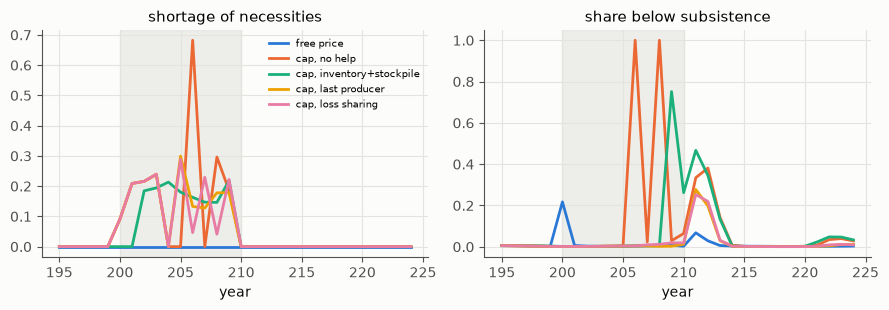

In [54]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
yrs = np.arange(195, 225)
for i, (lab, _, _) in enumerate(cases7):
    rs = [r for r in out7 if r and r['lab'] == lab]
    en = ['free price', 'cap, no help', 'cap, inventory+stockpile', 'cap, last producer', 'cap, loss sharing'][i]
    axs[0].plot(yrs, np.mean([r['path_short'] for r in rs], 0), color=PAL[i], label=en)
    axs[1].plot(yrs, np.mean([r['path_hungry'] for r in rs], 0), color=PAL[i])
for ax in axs:
    ax.axvspan(200, 210, color=GRID, alpha=0.6)
axs[0].set(xlabel='year', title='shortage of necessities'); axs[1].set(xlabel='year', title='share below subsistence')
axs[0].legend(fontsize=7); plt.tight_layout(); plt.show()

- **「誰も作りたがらない」は、費用の急騰と価格の上限が重なったときに起きる**。上限を置いて手当てをしないと、品不足が出て、年によっては必需品がほとんど作られない。生存の量に届かない人が大きく増える。能力の損失だけでは、品不足はほとんど出ない(残業で作れるため)。
- **価格を自由にすると、品不足は出ないが、物価が上がり、実質賃金と雇用を大きく失う**。生存の量に届かない人は、値段が高くて買えない人として少し出る。**上限は、物価と実質賃金と雇用の損を小さくするが、その代わりに一部の人を飢えさせる**。どちらが「良い」かは、何を見るかで逆になる。
- **最後の生産者が最もよい**。生存の量に届かない人は、手当てなしのときの数分の一になり、雇用と実質の生産の損も小さい。費用(補填)は所得の 1% ほどで、国債はほとんど増えない(経済が強くなる分、税収が増える)。当初の目論見「最後の生産者は品不足を防ぐが、国債を増やす」は、半分外れた。
- **損失の分担(元の規則)は、最後の生産者に近い**が少し劣る(ほかの部門の利益を削って、その投資を減らす)。作者の元の規則は、生存の量まで作らせる形にすれば、筋のよい危機時の仕組みだった。
- **在庫と備蓄は、10 年の上限には足りない**。上限のあいだは在庫と備蓄で持ちこたえても、それを使い果たし、上限を外した直後の値上がりの年に、届かない人が出る。

ノートの外の記録(標本 2000 記入、種 12 個)も同じである。上限の長さを変えた比べ(C2)では、**上限が短ければ(2 年)在庫と備蓄で足り、長ければ最後の生産者が要る**。

In [55]:
record('stage7', 'C1')
record('stage7', 'C2')

C1 原料の費用の急騰(原料の一製品あたり労働 ×1.5 を 10 年)と、必需品の能力の 4 割の損失(200 年目)。必需品の価格の上限は、打撃の前の価格で 10 年
   15 年(200〜214 年)。品不足 = 家計の必需品の需要のうち買えなかった割合。生存の量に届かない人 = 割り当てで一人 q0 に届かない人の割合
   差と比は、同じ種で打撃のない歴史に対して。補填 = 最後の生産者の政府の補填、分担 = 損失の分担で他の部門が払った額
  場合                        | 崩れ | 品不足(平均) | 品不足(頂) | 生存の量に届かない人の割合の平均 | 同(打撃のない歴史) | 生存の量の不足(平均) | 物価の頂 | 実質の生産 | 雇用 | 実質賃金 | 国債/所得の差 | 必需品の能力 | 他の能力 | 補填/所得 | 分担/所得
  上限なし(価格は自由)                |  0 | 0.000±0.000 | 0.000±0.000 | 0.024±0.001 | 0.002±0.000 | 0.0014±0.0001 | +0.424±0.001 | -0.143±0.004 | -0.243±0.001 | -0.208±0.001 | -0.155±0.004 | -0.067±0.002 | +0.040±0.006 | 0.0000±0.0000 | 0.0000±0.0000
  上限なし + 在庫                  |  0 | 0.000±0.000 | 0.000±0.000 | 0.022±0.001 | 0.002±0.000 | 0.0014±0.0001 | +0.405±0.001 | -0.146±0.004 | -0.239±0.001 | -0.206±0.001 | -0.153±0.004 | -0.067±0.002 | +0.030±0.007 | 0.0000±0.0000 | 0.0000±0.0000
  上限、手当てなし                   |  0 | 0.131±0.002 | 0.749±0.036 | 0.189±0.006 | 0.002±0.000 | 0.0551±0.0027 | +0.285±0.0

### 7.3 需要の不足の不況と、公共事業

もう一つの「作りたがらない」は、需要が足りない不況である(労働者の消費の割合が 0.9 → 0.75 を 10 年)。このとき、**必需品は赤字にならない**(需要の弾力が小さく、売れ続ける)ので、最後の生産者は効かない(当初の目論見「需要の不足の不況でも、最後の生産者が効く」は外れた)。効くのは需要を足すことで、**公共事業は、同じ額の給付より少しよく効く**(所得の 2% で、不況の 10 年の雇用の落ち込み −9.6% → −6.9%、給付では −7.3%)。ノート M の gj_6 の「公共事業」の主張は、帳簿を閉じた模型でも、弱い形で残る。差が小さいのは、家計の消費の割合が高く、給付もほとんど使われるためである。

In [56]:
record('stage7', 'C4')

C4 需要の不足(同じ 10 年の不況)で、公共事業(投資財を去年の所得の 2% 買う)と、同じ額の一人あたり同額の給付を比べる(不況の 10 年だけ)
  場合                        | 崩れ | 品不足(平均) | 品不足(頂) | 生存の量に届かない人の割合の平均 | 同(打撃のない歴史) | 生存の量の不足(平均) | 物価の頂 | 実質の生産 | 雇用 | 実質賃金 | 国債/所得の差 | 必需品の能力 | 他の能力 | 補填/所得 | 分担/所得 | 不況の 10 年の雇用 | 不況の 10 年の実質の生産
  何もしない                      |  0 | 0.000±0.000 | 0.000±0.000 | 0.020±0.001 | 0.002±0.000 | 0.0011±0.0001 | +0.104±0.001 | -0.122±0.003 | -0.116±0.001 | -0.038±0.002 | -0.019±0.003 | -0.061±0.003 | +0.112±0.007 | 0.0000±0.0000 | 0.0000±0.0000 | -0.096±0.002 | -0.211±0.006
  公共事業 2%                    |  0 | 0.000±0.000 | 0.000±0.000 | 0.012±0.001 | 0.002±0.000 | 0.0009±0.0001 | +0.085±0.001 | -0.099±0.003 | -0.083±0.002 | -0.032±0.002 | +0.013±0.004 | -0.047±0.003 | +0.105±0.005 | 0.0000±0.0000 | 0.0000±0.0000 | -0.069±0.002 | -0.176±0.005
  給付 2%                      |  0 | 0.000±0.000 | 0.000±0.000 | 0.012±0.001 | 0.002±0.000 | 0.0008±0.0001 | +0.094±0.001 | -0.102±0.003 | -0.089±0.002 | -0.036±0.002 | -0.008±0.00

### 7.4 この章のまとめ(作者の元の関心への答え)

- 「どの企業も生産したがらない」は、価格が自由な経済では起きない。**費用の急騰に価格の上限が重なると現れる**。
- そのとき、品不足と飢えを防ぐには、**生存の量を保つ「最後の生産者」**が最もよく、費用は所得の 1% ほどで、経済そのものも強くなる。作者の元の規則(損失の分担)は、それに近い。
- 在庫と備蓄は、短い危機には十分で、長い危機には足りない。
- 価格を自由にすれば品不足はないが、物価の上昇で実質賃金と雇用を大きく失う。上限は、その損を小さくする代わりに、一部の人を飢えさせる。危機の政策は、「飢える人」と「実質賃金の損」のどちらを見るかで、評価が逆になる。

---

## 第 8 章 お金が眠るとき ── 死蔵と準備率、ρ_eff の正体

信用循環モデルのシリーズの初めから、JRF には一つの宿題があった。

> // 分配集中・実効準備率<br>
> Φ = r·C / max(Y, ε)<br>
> ρ_eff = ρ + μ·max(0, Φ − θ)<br>
> …がそれで良かったのか…まだ、納得していない。

これまでに、二つの根拠を出してきた。

1. **信用の流れからの根拠**(ノート credit_creation_v6): 銀行の貸倒れと、貸し手の慎重さから、信用の流れから漏れる割合の誘導形として、この折れ線が出る。
2. **主体の側からの根拠**(ノート 3 第 5 章): お金がだぶつくと、まず大バクチが増えて上限で頭打ちになり、次に**死蔵**が増える。死蔵の割合は、上位への富の集中度の折れ線になり(Lean の定理 `hoard_as_rho_eff`)、上位の富を利子の所得の元本とみると、ρ_eff と同じ形が出る。

im では、第 3 章で、この形を「貸し手の慎重さ」(金利の上乗せ)として**書き込んで**使った。段 16 では、逆に、死蔵の**仕組み**を部品として入れ、書き込んだ形と同じ答えが出るかを確かめた。

### 8.1 死蔵と準備の縛りの作り

- **死蔵**: 一人あたりの預金が平均の 5 倍を超えた分を、銀行の外の現金として持つ(利子がつかない。使うことはできる)。ノート 3 の「上限まで埋まった種類の次に、お金は死蔵へ流れる」の形。
- **準備の縛り**: 準備の量が決まっている経済('fixed'。準備は所得の 0.35 倍)では、死蔵(銀行の外への現金の流出)が準備を吸い取る。銀行は、残りの準備 ÷ 準備率まで貸せる。貸せる割合
  cf = (準備 − 死蔵) / (準備率 × 銀行の中の預金)(0〜1)
  が、企業の新しい借入、投資の資金、家計の無担保の借入の上限を絞る。
- 準備が求められるだけ出る経済('endog'。im の既定)では、縛りはない。

準備が預金より少ない限り、死蔵が増えるほど、貸せる割合は下がる。Lean で確かめておく。

In [57]:
%%writefile -a integrated_model.lean
/-! ## 第 8 章 死蔵と準備の縛り

準備の量 R が決まっていて、預金 D のうち H が死蔵(銀行の外の現金)になると、銀行が新しく貸せる割合(信用の係数)は
cf = (R − H) / (ρ (D − H))。準備が預金より少ない(R ≤ D)限り、死蔵が増えるほど、信用の係数は下がる。 -/
theorem credit_factor_antitone {R D ρ H₁ H₂ : ℝ} (hρ : 0 < ρ) (hRD : R ≤ D) (h12 : H₁ ≤ H₂) (h2 : H₂ < D) :
    (R - H₂) / (ρ * (D - H₂)) ≤ (R - H₁) / (ρ * (D - H₁)) := by
  have d1 : 0 < ρ * (D - H₁) := mul_pos hρ (by linarith)
  have d2 : 0 < ρ * (D - H₂) := mul_pos hρ (by linarith)
  rw [div_le_div_iff₀ d2 d1]
  nlinarith [mul_nonneg (sub_nonneg.mpr h12) (sub_nonneg.mpr hRD), hρ.le]

Appending to integrated_model.lean


### 8.2 集中の度合いを変えて、縛りの形を見る

初めの持分を平等にし、家計ごとの資産の運(第 12 章)の大きさ σ で、富の集中の度合いを変える。準備は固定。その場で回す(種 3 個、標本 2000 記入)。

In [58]:
B8 = dict(BASE, Ns=2000, eq_init='equal', hoard=True, reserves='fixed', res_supply=0.35, rho_res=0.1)
sigmas = (0.0, 0.05, 0.1, 0.15, 0.2, 0.3)
res8 = runs([(f'運 σ = {sg}', dict(luck_sigma=sg)) for sg in sigmas], seeds=range(3), T=300,
            keys=('top10_inc', 'cf', 'hoard', 'deposits', 'loans', 'Y', 'E'), base=B8)
table(res8, [('所得の上位10%(Φ)', 'top10_inc', 'mean', '.3f'), ('死蔵/預金', lambda r: np.mean(r['hoard'][150:] / r['deposits'][150:]), None, '.3f'),
             ('貸せる割合', 'cf', 'mean', '.2f'), ('企業の貸出/所得', lambda r: np.mean(r['loans'][150:] / r['Y'][150:]), None, '.3f'),
             ('雇用', 'E', 'mean', '.0f')], burn=150)

  場合                             | 所得の上位10%(Φ) | 死蔵/預金 | 貸せる割合 | 企業の貸出/所得 | 雇用
  運 σ = 0.0                      | 0.208±0.001 | 0.155±0.007 | 1.00±0.00 | 0.629±0.001 | 590±0
  運 σ = 0.05                     | 0.211±0.001 | 0.199±0.004 | 0.98±0.00 | 0.632±0.000 | 588±0
  運 σ = 0.1                      | 0.216±0.000 | 0.320±0.005 | 0.47±0.01 | 0.568±0.004 | 596±1
  運 σ = 0.15                     | 0.222±0.001 | 0.458±0.021 | 0.11±0.04 | 0.491±0.016 | 599±0
  運 σ = 0.2                      | 0.226±0.001 | 0.549±0.025 | 0.00±0.00 | 0.459±0.012 | 600±2
  運 σ = 0.3                      | 0.228±0.000 | 0.629±0.018 | 0.00±0.00 | 0.466±0.012 | 597±2
  (帳簿と標本の差/所得の最大 8e-14)


準備の縛り(1 − 貸せる割合)= 57.4 × max(0, Φ − 0.209)、R² = 0.930


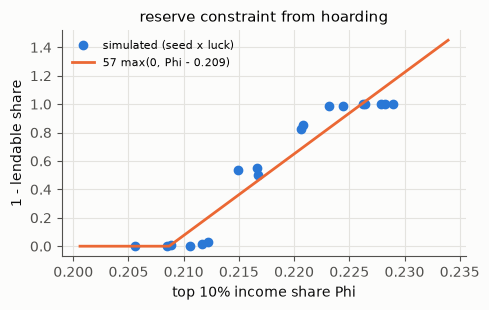

In [59]:
from scipy.optimize import curve_fit
phi, gap = [], []
for rs in res8.values():
    for r in rs:
        if r is not None:
            phi.append(r['top10_inc'][150:].mean()); gap.append(1 - r['cf'][150:].mean())
phi, gap = np.array(phi), np.array(gap)
hinge = lambda x, a, th: a * np.maximum(0.0, x - th)
(a, th), _ = curve_fit(hinge, phi, gap, p0=(50, 0.2))
r2 = 1 - np.sum((gap - hinge(phi, a, th)) ** 2) / np.sum((gap - gap.mean()) ** 2)
print(f'準備の縛り(1 − 貸せる割合)= {a:.1f} × max(0, Φ − {th:.3f})、R² = {r2:.3f}')
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(phi, gap, 'o', color=PAL[0], label='simulated (seed x luck)')
xs = np.linspace(phi.min() - 0.005, phi.max() + 0.005, 100)
ax.plot(xs, hinge(xs, a, th), color=PAL[1], label=f'{a:.0f} max(0, Phi - {th:.3f})')
ax.set(xlabel='top 10% income share Phi', ylabel='1 - lendable share', title='reserve constraint from hoarding')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**準備が固定なら、準備の縛りは、所得の集中 Φ のきれいな折れ線になる**。これは、書き込んだ ρ_eff = ρ + μ·max(0, Φ − θ) の形そのものである。閾値 θ は、準備の量と、死蔵の始まる預金の水準から決まり、「死蔵が準備を吸い取りはじめる集中の度合い」という意味を持つ。ノートの外の記録(種 8 個、運の大きさの刻みが細かい)では、1 − 貸せる割合 = 50 × max(0, Φ − 0.207)、R² = 0.998 だった。その場の計算で当てはまりが少し悪いのは、運が大きい(σ ≥ 0.2)と、貸せる割合が 0 に張り付き、折れ線がそこで頭打ちになるためである(縛りには上限がある。v6 の ρ_eff も、実際には 1 で頭打ちになる)。

In [60]:
record('stage16', 'H16')

H16 富の集中(運 σ)と、死蔵・準備の縛り・貸出。死蔵 = 一人あたりの預金の平均の 5 倍を超えた分(銀行の外の現金、利子なし、準備を吸い取る)
   (a) 書き込んだ ρ_eff の形(上乗せ金利 μ softplus(Φ − θ)、μ = 1、θ = 0.15。死蔵なし)、(b) 死蔵 + 準備は求められるだけ(今の im)、
   (c) 死蔵 + 準備の量は所得の 0.35 倍に固定(準備率 0.1)
  (a) 書き込んだ ρ_eff の形
    運 σ | 所得の上位10%(Φ) | 預金の上位1% | 死蔵/預金 | 準備の縛り(貸せる割合) | 上乗せ金利 | 貸出の金利 | 企業の貸出/所得 | 雇用
    0.00 | 0.254 | 0.225 | 0.000 | 1.00 | 0.1042 | 0.1442 | 0.622 | 382
    0.05 | 0.259 | 0.302 | 0.000 | 1.00 | 0.1088 | 0.1488 | 0.620 | 367
    0.10 | 0.266 | 0.423 | 0.000 | 1.00 | 0.1162 | 0.1562 | 0.610 | 340
    0.15 | 0.270 | 0.500 | 0.000 | 1.00 | 0.1203 | 0.1603 | 0.600 | 318
    0.20 | 0.272 | 0.574 | 0.000 | 1.00 | 0.1218 | 0.1618 | 0.593 | 304
    0.30 | 0.272 | 0.687 | 0.000 | 1.00 | 0.1223 | 0.1623 | 0.590 | 294
    (帳簿と標本の差/所得の最大 4e-14)
  (b) 死蔵 + 準備は内生
    運 σ | 所得の上位10%(Φ) | 預金の上位1% | 死蔵/預金 | 準備の縛り(貸せる割合) | 上乗せ金利 | 貸出の金利 | 企業の貸出/所得 | 雇用
    0.00 | 0.204 | 0.160 | 0.136 | 1.00 | 0.0000 | 0.0400 | 0.623 | 589
    0.05 | 0.208 | 0.211 | 0.172 | 1.00 | 0.000

記録の三つの場合を並べると、もう一つのことがわかる。

- **(b) 準備が求められるだけ出るなら、縛りは現れない**(貸せる割合はいつも 1)。死蔵は増えるが、中央銀行が埋める。
- **(c) 仕組みの版(量の縛り)では、企業の貸出は減るが、雇用はほとんど変わらない**(むしろ少し上がる)。im の投資は、ほとんど内部の資金で賄われ、貸出が減ると利払いも減るためである。
- **(a) 書き込んだ形(金利の上乗せ)は、強く効く**。上乗せが貸出の金利を上げ、r̄ を通じて値上げ幅と物価を押し上げ、雇用を大きく下げる(第 3 章)。

### 8.3 JRF の宿題への答え

1. **形(折れ線)は正しい**。準備が足りない経済では、富む家計の死蔵の仕組みから、R² = 0.998 で出る。θ は「死蔵が準備を吸い取りはじめる集中の度合い」として意味を持つ。これで、根拠は三つになった(信用の流れ、主体の資産配分、統合した経済の中の仕組み)。
2. **ただし、準備が求められるだけ出る経済では、形は仕組みからは出ない**。そこでは、ρ_eff は貸し手の心理(流動性の選好、慎重さ)の仮定として残る。今の多くの中央銀行は、金利を決めて準備を求められるだけ出すので、こちらが現実に近い。
3. **効き目は、量に効くか値段に効くかで大きく違う**。v6 の ρ_eff は信用の流れの量に効く形で、im の書き込んだ形は金利に効く形である。im の中では、量の縛りは雇用をほとんど変えず、金利の上乗せは強く効く。分配の集中が経済を傷めるとすれば、その主な道は、貸し手が慎重になって**金利を上げる**ことのほうである。

---

# 第 IV 部 学び、探し、楽しむ

## 第 9 章 学習と政治

ここまでの経済は、守りの量も税率も、外から与えていた。段 5 では、社会が災害の頻度を**記録から学び**、守りの量を自分で決めるようにした。政策のつまみの一部(資本所得への税)は、**投票**で内側から決めるようにした。段 12 と段 13 では、人間の注意の有限さと、信念の区間を足した。

### 9.1 災害の頻度を学ぶ、そして忘れる

- 社会は、災害の年ごとの回数を記録から学ぶ(ガンマ・ポアソンの共役の更新。ノート 3 第 7.7 節)。古い記録は毎年 ω で割り引く(ω = 1 なら忘れない。ω = 0.95 なら、記録の実効の年数は 20 年ほど)。
- 守りの量 = min(5%, 0.2 × 信じている頻度)(第 6 章の守りの資本を、信念で決める)。
- 信念の取り方: 中立(事後の平均)のほか、**信念の区間**(ノート I 第 5 章のビューリーの読み)の上の端に備える取り方(α-maxmin)。

災害の頻度が時代で変わる世界を作る。300 年目までは毎年 1%、そこから 10% の荒れた時代、450 年目から 1% に戻る。その場で回す(種 4 個)。

In [61]:
B9 = dict(BASE, disaster=True, dis_rate=0.01, relief='state', learn=True)
shocks9 = ((300, dict(dis_rate=0.10)), (450, dict(dis_rate=0.01)))
cases = [('忘れない(ω = 1)', dict(learn_omega=1.0)),
         ('記録 20 年で忘れる(ω = 0.95)', dict(learn_omega=0.95)),
         ('忘れない、区間の上の端に備える', dict(learn_omega=1.0, learn_attitude='interval', amb_alpha=1.0)),
         ('守りを固定 1%', dict(learn=False, protect=0.01))]
res9 = runs(cases, seeds=range(4), T=600, keys=('belief', 'protect', 'breakups', 'Y', 'bN'), shocks=shocks9, base=B9)
w = lambda a, b: (lambda r: r['protect'][a:b].mean())
bk = lambda a, b: (lambda r: r['breakups'][a:b].sum() / (b - a) * 100)
table(res9, [('守り(静か)', w(200, 300), None, '.4f'), ('守り(荒れ)', w(300, 450), None, '.4f'), ('守り(また静か)', w(450, 600), None, '.4f'),
             ('一家離散/100年(荒れ)', bk(300, 450), None, '.0f'), ('一家離散/100年(また静か)', bk(450, 600), None, '.0f')], width=34)

  場合                                 | 守り(静か) | 守り(荒れ) | 守り(また静か) | 一家離散/100年(荒れ) | 一家離散/100年(また静か)
  忘れない(ω = 1)                        | 0.0028±0.0005 | 0.0062±0.0007 | 0.0084±0.0006 | 125±57 | 82±3
  記録 20 年で忘れる(ω = 0.95)              | 0.0042±0.0003 | 0.0163±0.0011 | 0.0077±0.0004 | 67±8 | 84±5
  忘れない、区間の上の端に備える                    | 0.0055±0.0007 | 0.0093±0.0008 | 0.0115±0.0007 | 68±9 | 85±3
  守りを固定 1%                           | 0.0100±0.0000 | 0.0100±0.0000 | 0.0100±0.0000 | 66±6 | 88±3
  (帳簿と標本の差/所得の最大 7e-15)


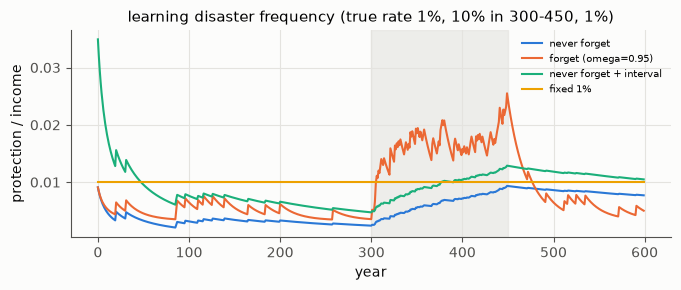

In [62]:
fig, ax = plt.subplots(figsize=(7, 3))
for i, lab in enumerate(res9):
    en = ['never forget', 'forget (omega=0.95)', 'never forget + interval', 'fixed 1%'][i]
    ax.plot(mean_series(res9[lab], 'protect'), color=PAL[i], label=en, lw=1.5)
ax.axvspan(300, 450, color=GRID, alpha=0.6)
ax.set(xlabel='year', ylabel='protection / income', title='learning disaster frequency (true rate 1%, 10% in 300-450, 1%)')
ax.legend(fontsize=7); plt.tight_layout(); plt.show()

- **忘れない社会は、静かな 300 年の記録に引きずられ、荒れた時代にも守りが上がらない**。荒れた時代の一家離散が多い。
- **記録を 20 年ほどで忘れる社会は、荒れた時代に守りを素早く上げ**、一家離散を抑える。静かな時代に戻ると、守りを下げる(そして、次の荒れた時代にまた不意を突かれうる)。
- **忘れない社会でも、信念の区間の上の端に備えると、忘れることの代わりになる**(記録の量が多くても、構造の不確かさがあると区間は縮みきらない。ノート I の結論)。忘れる社会で区間の上の端に備えると、守りすぎになる(記録 B1)。

ノートの外の記録(種 12 個)と、事前学習の比べも見ておく。若い社会では、縮めた模型の 3000 年の記録から始めると、初めの 50 年の一家離散が 3 分の 1 になる。**記録(歴史)の値打ちは、社会の若いうちに出る**。

In [63]:
record('stage5', 'L2')
record('stage13', 'B1')

L2 事前学習。若い社会(0 年目から)。災害の頻度は毎年 5%。100〜200 年目を比べる。乱数の種 12 個
  楽観的な初めの信念(頻度 0.5%、重み 20 年)               初めの 50 年の守り 0.0046  一家離散(初めの 50 年、100 年あたり)128±55  100〜200 年: 実質の生産 2634±15  一家離散 53±3
  縮めた模型の 3000 年の記録から                       初めの 50 年の守り 0.0098  一家離散(初めの 50 年、100 年あたり)46±5  100〜200 年: 実質の生産 2619±7  一家離散 55±3
  同じ、ただし記録は ω = 0.99 で割り引く                 初めの 50 年の守り 0.0070  一家離散(初めの 50 年、100 年あたり)49±8  100〜200 年: 実質の生産 2636±9  一家離散 53±3
B1 信念の区間(ノート I 第 5 章)。災害の頻度が時代で変わる(段 5 の L1 と同じ: 300 年目までは毎年 1%、そこから 10%、450 年目から 1%)
   区間 = 事後の分布の 5〜95%、床 = 区間を少なくとも平均 × (1 ± 床) に広げる(構造の不確かさ)。α = 1 は最悪に備える(maxmin)、0.5 は真ん中
  社会                          | 守り(静か 200-300 / 荒れ 300-450 / 静か 450-600) | 実質の生産(静か / 荒れ / 静か) | 一家離散/100年(荒れ / 静か)
  中立(平均)、ω = 0.95              | 0.0040 / 0.0165 / 0.0064 | 2568 / 2571 / 2512 | 72±2 / 77±2
  悲観(上側 90%)、ω = 0.95          | 0.0102 / 0.0301 / 0.0145 | 2550 / 2510 / 2462 | 75±2 / 78±3
  区間 α=1、床 0、ω = 0.95          | 0.0142 / 0.0356 / 0.0189 | 2539 / 2487 / 2446 

### 9.2 投票の相転移

政策のつまみの一つ、資本所得への税(低い案 0.1 か高い案 0.5。税収は一人あたり同じ額で配る)を、10 年ごとの投票で決める(ノート M 第 4 章)。

- 資産所得の割合が半分を超える世帯(資産家)は低い税、ほかの世帯(労働者)は高い税を好む。
- 群れ g の投票率 = 1 − exp(− 賭け金 × √(ρ_g/π) / 費用の平均)。ρ_g は、群れの中の投票の決定の相関である。ノート M で、ダウンズの「一票は無意味」への反論として導いた形で、相関のある群れの一人の票は、√(ρ/π) の重みで結果に効く。
- 人数を重みにした票の多い案になる。

In [64]:
record('stage5', 'V1')

V1 投票で資本所得への税(0.1 か 0.5。税収は一人あたり同じ額で配る)を 10 年ごとに決める。災害なし。400 年の後半 200 年
   群れの中の相関 ρ(ノート M 第 4 章: 投票の効き目は √(ρ/π))。投票の費用の平均は一人あたりの所得の 1%
  群れの相関                          | 高い税の年の割合 | 投票率 労働者 / 資産家 | 資産家の人数 | 雇用 | 実質の生産 | 正味資産の上位10% | 所得の上位10%
  資産家 ρ_k = 0.0001、労働者 ρ_w = 1e-08   | 0.00±0.00 | 0.000 / 0.382 | 37 | 532 | 2237 | 0.613 | 0.218
  資産家 ρ_k = 0.0001、労働者 ρ_w = 1e-07   | 0.00±0.00 | 0.001 / 0.382 | 37 | 532 | 2237 | 0.613 | 0.218
  資産家 ρ_k = 0.0001、労働者 ρ_w = 1e-06   | 0.00±0.00 | 0.003 / 0.382 | 37 | 532 | 2237 | 0.613 | 0.218
  資産家 ρ_k = 0.0001、労働者 ρ_w = 1e-05   | 0.00±0.00 | 0.009 / 0.382 | 37 | 532 | 2237 | 0.613 | 0.218
  資産家 ρ_k = 0.0001、労働者 ρ_w = 0.0001  | 0.60±0.01 | 0.021 / 0.309 | 27 | 412 | 1627 | 0.532 | 0.179
  資産家 ρ_k = 0.0001、労働者 ρ_w = 0.001   | 0.60±0.01 | 0.064 / 0.309 | 27 | 412 | 1627 | 0.532 | 0.179
  資産家 ρ_k = 0.0001、労働者 ρ_w = 0.01    | 0.82±0.03 | 0.154 / 0.340 | 23 | 390 | 1694 | 0.495 | 0.174
  資産家 ρ_k = 0.01、労働者 ρ_w = 1e-08     | 0.00±0.00 | 0.000 / 0.797 

**投票の相転移**: 高い税が選ばれるのは、労働者の群れの相関 ρ_w が、ある境目を越えたときだけで、その手前では一度も選ばれない。境目は、資産家の群れの相関(組織)が強いほど高い。**ρ_w が一桁変わるだけで、政策が飛ぶ**(ノート M の「境目は ρN の桁」)。高い税が選ばれる設定でも、政策は行き来する(高い税で資本所得が減ると、資産家の数も、労働者の賭け金も減り、低い税に戻る)。そして、投票で選ばれた政策の効き目は、記録(V2)では、投資の行動の仮定で逆になった(基準の仮定では高い税で雇用が下がり、需要主導では上がる。税が行き来する経済での比べで、第 17 章の静かな比べとは条件が違う)。

この相転移は、第 16 章で、箱庭の中の一人のプレイヤーが、群れの相関を動かして政策を替えうるか、という問いの舞台になる。

### 9.3 人間の有限の注意(慣性)

作者は、経済には慣性があるはずだ、と書いていた。段 12 では、それを家計の注意の有限さとして入れた。毎年、群れのうち割合 ζ だけが決め直し、残りは去年の実質の予算を続け、資産の配分(土地・株・知財・外の資産)も、望む保有へ近づく速さが ζ だけ遅くなる。

In [65]:
record('stage12')

I1 需要の不足(労働者の消費の割合 0.9 → 0.75 を 10 年)。雇用の比(同じ種で打撃のない歴史に対して)
  決め直す割合 | 雇用の底 | 40 年の雇用の損の和 | 打撃のあと 30 年の平均 | 打撃のあと底の半分に戻るまでの年
  1.00         | -0.254±0.004 | -1.69±0.09 | -0.027±0.002 | 0.0±0.0
  0.50         | -0.156±0.001 | -1.42±0.01 | -0.024±0.000 | 5.3±0.1
  0.25         | -0.087±0.000 | -0.59±0.01 | -0.011±0.000 | 6.0±0.0
I2 土地のユーフォリアと利上げ(段 2 の S2、担保の掛け目 0.6)
  決め直す割合 | 土地の実質の値段の頂 | 底 | 雇用の底 | 貸倒れ/所得(40 年の和)
  1.00         | 3.14±0.08 | 0.45±0.02 | 0.900±0.009 | 0.0611±0.0065
  0.50         | 3.48±0.00 | 0.47±0.00 | 0.931±0.001 | 0.2195±0.0119
  0.25         | 3.44±0.00 | 0.45±0.00 | 0.876±0.001 | 0.5528±0.0237
I3 需要で値段を決める株式の市場(段 5 の X3-4。暴れた設定)
  決め直す割合 | 崩れた割合 | 値段/基本の値打ち | 物価 | 株の実質の利回りの揺れ
  1.00         | 0.00±0.00 | 58.04±12.77 | +0.138±0.024 | 0.430±0.033
  0.50         | 0.00±0.00 | 106.72±5.46 | +0.191±0.008 | 0.338±0.014
  0.25         | 0.00±0.00 | 32.30±7.90 | +0.126±0.023 | 0.508±0.031
I4 速く動く資本と変動の為替(段 6 の K0、二地域)。乱数の種 6 組
  決め直す割合 | 為替の年の変化の標準偏差 | A の雇用
  1.00      

- **需要の打撃は浅くなり、戻りは遅くなる**(決め直さない世帯は、打撃のあいだも去年の消費を続ける)。
- **速く動く資本の暴れ(第 5 章)は、注意で止まる**。
- しかし、**土地の泡のあとの貸倒れは、注意が足りないほど大きい**(借金を返すのが遅れる)。**自己参照の泡(需要で値段を決める株)は、注意では止まらない**(近づく速さを遅くしても、たどり着く先は泡のまま)。

慣性が安定させるのは、流れの速さが不安定の元のときに限られる。

### 9.4 三つの勘定と、危機のときの探索

ノート I の「贅沢品 = 探索」を受けて、家計の支出を三つの勘定に分けて記録した。**使う**(必需品)、**探す**(贅沢品のうち自主研究の分と、企業の研究)、**貯める**。必需品の能力が半分になる危機で、探すの勘定は使うより大きく削られる。ただし、30 年で見ると、建て直しの好況のあいだに取り戻し、打撃のない歴史を上回った(当初の目論見「危機で探索が削られ、長い目の技術や文化の進みが落ちる」は、この打撃では外れた)。

In [66]:
record('stage13', 'B2')

B2 三つの勘定(使う = 必需品、探す = 贅沢品のうち自主研究の分 + 企業の研究の賃金、貯める = 可処分所得 − 支出)。300 年目に必需品の能力が半分
   所得に対する割合の、打撃のない同じ種の歴史との差(最初の 5 年の平均、ポイント)。実質 = 必需品の値段で割った量の比
  場合                         | 使う/所得の差 | 贅沢品/所得の差 | 探す/所得の差 | 貯める/所得の差 | 実質の使う | 実質の贅沢品 | 実質の探す | 30 年の実質の探すの損(打撃の前の一年分に対する比) | 30 年後の種類の数の比
  研究なし                         | -2.05 | -6.96 | -0.70 | +11.76 | 0.948 | 0.808 | 0.808 | +0.89 | nan
  研究 2%                        | +0.47 | -2.33 | -0.26 | +1.03 | 0.870 | 0.827 | 0.839 | +0.43 | nan
  研究 2% + 文化(ψ=1 ε=2)          | +1.62 | -1.84 | -0.21 | +0.09 | 0.923 | 0.836 | 0.840 | +0.28 | 0.969


### 9.5 この章のまとめ

- 社会が災害の頻度を記録から学ぶと、守りの量は内から決まる。忘れる社会は変化に素早く追いつき、忘れない社会は古い記録に引きずられる。信念の区間は、忘れない社会の過信の歯止めになる。記録(歴史)の値打ちは、社会の若いうちに出る。
- 投票で税を決めると、群れの相関の一桁の違いで政策が飛ぶ(相転移)。
- 注意の有限さ(慣性)は、需要の打撃と速い資本の暴れを和らげるが、借金の返済を遅らせ、自己参照の泡は止めない。
- 危機は、まず探索を削るが、建て直しで取り戻す。

---

## 第 10 章 研究と世界樹

ここまでの技術の進み(新しい生産能力の一製品あたり労働が毎年下がる率)は、外から与えるか、0 にしていた。段 5 の探索で、企業が研究し、技術の進みを内から作るようにした。

### 10.1 研究は、誰の得になるか

- 企業は売上の割合 s_R の額で研究の人を雇う(額は去年の利益の半分まで)。試行は確率 p_hit で当たり、当たりの大きさは裾の重い分布(パレート型)。当たりは最先端の技術を下げ、投資を通じて生産能力に乗る。
- 研究の割合を、過去の当たりから学ぶこともできる(ノート I の探索と活用)。

記録から(標本 2000 記入、種 16 個)。

In [67]:
record('stage5b', 'X1')

X1 研究の割合(売上に対して固定)と、当たりの大きさの裾(指数 α。小さいほど巨大な当たりが出る)。当たり一回の平均の大きさは 0.006 に揃える
   技術の進み = 最先端の労働の係数が一年に下がる割合。崩れ = 名目の賃金が 1/1000 を下回ったデフレの渦(16 種のうち)。他の数は崩れなかった種の平均
   当たりなし = 研究に人を雇うが当たらない(需要としての研究だけ)。研究の額は去年の利益(利子のあと)の半分までに縛る
   一番の当たりの割合 = 300 年の向上のうち、一番大きな一年の当たりが占める割合(裾が重いと、少数の大当たりが技術の進みを決める)
  場合            | 崩れ | 技術の進み | 実質の生産の伸び | その揺れ | 雇用 | 失業者 | 実質賃金の伸び | 実質配当の伸び | 所得の上位10% | 富の上位10% | 物価 | 一番の当たりの割合
  研究なし             |  0 | 0.0000±0.0000 | -0.0001 | 0.048 | 585 | 415 | +0.0007 | -0.0005 | 0.215 | 0.621 | +0.020 | 0.00
  当たりなし s_R=0.02   |  0 | 0.0000±0.0000 | +0.0002 | 0.056 | 589 | 411 | +0.0003 | -0.0002 | 0.189 | 0.534 | +0.035 | 0.00
  α=3.0 s_R=0.01   |  0 | 0.0023±0.0000 | +0.0039 | 0.024 | 884 | 116 | +0.0026 | +0.0027 | 0.198 | 0.563 | +0.021 | 0.02
  α=3.0 s_R=0.02   |  0 | 0.0049±0.0000 | +0.0050 | 0.014 | 962 | 38 | +0.0047 | +0.0029 | 0.169 | 0.473 | +0.023 | 0.01
  α=3.0 s_R=0.03   |  0 | 0.0069±0.0001 | +0.0056 | 0.009 | 987 | 13 | +0.0064 | +0.0015 | 0.140 | 0.351

- 研究は、外から与えていた技術の進みを、内から作る(s_R = 0.02 で年 0.5% ほど)。
- **研究の得は、主に労働者に回る**。値上げ幅が競争で一定なら、当たりの得は値段の下がりで賃金と買い手に回り、研究の費用は配当から出る。
- **研究をしすぎると崩れる**(研究の人の需要で物価が上がり、そのあとの赤字と借金でデフレの渦。大当たりが物価を急に下げ、名目の借金を重くする。フィッシャーの負債デフレ)。
- **重い裾と短い記憶は、学ぶ企業に研究をあきらめさせる**(当たりの出ない年が続くと見込みが下がり、研究を減らし、さらに当たらない。ノート I の結論の再現)。救うのは、**探索の床**(下回らない研究の割合)か、長い記憶である。

### 10.2 世界樹: 規則的に研究する者と、真似る者

JRF には、2017 年からの見方がある(cocolog:87083159。『宗教学雑考集』《ジャンケンと世界樹》)。学習が効くのは、負けるのを承知で規則的に手を出す者がいるからで、「思考」が有利な状況を作ったのは、動物に負け続ける植物たちだった。知識の源(世界樹)は、規則的な者が支えている。

これを確かめるため、部門の中に企業を 20 社置き、二つの型を混ぜた。

- **規則的な企業**: 見返りを見ずに、毎年同じ割合で研究する。
- **真似る企業**: 自分では研究せず、他社の当たりを見て真似る(知識の波及)。

占有率は、乗せた知識の差で決まる(費用の低い企業が客を取る)。利益の率の記憶が下がると退出し、参入は型ごとの利益で選ばれる。

In [68]:
record('stage5c', 'W1')

W1 部門に企業が一つの場合と、20 社の場合。型の混ぜ方と参入の仕方。「選ぶ」= 参入の型を、型ごとの占有率あたりの利益で選ぶ(突然変異 5%)。「固定」= 参入はいつも初めの割合
  場合                          | 技術の進み | 実質賃金の伸び | 雇用 | 所得の上位10% | 規則的な企業の占有率(最後の100年) | その揺れ | 集中(HHI) | 利益の率 規則的/真似る | 当たりのうち規則的な企業の分 | 退出/100年
  企業は一つ(段 5 の探索)               | 0.0047±0.0001 | +0.0045 | 957 | 0.170 |  —  |  —  |  —  |  —  |  —  |  — 
  20 社、すべて規則的                  | 0.0045±0.0002 | +0.0044 | 910 | 0.178 | 1.00±0.00 | 0.00 | 0.72 | 0.122/nan | 1.00 | 211
  20 社、すべて真似る                  | 0.0000±0.0000 | +0.0007 | 585 | 0.215 | 0.00±0.00 | 0.00 | 0.05 | nan/0.145 | 0.00 | 0
  20 社、半々、参入を選ぶ                | 0.0006±0.0001 | +0.0013 | 712 | 0.210 | 0.24±0.03 | 0.06 | 0.15 | 0.128/0.147 | 1.00 | 15
  20 社、半々、参入は固定                | 0.0009±0.0002 | +0.0014 | 731 | 0.208 | 0.28±0.04 | 0.06 | 0.18 | 0.128/0.147 | 1.00 | 19
  20 社、半々、真似が遅い ι=0.1          | 0.0037±0.0002 | +0.0040 | 867 | 0.184 | 0.88±0.02 | 0.11 | 0.63 | 0.125/0.143 | 1.00 | 156
  20 社、半々、真似が速い ι=0.6          | 0.0002±0.00

**真似る企業は、規則的な企業の当たりに乗って得をし、規則的な企業を追い出す**。そして、世界樹が枯れると、技術はほとんど進まなくなる。すべて真似る企業なら、誰も研究しないので、技術は進まない(世界樹がなければ、真似る者も育たない)。

### 10.3 世界樹を支えるもの: 知財の保護、公の研究所、国庫

規則的な研究を支える方法を、三つ比べる。

- **知財の保護**: 他社の知識は、ある年数だけ前のものしか真似られない。
- **公の研究所**: 政府が所得の割合で研究の人を雇う。その当たりは、どの企業も遅れなく真似られる。
- **国庫の案**(作者の 2021〜22 年の構想): 部門の利益(正の分)に税をかけ、その年の研究の当たりの大きさに比例して企業に配り、研究に回す。

集中した部門が値上げをする経済(集中の度合い HHI が高いほど、利益の率の目標が上がる)で、その場で比べる(種 4 個、標本 1000 記入)。

In [69]:
import results_stage5c as r5c
M10 = dict(firms=20, mu_hhi=0.2, Ns=1000)
cases10 = [('支えなし', M10), ('知財の保護 10 年', dict(M10, ip_lag=10)), ('公の研究所 3%', dict(M10, s_pub=0.03)), ('国庫 20%', dict(M10, t_prize=0.2))]
out10 = nt.pmap(r5c.one, [(kw, s) for _, kw in cases10 for s in range(4)])
print('  場合               | 技術の進み | 実質賃金の伸び | 雇用 | 所得の上位10% | 規則的な企業の占有率 | 集中(HHI)')
for i, (lab, _) in enumerate(cases10):
    rs = [r for r in out10[i * 4:(i + 1) * 4] if r is not None]
    m = lambda k: np.mean([r[k] for r in rs])
    print(f"  {lab:16s} | {m('prod'):.4f} | {m('rw'):+.4f} | {m('E'):.0f} | {m('top10i'):.3f} | {m('rule'):.2f} | {m('hhi'):.2f}"
          + (f'  ({len(rs)}/4)' if len(rs) < 4 else ''))

  場合               | 技術の進み | 実質賃金の伸び | 雇用 | 所得の上位10% | 規則的な企業の占有率 | 集中(HHI)
  支えなし             | 0.0009 | +0.0004 | 633 | 0.255 | 0.33 | 0.19
  知財の保護 10 年       | 0.0026 | +0.0023 | 617 | 0.369 | 0.87 | 0.60
  公の研究所 3%         | 0.0042 | +0.0042 | 929 | 0.228 | 0.00 | 0.08
  国庫 20%           | 0.0032 | +0.0045 | 895 | 0.221 | 0.64 | 0.47


- **知財の保護**は、規則的な企業を守るが、規則的な企業どうしの勝ち抜きになり、ほぼ独占になる。集中が値上げを生むので、雇用が下がり、所得の集中が上がる。
- **公の研究所**は、規則的な企業の代わりに世界樹になる。公の知識は真似る企業のほうがよく取り込むので、規則的な企業は消えるが、技術はよく進み、集中は低い。
- **国庫の案**は、規則的な企業を支え、技術を進め、雇用も高い。ただし、当たりへの報酬は当たった企業に研究を集め、集中を生む。配りすぎる(30%)と、研究が膨らみすぎて崩れる種が出る(10.1 節の「研究のしすぎ」)。

ノートの外の記録(種 12 個)。

In [70]:
record('stage14', 'W6')

W6 集中の値上げあり(段 5 の W4 と同じ mu_hhi = 0.2)で、知財の保護・公の研究所・国庫を比べる
  場合                          | 技術の進み | 実質賃金の伸び | 雇用 | 所得の上位10% | 規則的な企業の占有率(最後の100年) | その揺れ | 集中(HHI) | 利益の率 規則的/真似る | 当たりのうち規則的な企業の分 | 退出/100年
  支えなし                         | 0.0007±0.0001 | +0.0006 | 650 | 0.246 | 0.22±0.04 | 0.05 | 0.14 | 0.139/0.159 | 1.00 | 15
  知財の保護 10 年                   | 0.0029±0.0002 | +0.0022 | 567 | 0.395 | 0.85±0.03 | 0.08 | 0.66 | 0.221/0.237 | 1.00 | 183
  公の研究所 3%                     | 0.0046±0.0001 | +0.0045 | 914 | 0.231 | 0.00±0.00 | 0.01 | 0.09 | 0.134/0.153 | 0.67 | 4
  国庫 20%                       | 0.0038±0.0010 | +0.0061 | 929 | 0.208 | 0.52±0.06 | 0.09 | 0.43 | 0.158/0.164 | 1.00 | 95  (11/12 の種だけ最後まで)
  国庫 30%                       | 0.0064±0.0013 | +0.0088 | 890 | 0.181 | 0.53±0.05 | 0.16 | 0.51 | -2.533/-3.004 | 1.00 | 235
  国庫 30% + 流出 2%               | 0.0052±0.0010 | +0.0100 | 970 | 0.183 | 0.59±0.05 | 0.12 | 0.55 | 0.145/0.149 | 1.00 | 223
  知財の保護 10 年 + 流出 2%           | 0.0

**作者の国庫の案は、報酬が研究に回る限り、知財の保護よりずっとよく、公の研究所に並ぶ**。報酬を研究に回さないと、効き目はない。作り手(研究者)が知識を持って独立する「作り手の流出」は、この型ではほとんど効かなかった(新しい企業は知識を持っていても、生産に乗せる前に小さいまま退出しやすい)。

第 4 章の「知財の買い手から作り手への隠れた補助」と合わせると、作者の国庫の案は、その補助を表に出し、利益を上げた部門全体に払わせ、当たりに比例して配る形に読める。

### 10.4 自動化

研究の当たりの一部が、労働を補う技術ではなく、**仕事を置き換える**(労働の係数を下げる代わりに、資本の係数を上げる)ようにした(段 11)。置き換えは、費用が下がるときだけ使われる(賃金が資本財に比べて高いほど、自動化が引き合う)。

In [71]:
record('stage11', 'D0')
record('stage11', 'D1')

D0 投資の反応(稼働率 φ_u、利潤率 φ_r)が既定のままだと、自動化で資本の係数が上がるにつれ、投資の波が大きくなって発散する(ハロッドの不安定)
  場合                              | 技術の進み | 雇用(最後の50年) | 雇用(後半300年) | 実質賃金の伸び | 労働の取り分(最後の50年) | 資本/所得 | 資本の係数(400年目) | 所得の上位10% | 富の上位10% | 資本所得への税率
  既定の投資の反応、自動化なし                   | 0.0047±0.0001 | 996±0 | 957±2 | +0.0045±0.0001 | 0.775±0.004 | 1.39±0.03 | 1.00±0.00 | 0.160±0.002 | 0.460±0.007 | -1.00±0.00
  既定の投資の反応、自動化 0.5                 | 0.0055±0.0001 | 893±10 | 834±4 | +0.0068±0.0002 | 0.810±0.016 | 4.84±0.44 | 2.00±0.02 | 0.203±0.009 | 0.527±0.012 | -1.00±0.00
  既定の投資の反応、自動化 1.0                 | すべて崩れた
  φ_u = 0.15、自動化 1.0               | 0.0015±0.0001 | 573±4 | 750±4 | -0.0011±0.0002 | 0.441±0.006 | 4.64±0.07 | 2.27±0.02 | 0.377±0.006 | 0.826±0.003 | -1.00±0.00
  (帳簿と標本の差/所得の最大 2e-14)
D1(投資の反応 φ_u = 0.1、φ_r = 0.25)研究の当たりのうち、仕事を置き換える(自動化の)割合。自動化の当たりは、労働の係数を下げ、新しい能力の資本の係数を上げる(費用が下がるときだけ使う)
  場合                              | 技術の進み | 雇用(最後の50年) | 雇用(後半300年) | 実質賃金の伸び | 労働の取り分(最後の50年) | 資本/所得 | 資本の係数

- **投資の反応が既定のままだと、自動化で発散する**。資本の係数が上がると、投資の稼働率への反応(加速度原理)が強まる(ハロッドの不安定)。以下は、投資の反応を穏やかにした経済での結果である。
- **自動化は、労働の取り分を下げ、富と所得を集中させる**。置き換えがすべてなら、雇用も落ちる。
- 投票では、自動化があっても高い資本所得の税が選ばれ続けた(労働者の所得が落ちると、配りものの得が大きくなり、投票率が上がる)。ただ、税は持分で持つ富の集中を削らない(第 12 章)。
- 文化(第 11 章の種類の数)は、自動化で失われた仕事の受け皿にならなかった。新しい仕事の受け皿(アセモグルとレストレポの「復帰の効果」)は、労働の係数の高い新しい財として、別に作る必要がある(第 15 章の格上げの模型が、その素材になりうる)。

### 10.5 この章のまとめ

- 研究は技術の進みを内から作り、その得は競争の下では主に労働者に回る。重い裾の下では、短い記憶が研究をあきらめさせ、探索の床が要る。
- 真似る者は規則的な研究者の上に乗り、放っておけば世界樹を枯らす。支え方のうち、知財の保護は独占を生み、公の研究所と作者の国庫の案がよい。
- 自動化は労働の取り分を下げ、集中を生み、資本の係数を上げて投資を不安定にする。

---

## 第 11 章 文化と多様性

ノート M の gj_6(作者の 2020 年代のモデル)には、「文化と技術の対立」という考えがあった。研究は労働を節約し、文化(贅沢品の種類)は労働を吸う、という逆向きの効き方である。ノート O では、嗜好品を文化資本として読み、ノート I では、贅沢品を探索として読んだ。(この三つの区別は、ノート 2 の 8.3 節の表にまとめた。)段 8 では、文化を**贅沢品の種類の数**として im に入れた。

### 11.1 種類の数の作り

- 贅沢品の種類の数 n = (知財の総量 / 基準)^ψ。知財は、贅沢品の支出の一部が創作になって生まれ(第 4 章)、毎年減耗する。基準は、基準の経済の定常の知財の総量で、そこで n = 1。
- 種類が増えると、贅沢品の実効の価格が下がる(ディクシット–スティグリッツ。実効の価格 = 価格 × n^(−1/(σ−1))、σ = 3)。
- 生存量を超えた支出の分け方: 必需品と、実効の価格の贅沢品の間の代わりの利きやすさ ε。ε = 1 なら支出の割合は変わらず(種類は効用だけに効く)、ε > 1 なら種類が増えるほど贅沢品へ寄る。

記録から。

In [72]:
record('stage8', 'V1')
record('stage8', 'V3')

V1 文化の効果 ψ と、必需品と贅沢品の間の代わりの利きやすさ ε。ε = 1 なら支出の割合は変わらず、種類は効用だけに効く
  場合                          | 雇用 | 実質賃金 | 種類の数 | 必需品の割合 | 知財の総量 | 贅沢品の量 | 贅沢品の実効の量 | 所得の上位10%
  ψ = 0(一種類)                   | 585±0 | 2.327±0.000 | 1.00±0.00 | 0.300±0.000 | 443±1 | 444±1 | 444±1 | 0.215±0.000
  ψ=0.5 ε=1.0                  | 585±0 | 2.327±0.000 | 1.05±0.00 | 0.300±0.000 | 443±1 | 444±1 | 456±2 | 0.215±0.000
  ψ=0.5 ε=2.0                  | 585±0 | 2.329±0.000 | 1.05±0.00 | 0.294±0.000 | 446±2 | 447±2 | 460±2 | 0.214±0.000
  ψ=0.5 ε=3.0                  | 585±0 | 2.331±0.000 | 1.06±0.00 | 0.288±0.000 | 449±2 | 450±2 | 464±2 | 0.214±0.000
  ψ=1.0 ε=1.0                  | 585±0 | 2.327±0.000 | 1.11±0.00 | 0.300±0.000 | 443±1 | 444±1 | 469±2 | 0.215±0.000
  ψ=1.0 ε=2.0                  | 585±0 | 2.331±0.000 | 1.12±0.00 | 0.288±0.000 | 449±2 | 450±2 | 479±3 | 0.214±0.000
  ψ=1.0 ε=3.0                  | 584±0 | 2.325±0.000 | 1.14±0.01 | 0.275±0.001 | 455±2 | 460±2 | 492±3 | 0.214±0.000
  (帳簿/所得の最大 5e-15)
V

- **成長のない経済では、文化の効果は小さい**。知財は減耗し、作る量は贅沢品の支出に比例するので、種類の数は定常で頭打ちになる。雇用は変わらない(当初の目論見「文化(種類)は雇用を増やす」は外れた)。
- **成長(研究)があると、文化の効果は大きい**。実質の所得が伸びて贅沢品の支出が増え、知財が育ち、種類の数は十数倍になる。必需品の割合が下がる(エンゲルの法則に当たる移り変わりが、種類の数を通じて出る)。効用の物差し(贅沢品の実効の量)では、文化は技術の得を何倍にもする。
- **文化と技術の対立は、雇用の上では出ない**。労働は贅沢品と必需品の間で移るだけで、総量はほとんど変わらない。文化の得は、雇用ではなく効用に出る。必需品で測る実質賃金だけを見ると見逃す。

### 11.2 文化は、学習に効くか

JRF の問い(2026-10-28): 「ノート I の結果は、文化が学習に効く……といった感じでした。今回はどうして効かなかったのでしょう?」

答えは単純で、**段 8 の im には、文化から技術への道がなかった**。種類の数は、贅沢品の実効の価格と支出の分け方にだけ効き、研究の当たる確率には効かなかった。ノート I では、贅沢品(文化)が探索で、探索が学習を進める道が、模型の作りに入っていた。

そこで段 8b で、研究の当たる確率に、種類の数の冪 n^波及 を掛ける道を足した。初めは上限なしの冪で試した。その場で回す(研究 2%、ψ = 1、ε = 2。種 4 個、標本 1000 記入)。

In [73]:
import results_stage8 as r8
from results_stage5b import tail
R11 = dict(research=True, s_R=0.02, Ns=1000, **tail(1.5))
C11 = dict(R11, psi_v=1.0, eps_v=2.0)
cases11 = [('文化なし', R11), ('文化、波及なし', C11), ('文化、波及 1.0、上限 3', dict(C11, culture_spill=1.0)),
           ('文化、波及 1.0、上限 1.5', dict(C11, culture_spill=1.0, spill_cap=1.5)), ('文化、波及 1.0、上限なし', dict(C11, culture_spill=1.0, spill_cap=1e9))]
out11 = nt.pmap(r8.one, [(kw, s, False) for _, kw in cases11 for s in range(4)])
print('  場合                     | 最後まで走れた種 | 雇用 | 技術の進み | 種類の数 | 所得の上位10%')
for i, (lab, _) in enumerate(cases11):
    rs = [r for r in out11[i * 4:(i + 1) * 4] if r is not None]
    if not rs:
        print(f'  {lab:22s} | 0/4(すべて発散して止まった)'); continue
    m = lambda k: np.mean([r[k] for r in rs])
    print(f"  {lab:22s} | {len(rs)}/4 | {m('E'):.0f} | {m('prod'):.4f} | {m('n_var'):.1f} | {m('top10i'):.3f}")

  場合                     | 最後まで走れた種 | 雇用 | 技術の進み | 種類の数 | 所得の上位10%
  文化なし                   | 4/4 | 957 | 0.0045 | 1.0 | 0.167
  文化、波及なし                | 4/4 | 947 | 0.0050 | 12.4 | 0.168
  文化、波及 1.0、上限 3         | 4/4 | 978 | 0.0097 | 322.0 | 0.140
  文化、波及 1.0、上限 1.5       | 4/4 | 965 | 0.0070 | 23.6 | 0.159
  文化、波及 1.0、上限なし         | 0/4(すべて発散して止まった)


- **道をつなげば、文化は学習に強く効く**(ノート I と同じ向き)。技術の進みは、上限 3 で 2 倍ほどになり、雇用も少し上がり、所得の集中は下がる(成長が賃金に回る)。
- **上限なしの冪の波及は、どの種でも発散する**。当たり → 知財 → 種類の数 → 当たり、の帰還で、成長が自分を加速し、有限の時間で爆発する。

これは、内生成長の理論の「規模の効果」と同じ形である。Romer(1990)の型では、知識の量が増えるほど成長率が上がる。Jones(1995)は、それが現実の成長率の安定と合わないと批判し、知識の生産に頭打ちがある型(準内生成長)を立てた。im でも、知識と文化が互いを増やす帰還は、どこかで頭打ちにならないと爆発する。**ノート I で文化が学習に効いても発散しなかったのは、効き目が頭打ちの形だったか、時間が短かったため**と考えられる。現実の頭打ちの候補は、注意の有限さ(第 9 章)、種類が増えるほど一つの種類の探索の得が薄まること、研究者の数の上限である。

(この上限なしの試しは、作者の計算機を一度落とした。発散で当たりの数が膨らみ、当たりごとの配列が一本で 1.4 GB になり、28 並列で回したためである。今の im は、倍率に上限 spill_cap(既定 3)を置き、当たりが百万を超えたら配列を作らずに期待値で足す。)

上限があれば、伸びは指数で押さえられる。Lean で書いておく。

In [74]:
%%writefile -a integrated_model.lean
/-! ## 第 11 章 文化から技術への波及の上限

技術の量 x が、毎年 x (1 + c n) の割合で伸び、波及の倍率 n が上限 F で頭打ちなら、伸びは指数 (1 + c F)^t で押さえられる。
上限がなく、n が x とともに増えると、この押さえがなくなる(段 8b で、どの種も発散した)。 -/
theorem capped_growth_bound (x : ℕ → ℝ) (c F : ℝ) (hc : 0 ≤ c * F)
    (step : ∀ t, 0 ≤ x t → x (t + 1) ≤ x t * (1 + c * F)) (pos : ∀ t, 0 ≤ x t) :
    ∀ t, x t ≤ x 0 * (1 + c * F) ^ t := by
  intro t
  induction t with
  | zero => simp
  | succ n ih =>
    calc x (n + 1) ≤ x n * (1 + c * F) := step n (pos n)
      _ ≤ x 0 * (1 + c * F) ^ n * (1 + c * F) := by
          apply mul_le_mul_of_nonneg_right ih; linarith
      _ = x 0 * (1 + c * F) ^ (n + 1) := by ring

Appending to integrated_model.lean


### 11.3 危機と文化、知財の持ち主

必需品の能力が半分になる危機では、贅沢品の支出が削られ、創作が減って、種類の数が 1 割ほど落ちる。30 年後には、建て直しの好況で打撃の前を上回る。文化の損は戻る(第 9 章の三つの勘定と同じ)。また、知財の市場(第 4 章)の持ち主の損は、文化では和らがない(使用料は贅沢品の利潤の一定割合で、種類の数は使用料をほとんど増やさない)。

In [75]:
record('stage8', 'V4')

V4 危機と文化: 300 年目に必需品の能力が半分。贅沢品の支出が削られ、創作(知財)が減って、種類の数が落ちるか
  場合                          | 種類の数の底(打撃の前に対する比) | 30 年後の種類の数 | 雇用の底
  ψ=1 ε=1                      | 0.897±0.003 | 1.052±0.003 | 0.659±0.011
  ψ=1 ε=2                      | 0.895±0.010 | 1.035±0.021 | 0.696±0.015
  ψ=1 ε=3                      | 0.900±0.003 | 1.054±0.004 | 0.657±0.012
  (帳簿/所得の最大 5e-15)


### 11.4 この章のまとめ

- 文化(種類の数)の得は、成長と結びついたときに大きく、雇用ではなく効用に出る。
- **文化が学習に効くかは、模型に「文化 → 探索 → 技術」の道を入れるかどうかで決まる**。入れると技術の進みは 2 倍になり、分配も平らになる。ただし、その道に頭打ちがないと、経済は必ず発散する(内生成長の規模の効果)。

---

# 第 V 部 人と暮らしと貸し手

## 第 12 章 運と家族と年金

ノート 3 では、simbd の家族の、裾の重い運と一家離散を見た。段 9 と段 10 では、その教訓を、im の標本の家計に入れた。家計ごとの資産の運、子を育てる費用、年齢と引退、年金と BI と児童手当である。

### 12.1 富の極端な集中は、運と相続から内に出る

- **運**: 毎年、記入ごとの持分の取り分の対数を、標準偏差 σ で揺らす(和は 1 に戻す。配当の総額は変わらず、配り先だけが変わる)。人数の多い記入ほど、運は平均されて小さい。
- **腕**: 記入ごとの、持続する利回りの差。
- 初めの持分を**平等**にして、富の集中が内から出るかを見る。

In [76]:
record('stage9', 'L1')

L1 富の裾は内から出るか: 初めの持分を平等にして、家計ごとの運(持分の取り分の対数の揺れ)を入れる。分布は 400 年目(裾の指数)と後半 300 年の平均
  場合                              | 富の上位10% | 富の上位1% | 富のジニ | 富の裾の指数(上位5%、ヒル) | 持分の裾の指数 | 所得の上位10% | 雇用
  初めにパレート、運なし(基準)                  | 0.621±0.001 | 0.246±0.014 | 0.675±0.001 | 1.07±0.03 | 0.94±0.03 | 0.215±0.000 | 585±0
  初めに平等、運なし                        | 0.590±0.002 | 0.228±0.004 | 0.658±0.001 | 1.33±0.05 | 1.27±0.06 | 0.211±0.000 | 587±0
  初めに平等、運 σ=0.1(正規)                | 0.623±0.001 | 0.356±0.016 | 0.680±0.001 | 1.04±0.03 | 0.58±0.01 | 0.215±0.000 | 582±0
  初めに平等、運 σ=0.2(正規)                | 0.660±0.002 | 0.597±0.017 | 0.709±0.002 | 1.38±0.14 | 0.31±0.01 | 0.218±0.000 | 571±1
  初めに平等、運 σ=0.4(正規)                | 0.683±0.002 | 0.633±0.022 | 0.728±0.002 | 2.19±0.21 | 0.16±0.00 | 0.217±0.000 | 565±1
  初めに平等、運 σ=0.2(t 分布 ν=3)          | 0.663±0.002 | 0.543±0.017 | 0.712±0.002 | 1.56±0.15 | 0.32±0.01 | 0.218±0.000 | 571±1
  初めに平等、運 σ=0.2、入れ替わり 5%           | 0.703±0.001 | 0.652±0.006 | 0.777±0.001 

- **富の集中は、初めの分布に頼らずに出る**。運がなくても、相続のくじと労働の取り分の差で、富の上位 10% の取り分は 0.59 になる。運を入れると、上位 1% の取り分が大きく上がり、持分の裾が重くなる(ケステン過程。Benhabib, Bisin and Zhu 2011)。
- 裾の重い運(t 分布)は、同じ分散の正規の運とほとんど同じ。集中を決めるのは、運の大きさと、**相続の仕方**である(等分の相続なら、運があっても上位 1% は 0.14)。

### 12.2 富裕税は、最上位を削らない

In [77]:
record('stage9', 'L2')

L2 運用の腕(持続する利回りの差)と、富裕税・資本所得の税(Guvenen ほか 2023 の論点)
  場合                              | 富の上位10% | 富の上位1% | 富のジニ | 富の裾の指数(上位5%、ヒル) | 持分の裾の指数 | 所得の上位10% | 雇用 | 一家離散/100年
  運だけ(σ=0.1)                       | 0.623±0.001 | 0.356±0.016 | 0.680±0.001 | 1.04±0.03 | 0.58±0.01 | 0.215±0.000 | 582±0 | 59±2
  運 + 腕(標準偏差 0.03、持続 0.95)         | 0.650±0.001 | 0.628±0.004 | 0.701±0.001 | 0.94±0.04 | 0.35±0.01 | 0.217±0.000 | 574±1 | 43±2
  運だけ + 富裕税 1%                     | 0.621±0.001 | 0.492±0.009 | 0.677±0.001 | 0.73±0.01 | 0.58±0.01 | 0.204±0.000 | 591±0 | 48±1
  運 + 腕 + 富裕税 1%                   | 0.642±0.001 | 0.575±0.006 | 0.692±0.001 | 0.99±0.04 | 0.35±0.01 | 0.204±0.000 | 586±0 | 37±2
  運だけ + 資本所得の税 0.5                 | 0.621±0.001 | 0.465±0.010 | 0.670±0.001 | 0.78±0.01 | 0.58±0.01 | 0.181±0.000 | 611±0 | 29±1
  運 + 腕 + 資本所得の税 0.5               | 0.640±0.001 | 0.606±0.004 | 0.685±0.001 | 0.95±0.04 | 0.35±0.01 | 0.183±0.000 | 605±0 | 24±1
  (帳簿と標本の差/所得の最大 4e-14)


**富裕税や資本所得の税は、上位 10% の所得の取り分を下げるが、上位 1% の富の取り分は、むしろ上げる**。税は預金から払われるので、預金を多く持つ上位 10〜1% の世帯の富を削り、富のほとんどを持分(株)で持つ最上位は、持分を売らないので削られない。収益率の違いで富裕税の効き方が変わる、という Guvenen ほか(2023)の論点は、この模型では「税を何で払うか」の問題として出た。

### 12.3 子を育てる費用は、飢えとして出る

新しく始まる世帯は、20 年のあいだ、生存の量が一人 q0 × (1 + 費用) になる(子を育てる費用)。

In [78]:
record('stage9', 'L3')

L3 養育の費用: 新しく始まる世帯は 20 年、生存の量が一人 q0 × (1 + 費用)。生存の量に届かない人と一家離散
  場合                              | 生存の量に届かない人 | 子を育てる世帯のうち届かない人 | 一家離散/100年 | 富のジニ | 実質賃金 | 雇用
  養育の費用 0.0                        | 0.002±0.000 | 0.000±0.000 | 70±3 | 0.675±0.001 | 2.327±0.000 | 585±0
  養育の費用 0.5                        | 0.217±0.001 | 0.547±0.003 | 74±3 | 0.686±0.001 | 2.326±0.000 | 585±0
  養育の費用 1.0                        | 0.375±0.001 | 0.944±0.001 | 79±2 | 0.690±0.001 | 2.328±0.000 | 582±0
  養育の費用 1.0 + 給付 2%                | 0.373±0.001 | 0.939±0.001 | 73±2 | 0.689±0.001 | 2.330±0.000 | 583±0
  養育の費用 1.0、入れ替わり 5%               | 0.588±0.001 | 0.917±0.001 | 164±3 | 0.778±0.000 | 2.329±0.000 | 584±0
  養育の費用 1.0、相続は等分                  | 0.348±0.001 | 0.878±0.001 | 1±0 | 0.376±0.000 | 2.325±0.000 | 583±0
  (帳簿と標本の差/所得の最大 3e-14)


**養育の費用は、一家離散よりも、生存の量に届かない人として出る**。家計は消費のために借りないので、足りなさは借金でなく飢えになる。一人あたり同額の給付では、この飢えは減らない(足りないのは子を育てる若い世帯で、全員に薄く配る給付では届かない)。

### 12.4 年齢と年金

- 記入ごとに世帯の年齢を持ち、45 年で引退する(働かない)。世帯は毎年 2.5% の割合で入れ替わるので、引退した人は約 3 割。
- **賦課方式**(payg): 働く人一人あたりの賃金の 4 割を、引退した人一人に。政府が払い、財政のルールで賄う。
- **貢献比例**(points): 同じ総額を、働いた年の労働所得の累計に比例して。
- **積立**(funded): 働く世帯が労働所得の 1 割を引き出せない預金に積み、引退してから毎年残高の 1 割を取り崩す。
- **積立の基金が株を買う**(段 10b、fund_eq): 積立を一つの基金にまとめ、値打ちの一部を株に置く。家計の積立は基金への請求権で、株の値上がり・値下がりが配られる。需要で値のつく株式の市場に、基金も買い手として加わる。

その場で比べる(種 4 個、標本 1000 記入、300 年の後半 200 年)。

In [79]:
B12 = dict(BASE, crisis_track=True, ret_age=45, turnover=0.025)
D = dict(eq_market=True, eq_pricing='demand')
cases12 = [('年金なし', dict()), ('賦課方式', dict(pension='payg')), ('貢献比例', dict(pension='points')),
           ('積立(預金だけ)', dict(pension='funded')), ('積立(預金だけ)、株の市場あり', dict(pension='funded', **D)),
           ('積立、基金が株を 6 割', dict(pension='funded', fund_eq=0.6, **D)),
           ('積立、株 6 割、投資が株の値段に反応', dict(pension='funded', fund_eq=0.6, phi_q=0.05, **D))]
res12 = runs(cases12, seeds=range(4), T=300, keys=('E', 'hungry', 'hungry_ret', 'tau', 'b', 'pf', 'inv', 'fund_e'), base=B12)
table(res12, [('雇用', 'E', 'mean', '.0f'), ('届かない人', 'hungry', 'mean', '.3f'), ('引退した人のうち', 'hungry_ret', 'mean', '.3f'),
              ('積立/所得', lambda r: np.nanmean(r['pf'][100:] / r['Y'][100:]), None, '.2f'), ('投資/所得', lambda r: np.mean(r['inv'][100:] / r['Y'][100:]), None, '.3f'),
              ('賃金への税率', 'tau', 'mean', '.2f'), ('国債/所得', 'b', 'mean', '.2f')], width=34)

  場合                                 | 雇用 | 届かない人 | 引退した人のうち | 積立/所得 | 投資/所得 | 賃金への税率 | 国債/所得
  年金なし                               | 397±1 | 0.302±0.004 | 0.882±0.006 | 0.00±0.00 | 0.204±0.000 | 0.25±0.00 | 0.82±0.01
  賦課方式                               | 400±2 | 0.254±0.004 | 0.726±0.006 | 0.00±0.00 | 0.202±0.000 | 0.34±0.00 | 0.32±0.00
  貢献比例                               | 401±2 | 0.215±0.004 | 0.609±0.009 | 0.00±0.00 | 0.204±0.000 | 0.34±0.00 | 0.33±0.00
  積立(預金だけ)                           | 363±2 | 0.742±0.002 | 0.630±0.008 | 3.61±0.01 | 0.208±0.000 | 0.60±0.00 | 6.74±0.01
  積立(預金だけ)、株の市場あり                    | 362±2 | 0.747±0.006 | 0.650±0.016 | 3.66±0.02 | 0.208±0.000 | 0.60±0.00 | 6.55±0.03
  積立、基金が株を 6 割                       | 365±2 | 0.716±0.006 | 0.812±0.019 | 2.73±0.05 | 0.209±0.000 | 0.42±0.01 | 2.97±0.12
  積立、株 6 割、投資が株の値段に反応                | 326±3 | 0.819±0.011 | 0.881±0.021 | 2.75±0.06 | 0.246±0.004 | 0.51±0.00 | 2.71±0.15
  (帳簿と標本の差/所得の最大 2e-12)


- **引退は働く人を減らし、年金がなければ、引退した人の 9 割近くが生存の量に届かない**。
- **賦課方式**は引退した人の飢えを減らすが、賃金への税率を上げる。**貢献比例**は、同じ総額で、賦課方式より飢えを減らす(持分の所得で暮らす資産家には少なく、働いてきた世帯に多く回る。当初の目論見「貢献比例は、格差を老後に持ち込む」は外れた)。
- **積立方式は、この模型では崩れる**。積立が所得の 3.6 倍に積み上がり、それが使われない預金になるので、需要が落ち、預金の裏の国債が膨らみ、財政のルールが税率を上限 0.6 に張り付かせ、働く世帯まで含めて 4 分の 3 が生存の量に届かない。**倹約のパラドックス**(Keynes)と、Godley の部門の収支(第 2 章: 家計の貯蓄の裏は、誰かの借金)である。

### 12.5 積立のお金は、なぜ投資に回らないのか

JRF の問い(2026-10-28): 「年金の積立て方式、なぜ、貯めたお金が投資に回る経路がないのですか?」

im では、投資は企業が稼働率と利潤と実質金利で決める(投資 → 貯蓄 の向きの閉じ方。ケインズ、カレツキ)。家計の貯蓄は預金にしかならず、預金の裏は銀行の持つ貸出と国債である。企業が借りたがらなければ、増えた預金の裏は国債になるしかない。現実の積立の年金が投資の元になるのは、株や社債を買って企業の資金の値段を下げ、それが投資の判断に効くからである。そこで段 10b で、基金が株を買い、株の値段から投資への道(phi_q)をつないだ。上の表の下の三行がそれである。

- **積立で株を買っても、倹約のパラドックスは解けない**。基金が既にある株を買うと、預金が売り手の家計に移るだけで、新しい支出は生まれない。
- **国債と税は軽くなる**(預金の裏に積み上がっていた積立の一部が、株に替わる)。
- **株の値段から投資への道をつなぐと、投資は増えるが、雇用は減る**。資本が膨らむと稼働率が下がり、企業は利潤率を r̄ に保つよう値上げ幅を上げ、実質賃金が下がる(カレツキとケンブリッジの閉じ方: 投資を増やすには利潤の取り分が要る)。

記録から、もう二つの点を見ておく。

In [80]:
record('stage10b', 'B1')

B1 積立の年金の基金が株を買う(需要で値段のつく株式の市場に、基金も買い手として加わる)と、株の値段の開きを通じて投資が増える道(phi_q)
  場合                                 | 雇用 | 雇用の揺れ | 届かない人 | 引退した人のうち | 積立/所得 | 基金の持分 | 株の開き(対数) | 投資/所得 | 国債/所得 | 賃金への税率 | 富のジニ
  賦課方式(比べる元)                           | 402±1 | 27±0 | 0.244±0.002 | 0.723±0.003 | 0.00±0.00 | 0.00±0.00 | +0.00±+0.00 | 0.202±0.000 | 0.32±0.00 | 0.34±0.00 | 0.685±0.001
  積立、預金だけ(段 10)                        | 365±1 | 5±0 | 0.745±0.001 | 0.632±0.004 | 3.60±0.01 | 0.00±0.00 | +0.00±+0.00 | 0.208±0.000 | 6.74±0.01 | 0.60±0.00 | 0.712±0.001
  積立、預金だけ、株の市場あり                       | 363±1 | 5±0 | 0.751±0.002 | 0.656±0.004 | 3.65±0.01 | 0.00±0.00 | +0.92±+0.03 | 0.208±0.000 | 6.53±0.02 | 0.60±0.00 | 0.840±0.014
  積立、株 3 割                             | 360±1 | 5±0 | 0.761±0.001 | 0.743±0.004 | 3.21±0.01 | 0.16±0.01 | +1.00±+0.00 | 0.209±0.000 | 4.63±0.04 | 0.52±0.00 | 0.834±0.010
  積立、株 6 割                             | 368±1 | 6±0 | 0.721±0.004 | 0.818±0.004 | 2.69±0.01 | 0.22±0.02 | +1.00±+

- 需要で値がつく株は、基本の値打ちの約 e 倍(開きの対数がいつも上限 +1 に張り付く)で売り買いされ、**高値で買った基金の利回りは低く、引退した人はかえって苦しくなる**。
- 株の値段を基本の値打ちで決めると、基金は企業の持分の 9 割(上限)を持つに至り、富のジニが下がる(ドラッカーの「年金基金社会主義」、Drucker 1976 の形)。ただ、雇用と飢えは変わらない。

この模型では、道をつないでも、「貯めたお金が投資に回れば豊かになる」は出ない。積立が効くのは、財政の重さを移すこと(国債を減らす)と、基本の値打ちで買えるときの持分の分配の面である。

### 12.6 BI か、児童手当か

In [81]:
record('stage10', 'A2')

A2 BI(一人あたり同額の給付)と、児童手当(子を育てる世帯に、一人あたり生存の量の値段の何倍か)。養育の費用 1.0(段 9 の L9-5・L9-6 の続き)
  場合                              | 雇用 | 生存の量に届かない人 | 子を育てる世帯のうち | 一家離散/100年 | 移転/所得 | 消費税/所得 | 賃金への税率 | 国債/所得 | 富のジニ | 所得の上位10%
  養育の費用 1.0、手当てなし                  | 583±0 | 0.373±0.001 | 0.940±0.001 | 75±2 | 0.000±0.000 | 0.000±0.000 | 0.20±0.00 | 0.28±0.00 | 0.684±0.001 | 0.219±0.000
  BI 2%(国債と財政のルール)                 | 584±0 | 0.370±0.001 | 0.934±0.001 | 69±2 | 0.020±0.000 | 0.000±0.000 | 0.22±0.00 | 0.27±0.00 | 0.683±0.001 | 0.216±0.000
  BI 2%(消費税で)                      | 589±0 | 0.372±0.001 | 0.939±0.001 | 71±2 | 0.020±0.000 | 0.020±0.000 | 0.20±0.00 | 0.31±0.00 | 0.685±0.001 | 0.219±0.000
  BI 6%(消費税で)                      | 601±0 | 0.372±0.001 | 0.940±0.001 | 69±2 | 0.059±0.000 | 0.060±0.000 | 0.19±0.00 | 0.35±0.00 | 0.685±0.001 | 0.216±0.000
  児童手当 0.5                         | 587±0 | 0.315±0.002 | 0.793±0.003 | 41±2 | 0.076±0.000 | 0.000±0.000 | 0.29±0.00 | 0.23±0.00 | 0.655±0.001 | 0.199±0.000

- **BI(一人あたり同額)は、養育の費用の飢えをほとんど減らさない**。足りないのは若い世帯の生存の量で、全員に薄く配る給付は届かない。
- **児童手当は効く**。子を育てる世帯のうち届かない人は 94% → 31%、一家離散も 3 分の 1 になる。費用は大きい(所得の 15%)。
- 失業の給付を BI に替えると(2019 年のモデルの「社会的負債」の置き換え)、税率が下がって雇用は上がるが、飢えと一家離散と格差は増える。失業の給付を児童手当に替えると、両方の得の一部が取れる。

### 12.7 この章のまとめ

- 富の極端な集中は、家計ごとの運とくじの相続から内に出る。富裕税は、預金から払われる限り、持分で富を持つ最上位を削らない。
- 養育の費用は若い世帯の飢えとして出て、BI ではなく児童手当が効く。
- 年金は、賦課方式と貢献比例が効き、積立方式は倹約のパラドックスで崩れる。積立で株を買っても、支出が増えないので解けない。投資を株の値段で増やしても、需要が追いつかなければ雇用は減る。

---

## 第 13 章 貸し手 ── 関係融資と市場型融資、株式的富のペテン

ノート M 第 3 章では、作者の縁故主義のモデル(2020 年代)を読み直した。貸し手の情報(相手を知っているか)、網の目の広さ、慎重さ、投資の外部性(みなが投資すると事業が成功しやすい)から、二つの釣り合いと履歴が出た。作者の見立ては、「非縁故主義(市場型)のほうが、投資が乗数的に広がる」だった。

### 13.1 一度目の試み(段 15)は、効かなかった

初めは、部門の中の企業の集まり(第 10 章の世界樹の企業)の上で、企業の質(悪い企業)と、貸し手の型(関係融資は質を知り、市場型は雑音のある信号で見て、景気が悪いと基準を上げる)を入れた。結果は、**貸し手の型は、悪い企業の残り方も、成長も、不況の深さも、ほとんど変えなかった**。占有率が研究の当たりの知識でほぼ決まり、投資がほとんど内部の資金で賄われるため、貸し手の型が効く道が細すぎた。外れた試みとして、記録に残した。

### 13.2 作り直し(段 15b): 投資そのものに効かせる

JRF の「以前の記事などを参考に、もう少し試してみてください」を受けて、ノート M 第 3 章の形を、im の投資に入れ直した。

- 投資のうち借りて賄う分(7 割)は、貸し手が承認した割合だけ実行する。
- 事業の成功の確率 = 基準 p0 + κ × (去年の投資 / 置き換えの投資 − 1)(**投資の外部性**)。
- **市場型**は、成功の確率の見積りで広く承認する(承認 = sigmoid((成功の確率 − 目安 − 慎重さ) / 揺れ))。成功は、その確率のまま。**関係融資**は、良い事業の 6 割だけを見分けて貸し(狭い)、その成功は 95%(確か)。
- 失敗した事業の能力は失われ、借りた分の半分が次の年に貸倒れる。

In [82]:
record('stage15b', 'F15-1')
record('stage15b', 'F15-2')

F15-1 投資の環境(事業の成功の確率の基準 p0)と貸し手の型(外部性 κ = 0.3)。ノート M の M9: 環境が良いと市場型、悪いと関係融資が勝つか
  場合                              | 雇用 | 実質の生産 | 投資/所得 | 承認の割合 | 事業の成功の確率 | 貸倒れ/所得
  貸し手を入れない(既定)                     | 585±0 | 2596±3 | 0.198±0.000 | 1.00±0.00 | nan±nan | 0.0000±0.0000
  事業の環境 p0=0.7、市場型                 | 334±0 | 1466±1 | 0.189±0.000 | 0.41±0.00 | 0.65±0.00 | 0.0081±0.0000
  事業の環境 p0=0.7、関係融資                | 614±0 | 2553±4 | 0.181±0.000 | 0.60±0.00 | 0.71±0.00 | 0.0031±0.0000
  事業の環境 p0=0.8、市場型                 | 349±0 | 1458±1 | 0.202±0.000 | 0.60±0.00 | 0.76±0.00 | 0.0063±0.0000
  事業の環境 p0=0.8、関係融資                | 614±0 | 2553±4 | 0.181±0.000 | 0.60±0.00 | 0.81±0.00 | 0.0031±0.0000
  事業の環境 p0=0.9、市場型                 | 538±0 | 2342±2 | 0.206±0.000 | 0.93±0.00 | 0.88±0.00 | 0.0051±0.0000
  事業の環境 p0=0.9、関係融資                | 614±0 | 2553±4 | 0.181±0.000 | 0.60±0.00 | 0.91±0.00 | 0.0031±0.0000
  事業の環境 p0=0.95、市場型                | 553±0 | 2435±3 | 0.205±0.000 | 0.98±0.00 | 0.91±0.00 | 0.00

- **見分けられる関係融資は、どの環境でも勝つ**(ノート M の M9「全部知る関係融資は常に勝つ」と同じ)。市場型は、承認の量は多いが、失敗した事業の損で打ち消される。
- **投資の外部性が強いと、市場型は低い釣り合いに落ちる**(ノート M の M10 の二つの釣り合い。投資が少ない → 成功しにくい → 承認されない)。
- 慎重さの一時の高まりは、低い釣り合いへの履歴を作らなかった(M11 は再現せず)。むしろ、危機のあとの建て直しの投資の波で、低い釣り合いから抜け出す場合があった。

### 13.3 関係融資は、探索を細らせる(段 15c)

JRF の問い(2026-10-28): 「関係投資は、探索が減る……という方向はありえませんか?」

研究(探索)の一部を借りて賄うようにした。市場型は、投資と同じ承認の割合で探索にも貸す。関係融資は、実績のない探索の事業を見分ける手がかりがないので、2 割だけ貸す。

In [83]:
record('stage15c', 'C1')

C1 関係融資は探索を減らすか: 研究の半分を借りて賄う。市場型は投資と同じ承認の割合で、関係融資は実績のない探索に 2 割だけ貸す
  場合                                   | 雇用 | 技術の進み | 研究の人 | 承認の割合 | 貸倒れ/所得 | 雇用の揺れ | 所得の上位10%
  貸し手なし                                | 931±5 | 0.0044±0.0001 | 47.3±0.2 | 1.00±0.00 | 0.0000±0.0000 | 52±3 | 0.175±0.001
  p0 0.8、market、探索は内部の資金               | 288±4 | 0.0008±0.0000 | 12.4±0.2 | 0.62±0.00 | 0.0073±0.0000 | 96±1 | 0.153±0.001
  p0 0.8、market、探索の半分を借りる              | 289±2 | 0.0008±0.0001 | 11.2±0.1 | 0.62±0.00 | 0.0073±0.0000 | 97±1 | 0.152±0.001
  p0 0.8、relation、探索は内部の資金             | 924±4 | 0.0045±0.0002 | 45.7±0.3 | 0.60±0.00 | 0.0026±0.0000 | 55±2 | 0.156±0.001
  p0 0.8、relation、探索の半分を借りる            | 849±9 | 0.0026±0.0002 | 25.8±0.2 | 0.60±0.00 | 0.0028±0.0000 | 61±3 | 0.177±0.001
  p0 0.8、relation、探索の半分、探索に 0.6        | 899±6 | 0.0037±0.0002 | 36.1±0.3 | 0.60±0.00 | 0.0027±0.0000 | 59±4 | 0.167±0.001
  p0 0.9、market、探索は内部の資金               | 901±4 | 0.0044±0.0002 | 46.2±0.5 | 0.96±0.00 | 0.0042±0.000

- **探索を借りて賄うと、関係融資は探索を減らす**(JRF の見立てどおり)。良い環境で、関係融資の技術の進みは年 0.45% → 0.26%。
- **そのとき、良い環境では市場型が関係融資に勝つ**(雇用でも技術でも)。段 15b の「関係融資はどの環境でも勝つ」が、探索を入れると逆になる。悪い環境では、市場型は低い釣り合いのまま崩れる。
- **関係融資は安全だが探索が細り、市場型は探索を支えるが、環境が悪いと崩れる**。作者の「市場型のほうが乗数的に広がる」は、承認の量ではなく、**探索の支え**として出た。

### 13.4 株式的富のペテン

JRF の問い(同日): 「非関係投資のほうが、株式的富のペテンが効きやすくなる……という効果もあるように思います」。

「株式的富のペテン」は、作者の 2026 年 4 月の言い方である(信用循環モデル v6 の「株式的富 E」は、期待の利潤の資本還元)。株式の値打ちは、企業が永遠に続く前提で、将来の利潤を割り引いた和として数える。その意味で、株式的富は「合法的なペテン」であり、それをどれだけ信頼するかは、**分配的損失の記憶**にかかっている。

im では、次のように入れた。

- **市場型の貸し手は、株の値段の膨らみを、事業が成功する印として読む**。成功の確率の見積りに phi_sw × log(株の値段 / 基本の値打ち) × 信頼 を足す(実際の成功の確率は変わらない)。関係融資は、株の値段を見ない。
- **信頼** = exp(−k_mem × 貸倒れの記憶 / 所得)。貸倒れの記憶は年 0.9 で割り引く。信頼は、家計が株に置きたい割合にも掛かる。
- 株の値段は、需要で決める(値上がりを外挿する。第 4 章の暴れる市場)。事業の成功の確率の基準は 0.85(市場型が低い釣り合いにいる環境)。

その場で回す(種 8 個、標本 2000 記入)。

In [84]:
import results_stage15c as r15c
S13 = dict(eq_market=True, eq_pricing='demand', nu_E=0.5, p0_s=0.85)
cases13 = [('市場型、ペテンなし', dict(S13, lending='market')), ('市場型、ペテン 0.3', dict(S13, lending='market', phi_sw=0.3)),
           ('市場型、ペテン 0.3、損の記憶 100', dict(S13, lending='market', phi_sw=0.3, k_mem=100.0)),
           ('関係融資、ペテン 0.3', dict(S13, lending='relation', phi_sw=0.3))]
out13 = nt.pmap(r15c.one, [(kw, s) for _, kw in cases13 for s in range(8)])
print('  場合                          | 雇用(種ごと)                              | 平均 | 承認の割合 | 信頼 | 急な落ち込み/100年')
for i, (lab, _) in enumerate(cases13):
    rs = [r for r in out13[i * 8:(i + 1) * 8] if r is not None]
    m = lambda k: np.mean([r[k] for r in rs])
    print(f"  {lab:28s} | {' '.join(f'{r['E']:4.0f}' for r in rs):40s} | {m('E'):4.0f} | {m('A'):.2f} | {m('trust'):.2f} | {m('drop'):.1f}")

  場合                          | 雇用(種ごと)                              | 平均 | 承認の割合 | 信頼 | 急な落ち込み/100年
  市場型、ペテンなし                    |  262  241  250  240  244  281  268  245  |  254 | 0.74 | 1.00 | 23.0
  市場型、ペテン 0.3                  |  889  244  261  248  259  270  894  249  |  414 | 0.89 | 1.00 | 16.2
  市場型、ペテン 0.3、損の記憶 100         |  261  244  260  242  252  299  261  286  |  263 | 0.81 | 0.53 | 21.6
  関係融資、ペテン 0.3                 |  929  922  907  918  934  915  918  960  |  925 | 0.60 | 1.00 | 1.0


- **株式的富のペテンは、市場型にだけ効く**。関係融資は株の値段を見ないので、ペテンがあってもなくても同じ数である。
- 市場型は、この環境では低い釣り合い(雇用 250 前後)にいる。ペテンを入れると、承認の割合が上がり、**一部の種で、経済が高い釣り合い(雇用 890 前後)へ抜け出す**。株の膨らみを信じて貸すと、みなが投資して事業が成功しやすくなり、信じたことが実現する(**自己実現する予言**)。投資の外部性があると、ペテンは半ば本当になる。
- **損の記憶は、ペテンへの信頼を削り、抜け出しを止める**。記憶が強いと、信頼は半分ほどに下がり、どの種も低い釣り合いに戻る。
- 市場型は、どの設定でも急な落ち込み(雇用が一年で 1 割以上落ちる)が多く、関係融資はほとんどない。

作者の二つの見立ては、どちらも出た。関係融資は探索を細らせ、非関係の貸し方はペテンに乗りやすい。ただし、ペテンは悪いだけではない。外部性のある経済では、低い釣り合いから抜け出す力にもなる。作者の言う「合法的なペテン」と、それを支える「信頼」の役割は、ここにある。そして、分配的損失(貸倒れ)の記憶は、その信頼を削る。

### 13.5 この章のまとめ

- 一度目の試み(企業の集まりの上の貸し手)は効かなかった。投資そのものに効かせると、貸し手の型ははっきり効く。
- 見分けられる関係融資は、投資の量では市場型に勝つが、探索を借りて賄う経済では探索を細らせ、良い環境では市場型に負ける。
- 株式的富のペテンは市場型にだけ効き、投資の外部性のもとで半ば実現する。損の記憶はペテンへの信頼を削る。

---

# 第 VI 部 時間と、経済の外側

## 第 14 章 時間の層と平行世界

JRF は、構成案を作るときに、こう問うた(2026-10-27)。

> 災害の事前学習には多くの期が要る。v6b の標本化と同じく、時間にも統合や粒度の違いが要るのでは。simbd は一か月を単位にし、経済は一年単位だった。

v6b が人口を標本にしたのと同じく、im は時間を層に分けた。

| 層 | 時間 | 中身 | 扱い |
|---|---|---|---|
| 速い | 年の中 | 価格・賃金・生産の調整、小さな災害 | 一年の中の釣り合いとして解く(価格の残差の最小化) |
| 基本 | 年 | 投資、信用、土地、家計の標本、大きな災害 | 一期ずつ進める。帳簿の時計はこの層の一つだけ |
| 遅い | 数十年〜数百年 | 災害の頻度の信念、守りの資本、文化、人口の構成 | 毎年少しずつ更新する。加えて、縮めた模型の長い歴史で事前学習する(第 9 章) |

帳簿の時計を一つにそろえたのは、ノート 3 の「二つの時計」の誤り(死者の一家離散)を繰り返さないためである。段 17 では、遅い層と稀な出来事のための道具を、二つ試した。

### 14.1 粗い時間の進め方: 遅い量だけを飛ばす

経済がほぼ定常のとき、遅い量(災害の頻度の信念)の変わる向きを、数年の模擬計算から推定し、数十年ぶん先へ飛ぶ(Kevrekidis らの equation-free の「粗い時間の進め方」、projective integration)。飛ぶあいだ、速い量は回さない。災害の頻度を忘れずに学ぶ社会(年 5% の災害、初めの信念 0.5%)の 1000 年で、全部回す場合と、「10 年回して 40 年飛ぶ」場合を比べる(種 8 個)。

In [85]:
import results_stage17 as r17, im_time
print(inspect.getsource(im_time.projective)[:1200])
modes = [('全部回す', 'full'), ('10 回し 40 飛ぶ、信念だけ', (10, 40, ('n_eff', 't_eff'))), ('10 回し 40 飛ぶ、守りの資本も', (10, 40, ('n_eff', 't_eff', 'prot')))]
out14 = nt.pmap(r17.proj, [(m, s, 1000) for _, m in modes for s in range(8)])
print('  進め方                    | 回した年数 | 時間(秒、一本) | 信念 1000 年目 | 守りの資本 1000 年目')
for i, (lab, _) in enumerate(modes):
    rs = out14[i * 8:(i + 1) * 8]
    m = lambda k: np.mean([r[k] for r in rs]); sd = lambda k: np.std([r[k] for r in rs])
    print(f"  {lab:24s} | {m('steps'):.0f} | {m('secs'):.1f} | {m('b1000'):.4f}±{sd('b1000'):.4f} | {m('p1000'):.0f}±{sd('p1000'):.0f}")

def projective(e, T, inner=10, jump=40, burn=5, slow=SLOW):
    """T 年ぶんを、「inner 年回し(最初の burn 年は速い量をならすため、傾きに使わない)、遅い量を jump 年ぶん外挿して飛ぶ」の繰り返しで進める。
    戻り値: 実際に回した年数と、年ごとの (年、信念、守りの資本) の記録(飛んだ年は外挿の値)。"""
    rec, t, steps = [], 0, 0
    while t < T:
        xs = []
        for k in range(inner):
            e.step(); steps += 1; t += 1
            x = slow_state(e, SLOW)
            rec.append((t, e.belief, e.prot))
            if k >= burn:
                xs.append(x)
            if t >= T:
                return steps, rec
        xs = np.array(xs)
        slope = np.polyfit(np.arange(len(xs)), xs, 1)[0]      # 遅い量の一年あたりの変化
        J = min(jump, T - t)
        x1 = xs[-1] + slope * J
        keep = np.array([k in slow for k in SLOW])
        set_slow(e, np.where(keep, x1, xs[-1]))              # 飛ばすのは slow に入れた量だけ。ほかは飛ぶ前の値のまま
        a, b = e.p.prior_a + e.n_eff, e.p.prior_b + e.t_eff
        for j in range(1, J + 1):
            rec.append((t + j, (e.p.prior_a + xs[-1][0] + slope[0] 

  進め方                    | 回した年数 | 時間(秒、一本) | 信念 1000 年目 | 守りの資本 1000 年目
  全部回す                     | 1000 | 2.5 | 0.0413±0.0064 | 174±27
  10 回し 40 飛ぶ、信念だけ         | 200 | 0.5 | 0.0412±0.0236 | 176±113
  10 回し 40 飛ぶ、守りの資本も       | 200 | 0.5 | 0.0412±0.0236 | 42±107


**信念だけを飛ばせば、5 分の 1 の計算で、平均では同じ道をたどる**(種ごとの揺れは数倍になる。飛ぶあいだの災害を実際には引かず、推定した割合で埋めるので、記録の数が減る)。守りの資本まで飛ばすと壊れる。守りの資本は、毎年の守りの支出と傷みで決まる「速い」量で、直線の外挿に向かない。遅い量の選び方を誤らなければ、長い実験を数分の一にできる(飛ぶあいだに経済が追いつける量だけを飛ばす)。

### 14.2 稀な出来事: 歴史の重点標本化は、重みが潰れる

財政の苦しさ(100〜300 年のうちに国債/所得が 0.8 を超える)の確率のような稀な出来事を、少ない計算で推定したい。v6b の裾の量の重点標本化を、時間の方向に使う案だった。災害を本当の確率より多めに引き、尤度の比で重みをつける。

In [86]:
record('stage17', 'S17-1')

S17-1 歴史の重点標本化: 災害の本当の確率は年 2%。100〜300 年のうちに国債/所得が 0.8 を超える(財政の苦しさ)確率を推定する
   (初めの 100 年は、初めの値からの移り変わりで国債/所得が高いので数えない。重みは 0 年目からの災害の引き方で決まる)
   素朴な推定(本当の確率で引く)と、重点標本化(多めの確率 q で引き、尤度の比で重みをつける)。それぞれ 400 本の歴史を、80 本ずつ 5 組に分けて推定の揺れを見る
  素朴(q = 本当の確率)              | 破綻の確率 0.1700 ± 0.0120(組の間の標準誤差) | 破綻した歴史 68 本 | 一家離散/200年 483 ± 25 | 重みの平均 1.000 | 実効の本数 400/400 | 32 秒
  重点標本化 q = 0.05             | 破綻の確率 0.4909 ± 0.1245(組の間の標準誤差) | 破綻した歴史 140 本 | 一家離散/200年 951 ± 366 | 重みの平均 0.821 | 実効の本数 15/400 | 33 秒
  重点標本化 q = 0.10             | 破綻の確率 0.0156 ± 0.0138(組の間の標準誤差) | 破綻した歴史 217 本 | 一家離散/200年 62 ± 55 | 重みの平均 0.016 | 実効の本数 1/400 | 34 秒


**歴史をまるごと重点標本化すると、重みが潰れて使えない**。300 年ぶんの尤度の比を掛けると、重みの対数の分散が年数に比例して大きくなり、少数の歴史に重みが集まる(400 本のうち実効の本数は 15 本、1 本)。長い時間の重点標本化に共通の難点である。

### 14.3 平行世界: 危機に近づいた世界を複製して、未来を分ける

直すには、**分割の方法**(splitting。Kahn and Harris 1951、RESTART)が要る。JRF は「分割の方法は平行世界を作る方向ですね。なんかカッコイイので採用しましょう!」と言った。

- 途中の閾値(例 国債/所得 0.5、0.6、0.7、0.8)を置く。N 個の世界を走らせ、最初の閾値を超えた世界だけを残し、それを N 個に複製して、乱数の種を替え(平行世界)、次の閾値まで走らせる。
- 確率の推定は、段ごとの届いた割合の積。重みは使わない(複製は、確率を均等に分ける)。

まず、平行世界そのものを見る。一つの世界を 150 年目で複製し、乱数の種だけを替えて、六つの未来に分ける。

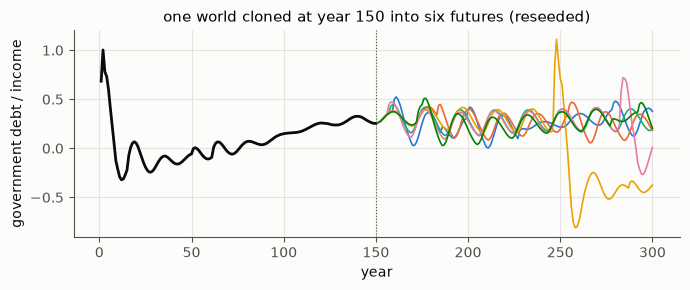

In [87]:
import copy
base14 = im1.Im1(seed=10003, **dict(r17.DIS, dis_rate=0.02))
for _ in range(150):
    base14.step()
fig, ax = plt.subplots(figsize=(7, 3))
pre = [r['b'] for r in base14.log]
ax.plot(range(1, 151), pre, color=INK, lw=2)
for k in range(6):
    w = copy.deepcopy(base14)
    im_time.reseed(w, np.random.default_rng(k))
    fut = [w.step()['b'] for _ in range(150)]
    ax.plot(range(151, 301), fut, color=PAL[k], lw=1.2)
ax.axvline(150, color=INK2, ls=':', lw=0.8)
ax.set(xlabel='year', ylabel='government debt / income', title='one world cloned at year 150 into six futures (reseeded)')
plt.tight_layout(); plt.show()

複製した世界は、乱数を替えなければ元の世界と同じ数をたどり、替えれば別の未来をたどる(どちらの世界も帳簿は閉じる。test_im.py の段 17b)。この複製を、閾値ごとに繰り返すのが多段の分割である。

In [88]:
record('stage17b')

S17b 平行世界(多段の分割): 100〜300 年のうちに国債/所得が水準を超える確率。危機に近づいた世界(途中の閾値を超えた世界)を複製し、乱数を替えて未来を分ける
   素朴な推定(1 本ずつ最後まで)と、同じくらいの計算(回した年数の和)の平行世界の推定を、5 回くり返して揺れを比べる
  災害 2.0%/年、国債/所得 > 0.8: 平行世界 0.2375 ± 0.0780(5 回の標準偏差、一回 25571 年ぶん、段ごとの割合の例 [0.49, 0.72, 0.9, 0.78]) | 素朴 0.2142 ± 0.0144(一回 127 本 ≈ 同じ年数) | 時間 53 秒 / 51 秒
  災害 2.0%/年、国債/所得 > 1.0: 平行世界 0.1339 ± 0.0442(5 回の標準偏差、一回 30153 年ぶん、段ごとの割合の例 [0.49, 0.72, 0.9, 0.78, 0.75, 0.85]) | 素朴 0.1520 ± 0.0190(一回 150 本 ≈ 同じ年数) | 時間 74 秒 / 62 秒
  災害 2.0%/年、国債/所得 > 1.2: 平行世界 0.1058 ± 0.0472(5 回の標準偏差、一回 31783 年ぶん、段ごとの割合の例 [0.49, 0.72, 0.9, 0.78, 0.75, 0.85, 0.84, 1.0]) | 素朴 0.1203 ± 0.0219(一回 158 本 ≈ 同じ年数) | 時間 88 秒 / 64 秒
  災害 0.5%/年、国債/所得 > 0.8: 平行世界 0.0720 ± 0.0224(5 回の標準偏差、一回 33435 年ぶん、段ごとの割合の例 [0.54, 0.52, 0.46, 0.66, 0.86, 0.95, 1.0, 0.9]) | 素朴 0.0719 ± 0.0038(一回 167 本 ≈ 同じ年数) | 時間 85 秒 / 69 秒


初め、複製した時点ですでに次の閾値を超えている世界(一年で二段を飛び越える世界)を「届いていない」と数えていて、推定が下に偏った。直したあとの推定は、**偏りなく、素朴な推定(一本ずつ最後まで数える)に合う**。ただし、揺れは素朴な推定より大きかった。

### 14.4 拡張の試み(段 17c)と、その結論

揺れを減らすために、三つの工夫を試した。もっと稀な出来事(確率 0.02〜0.07)で比べる、途中の閾値を「国債/所得 + 5 年ぶんの赤字/所得」(近い未来を見越す速い量)で測る、閾値を前もって決めずに、世界の届いた最高の水準の上位 3 割の境目を次の閾値にする(適応型。届いた世界の、閾値を初めて超えた時点の状態は、同じ種で走らせ直して取り出す)。計算が重いので(一つの出来事に 7〜8 分、並列 8)、このノートでは回さず、記録だけを示す(JRF の判断)。

In [89]:
record('stage17c')

S17c 平行世界の拡張: 国債/所得が水準を超える確率(100〜300 年)。5 回くり返しの平均 ± 標準偏差。効率の比 = 素朴な推定の (相対の分散 × 計算の量) ÷ その方法の値
  災害 2.0%/年、国債/所得 > 1.6(目安 0.0726): 素朴 0.0870 ± 0.0184(一回 51399 年)
      固定の閾値(国債/所得) 0.0686 ± 0.0326(一回 35173 年) | 効率の比 0.47
      固定の閾値(速い量を足した物差し) 0.0557 ± 0.0246(一回 31085 年) | 効率の比 0.93
      適応型(上位 3 割) 0.0792 ± 0.0363(一回 40538 年) | 効率の比 0.33
      (時間 488 秒)
  災害 0.5%/年、国債/所得 > 1.2(目安 0.0464): 素朴 0.0298 ± 0.0086(一回 55721 年)
      固定の閾値(国債/所得) 0.0479 ± 0.0278(一回 34254 年) | 効率の比 0.16
      固定の閾値(速い量を足した物差し) 0.0629 ± 0.0339(一回 32912 年) | 効率の比 0.11
      適応型(上位 3 割) 0.0448 ± 0.0137(一回 46119 年) | 効率の比 0.48
      (時間 445 秒)
  災害 0.2%/年、国債/所得 > 0.8(目安 0.0238): 素朴 0.0226 ± 0.0063(一回 55330 年)
      固定の閾値(国債/所得) 0.0268 ± 0.0119(一回 32919 年) | 効率の比 0.47
      固定の閾値(速い量を足した物差し) 0.0190 ± 0.0169(一回 29891 年) | 効率の比 0.26
      適応型(上位 3 割) 0.0270 ± 0.0174(一回 48884 年) | 効率の比 0.15
      (時間 382 秒)


**どの工夫でも、平行世界は素朴な推定に勝てなかった**(効率の比 0.11〜0.93。1 を超えれば平行世界が得)。理由は、この経済の稀な財政の危機が、**外から来る災害の重なりで引き起こされる**ことにある。閾値を超えた世界を複製しても、次の災害が来るかどうかは、複製のあとの運しだいで、複製は「災害を呼ぶ」ことができない。分割が効くのは、出来事に向かう道が、速い量の小さな揺れの積み重ねでできているときである。ここでは、道を決めるのは稀な災害の到来で、それを傾けるのは重点標本化のほうだが、それは重みが潰れる。次の手(災害の数そのものを物差しに入れる、重点標本化を災害の前後の短い窓だけに使い分割と組み合わせる)は、記録に残した。

それでも、平行世界は、偏りのない推定の道具としては使え、**箱庭の遊びの道具**として生きる。危機の手前で世界を分けて、別の選び方(政策、投票、事業)をした未来を並べて見せることができる(第 16 章)。

### 14.5 この章のまとめ

- 時間は三つの層に分け、帳簿の時計は年の層の一つにそろえる。
- 粗い時間の進め方は、遅い量だけを飛ばせば、長い実験を数分の一にできる。
- 歴史の重点標本化は重みが潰れ、平行世界(分割)は偏りなく推定できるが、この経済の稀な危機では素朴な数え上げに勝てない。危機を引き起こすのが外から来る災害だからである。

---

## 第 15 章 格上げ ── 経済の中で新しい経済が育つ

ノート O では、作者の 2011 年の外作用モデルを読み、「経済の中で経済が育つ」(埋め込み)の遷移を見た。小さな部分経済(仲間内の通貨や新しい財の工房)が、古い経済の中で育ち、条件がそろうと古い経済に取って代わる。技術経済パラダイムの転換(Perez 2002)の、入れ子の経済の形である。PLAN の 13 番目の要素「格上げ」は、これを im の中で起こせないか、という問いだった。

JRF の決定は、im の枠組み(帳簿とパラメータの登録簿)を使った**別枠の模型**で示し、うまくいきそうなら im に統合する、だった。さらに、「革命のような体制の入れ替わりが入れば、ゲーム性が上がる」とも言った。

### 15.1 別枠の模型の作り(upgrade.py)

- **財は二つ**: 古い財 O(消費と資本)と、新しい財 X(消費だけ)。X の一製品あたり労働は、作った量の累計とともに下がる(**ライトの法則**、指数 0.3、下限あり)。消費は二つの財の CES(代わりの利きやすさ 3)。
- **家計は三つの群れ**: 労働者、古い資本家(古い企業の持分)、新しい投資家(新しい企業の持分を買い、銀行から借りて買える)。
- **新しい企業は、トービンの q が 1 を超える分だけ投資し**(年 50% まで)、持分を売って賄う。
- **持分の値段**: 需要で決める(新しい投資家の望む保有。値上がりを外挿する)か、基本の値打ち(均した配当 ÷ r̄)。
- **借りすぎの棒引き**: 新しい投資家の借金が上限を超えた分は棒引きにし、銀行の損は古い資本家が負う。
- **体制**: 古い資本家の富の割合が半分を超えるほど、新しい財に税をかける(古い体制の抵抗)。**革命**: 新しい財で働く人と失業者の割合が閾値を超えると、税がなくなる(古い持分を労働者に移す道も選べる)。
- 帳簿は im_core で毎年閉じる(七つの部門、預金・貸出・二つの持分、二つの能力)。

その場で回す(決定論。300 年)。

  場合                                  | 新しい財の割合が 10% / 30% / 50% に届く年 | 300 年目の割合 | 棒引き(300 年の和) | 実質賃金(300 年目/初め) | 革命の年 | 帳簿のずれの最大
  基本の値打ち(泡なし)                          | 3 / 107 / 153 | 0.70 | 78270 | 2.14 | — | 4.0e-10
  需要で値段(泡あり)                           | 3 / 123 / 197 | 0.66 | 29 | 2.09 | — | 3.8e-10
  需要で値段 + 古い体制の抵抗(税の上限 2)              | 3 / 133 / 207 | 0.66 | 50 | 2.05 | — | 2.1e-10
  需要で値段 + 抵抗 + 革命(閾値 0.5)              | 3 / 133 / 207 | 0.66 | 50 | 2.05 | 185 | 1.6e-10


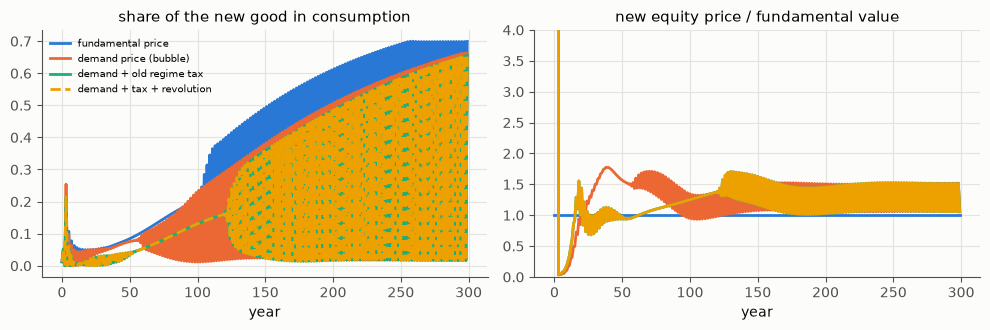

In [90]:
import upgrade
cases15 = [('基本の値打ち(泡なし)', dict(pricing='fundamental')), ('需要で値段(泡あり)', dict()),
           ('需要で値段 + 古い体制の抵抗(税の上限 2)', dict(politics='protect', tauX_max=2.0)),
           ('需要で値段 + 抵抗 + 革命(閾値 0.5)', dict(politics='revolution', tauX_max=2.0))]
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
print('  場合                                  | 新しい財の割合が 10% / 30% / 50% に届く年 | 300 年目の割合 | 棒引き(300 年の和) | 実質賃金(300 年目/初め) | 革命の年 | 帳簿のずれの最大')
for i, (lab, kw) in enumerate(cases15):
    a, m = upgrade.simulate(T=300, **kw)
    take = lambda th: int(np.argmax(a['sX'] >= th)) if (a['sX'] >= th).any() else None
    print(f"  {lab:36s} | {take(0.1)} / {take(0.3)} / {take(0.5)} | {a['sX'][-1]:.2f} | {a['wo'].sum():.0f} | {a['real_w'][-1] / a['real_w'][0]:.2f} | "
          f"{m.revolution if m.revolution is not None else '—'} | {a['books'].max():.1e}")
    en = ['fundamental price', 'demand price (bubble)', 'demand + old regime tax', 'demand + tax + revolution'][i]
    axs[0].plot(a['sX'], color=PAL[i], label=en, ls='-' if i < 3 else '--')
    axs[1].plot(a['pX'] / a['fund'], color=PAL[i])
axs[0].set(xlabel='year', title='share of the new good in consumption'); axs[1].set(xlabel='year', title='new equity price / fundamental value', ylim=(0, 4))
axs[0].legend(fontsize=7); plt.tight_layout(); plt.show()

- **新しい財は、長い据え付けの期のあと、一気に広がる**(S 字)。割合が 10% に届くのは 3 年目だが、50% までは 150〜200 年かかる。
- **泡(需要で値段)は、据え付けを速めなかった**(当初の目論見「泡は、新しい産業の据え付けを速める」は外れた)。基本の値打ちで値をつけたほうが、新しい財は早く広がる。泡があると q は高いが、投資は「売れる持分」(新しい投資家の財産)で縛られる。
- **据え付けを速めたのは、泡ではなく、借りて投資し、その損が棒引きにされる道だった**。基本の値打ちの場合、新しい投資家は持分を借金で買い続け、借りすぎの分が棒引きにされる(その損は、古い資本家が銀行を通じて負う)。Perez の筋書きの「据え付けの期の金融は、崩壊でその損を社会に回す」は、泡の値段よりも、**損の行き先**として現れた。
- **古い体制の抵抗は、移り変わりを少し遅らせるだけ**である。古い資本家の富の割合が下がると、税も自然に下がる(抵抗は、自分の衰えとともに消える)。

記録(ほかの設定を含む)も示す。

In [91]:
record('stage18')

U18-1 新しい企業の持分の値段の決め方(泡があるか)と、新しい産業の育ち方
  場合                              | 新しい財の割合が 10% / 30% / 50% に届く年 | 300 年目の割合 | 100 年目の新しい能力 | 初め 150 年の q | 値段/基本(平均、頂) | 失業(平均、頂) | 棒引き | 実質賃金(300年/初め) | 新しい財への税の平均 | 革命の年
  基本の値打ち(泡なし)                      | 3 / 107 / 153 | 0.70 | 2508 | 2.27 | 1.00, 1.0 | 0.084, 0.33 | 78270 | 2.14 | 0.000 | —
  需要で値段、外挿なし(ν=0)                  | 3 / 115 / 191 | 0.66 | 822 | 6.27 | 1.28, 3.1 | 0.075, 0.37 | 0 | 2.09 | 0.000 | —
  需要で値段、外挿 0.5                     | 3 / 123 / 197 | 0.66 | 659 | 13.38 | 1.26, 1.8 | 0.076, 0.39 | 29 | 2.09 | 0.000 | —
  需要で値段、外挿 1.0                     | 3 / 117 / 193 | 0.66 | 1144 | 13.97 | 1.20, 3.2 | 0.075, 0.38 | 5 | 2.09 | 0.000 | —
  需要で値段、借りて買えない(lev=0)             | 3 / 77 / 107 | 0.71 | 6876 | 12.25 | 2.11, 4.1 | 0.058, 0.39 | 108953844 | 2.16 | 0.000 | —
  需要で値段、置きたい割合の反応 10               | 3 / 125 / 199 | 0.66 | 671 | 13.40 | 1.29, 1.8 | 0.074, 0.39 | 29 | 2.08 | 0.000 | —
  (帳簿の最大のずれは、すべての場合で 1e-6 × 消費 より小さい: 各年の L.ch

### 15.2 革命と、ゲーム性

**革命は、閾値の置き方で「すぐ起きる」か「移り変わりのあとに起きる」かのどちらかになり、移り変わりの速さを変えない**。閾値 0.3 では、初めの失業がすでに高いので 3 年目に起きる。0.5 では、新しい財がすでに広がりかけた 185 年目に起きる。古い持分を労働者へ移しても、移り変わりの速さは変わらない(分配だけが変わる)。

JRF の示唆したゲーム性のためには、**革命の条件を、失業の水準ではなく、移り変わりの途中の痛み**(古い産業の失業の急な増え、実質賃金の下がり)に結ぶ必要がある。そうすれば、革命は、移り変わりのちょうど苦しい時期に起きうる出来事になる。

### 15.3 格上げならず

**im への統合は見送った**。結果が「泡より損の行き先」で、据え付けの金融は、im の株式の市場(第 4 章)と貸倒れで書き直すほうが筋がよく、財の数を一般にする書き直し(価格の残差・需要・帳簿・貿易のすべて)に見合う見通しがまだないからである。

振り返ると、この別枠の模型そのものが、im の外に作った小さなバーチャルな世界で、それが im の本体に格上げされなかった、ということになる(JRF の言葉では「格上げならず」)。ただ、遊びの中では、格上げが「いつも起きるわけではなく、条件がそろったときだけ起きる出来事」であることは、欠点ではなく面白さの元になる。第 16 章で、その案を書く。

### 15.4 この章のまとめ

- 新しい産業は、長い据え付けのあと一気に広がる。据え付けを速めるのは、泡の値段ではなく、借りた投資の損を誰が負うか、である。
- 古い体制の抵抗は、自分の衰えとともに消える。革命は、条件を移り変わりの痛みに結ばないと、ゲーム性を生まない。
- 格上げの模型は、別枠のまま残し、ブラウザの版の「体制の交代」の素材にする。

---

## 第 16 章 箱庭の中の一人

im を作り終えたあとで、JRF は新しい方向を出した(2026-10-28)。

> 第 3 の UI(または箱庭の一部)として、個人として行動できるようにするのもおもしろいと思っています。ワールドネバーランドのように。そうするとダウンズの投票理論のようなことが、個人が周りに影響を与えることとして活かせる気もします。

ブラウザの版(ノート 4 のあとで作った。16.5 節)には、もともと二つの顔があった。勝ち負けのない**箱庭**と、**分析の画面**である。そこに三つめの顔として、**箱庭の中の一人として暮らす**遊びを足す。段 19 は、その下ごしらえである。

### 16.1 プレイヤーの記入

- 標本の記入の一つから、人数 0.01 の記入(一人の世帯。im の人数の単位は全体で約 1000)を切り出し、標本の最後に足す。財産と働く力は人数に比例して分け、総量は変わらない(Lean で確かめる)。
- 選び方(`e.act` に入れる。入れなければ規則どおり): 支出の倍率、働く度合い、子を持つか、投票('hi' か 'lo')、呼びかけ(0〜1)。
- **代替わり**: プレイヤーの世帯が入れ替わるとき、次の代が財産を継いで遊びを続ける(ワールドネバーランドの代替わり)。ほかの世帯と同じく、くじで他の世帯へ渡す設定も選べる。
- 人数の少ない記入ほど運を大きくする規則(第 12 章)は、プレイヤーには当てない(当てると運が 7 倍になり、富が平均の数万倍に飛んだ)。

In [92]:
print(inspect.getsource(im1.Im1.carve_player))

    def carve_player(self):
        """記入 player_src から、人数 player_heads の記入を切り出し、標本の最後に足す。足せる量は人数に比例して分け、
        割合の量は写す。総量は変わらない。"""
        P, H = self.p, self.H
        i = int(P.player_src)
        f = min(P.player_heads / H.heads[i], 0.5)
        for name in self.EXT:
            arr = getattr(H, name)
            new = arr[i] * f
            arr[i] = arr[i] * (1 - f)
            setattr(H, name, np.append(arr, new))
        for name in self.INT:
            arr = getattr(H, name)
            setattr(H, name, np.append(arr, arr[i]))
        self.pl = len(H.M) - 1
        self.pl_gen, self.pl_pivots = 1, 0



In [93]:
%%writefile -a integrated_model.lean
/-! ## 第 16 章 群れの相関と投票率

群れの投票率 t(ρ) = 1 − exp(−A √(ρ/π) / c)(ノート M 第 4 章)。賭け金 A ≥ 0、費用 c > 0 なら、
群れの中の相関 ρ が高まるほど、投票率は上がる(呼びかけが群れを動かす道)。 -/
theorem turnout_monotone {A c ρ₁ ρ₂ : ℝ} (hA : 0 ≤ A) (hc : 0 < c) (h : ρ₁ ≤ ρ₂) :
    1 - Real.exp (-(A * Real.sqrt (ρ₁ / Real.pi) / c)) ≤ 1 - Real.exp (-(A * Real.sqrt (ρ₂ / Real.pi) / c)) := by
  have hs : Real.sqrt (ρ₁ / Real.pi) ≤ Real.sqrt (ρ₂ / Real.pi) :=
    Real.sqrt_le_sqrt (div_le_div_of_nonneg_right h Real.pi_pos.le)
  have : A * Real.sqrt (ρ₁ / Real.pi) / c ≤ A * Real.sqrt (ρ₂ / Real.pi) / c :=
    div_le_div_of_nonneg_right (mul_le_mul_of_nonneg_left hs hA) hc.le
  have := Real.exp_le_exp.mpr (neg_le_neg this)
  linarith

/-- プレイヤーの切り出し: 記入 i の量 x_i を、割合 f で二つに分けても、総量は変わらない。 -/
theorem carve_keeps_total {ι : Type*} [DecidableEq ι] (s : Finset ι) (x : ι → ℝ) (i : ι) (hi : i ∈ s) (f : ℝ) :
    (∑ j ∈ s, Function.update x i (x i * (1 - f)) j) + x i * f = ∑ j ∈ s, x j := by
  rw [Finset.sum_update_of_mem hi, ← Finset.add_sum_erase s x hi, Finset.sdiff_singleton_eq_erase]
  ring

Appending to integrated_model.lean


### 16.2 一つの暮らしを遊ぶ

台本を書いて、プレイヤーとして 300 年(十代ほど)を暮らしてみる。若いうちは倹約し、30 年目ごとに子を持ち、10 年ごとの投票では高い税に入れて呼びかける。引退は 45 年、年金は賦課方式、子を育てる費用は 0.5。

代の数 8、決め手になった投票 1 回 / 投票 28 回、高い税の年の割合 0.03、生存の量に届かない年 0.78


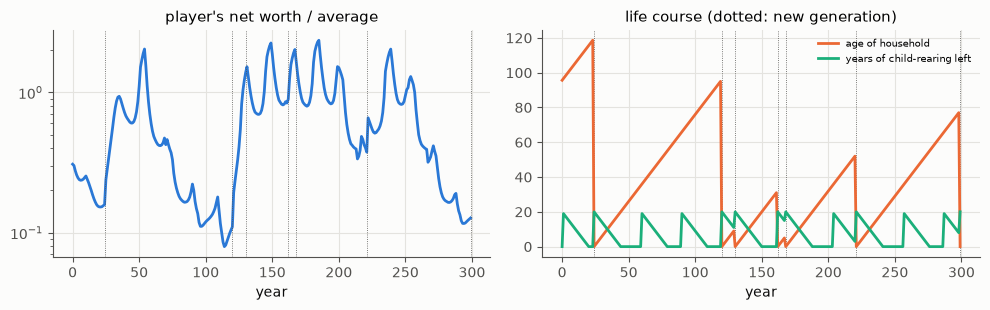

In [94]:
L16 = dict(BASE, crisis_track=True, player=True, ret_age=45, pension='payg', child_cost=0.5, vote=True, vote_noise=True,
           rho_w=3e-4, rho_k=1e-2, k_sway=1e-4)
e16 = im1.Im1(seed=3, **L16)
log16 = []
for t in range(300):
    st = e16.player_state()
    age = st['pl_age']
    e16.act = dict(spend=0.7 if age < 30 else 1.1, child=(int(age) % 30 == 5), vote='hi', campaign=1.0)
    r = e16.step()
    log16.append(r)
g = lambda k: np.array([r.get(k, np.nan) for r in log16], float)
gen = g('pl_gen')
print(f"代の数 {int(gen[-1])}、決め手になった投票 {int(log16[-1]['pl_pivots'])} 回 / 投票 {sum(1 for r in log16 if 'pl_pivot' in r)} 回、"
      f"高い税の年の割合 {np.mean(g('tau_k') == e16.p.tau_hi):.2f}、生存の量に届かない年 {np.mean(g('pl_hungry')):.2f}")
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].plot(g('pl_nw_rel'), color=PAL[0]); axs[0].set(xlabel='year', title="player's net worth / average", yscale='log')
for t in np.nonzero(np.diff(gen) > 0)[0]:
    for ax in axs:
        ax.axvline(t + 1, color=INK2, lw=0.6, ls=':')
axs[1].plot(g('pl_age'), color=PAL[1], label='age of household'); axs[1].plot(g('pl_kids'), color=PAL[2], label='years of child-rearing left')
axs[1].set(xlabel='year', title='life course (dotted: new generation)'); axs[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

プレイヤーの財産は、倹約の若い時代に積み上がり、子を育てる年と引退の年に削られ、代替わりのたびに次の代に渡る。ただし、この台本のプレイヤーは、多くの年に生存の量に届かなかった。倹約(支出 0.7 倍)は必需品の支出も削るので、財産を作る代わりに、食べていない。im の家計の予算は、必需品と贅沢品を一緒に決めるので、遊びの版では「何を削るか」も選べるようにしたほうがよい。経済の側(雇用や物価)は、プレイヤーの選び方では変わらない(一人の重みは 10 万分の 1)。ノートの外の記録(種 8 個)では、選び方が本人の暮らしを大きく変える。

In [95]:
record('stage19', 'P2')

P2 一つの暮らし(引退 45 年、賦課方式の年金、養育の費用 0.5): プレイヤーの選び方と、代替わりで財産を継ぐか
  場合                                   | 300 年目の正味資産(平均との比) | 100 年目からの平均 | 生存の量に届かない年の割合 | 代の数 | 資産家だった年の割合 | 雇用
  規則どおり(支出 1、働く)                       | 1.07±0.46 | 1.32±0.43 | 0.460±0.074 | 10.0±1.4 | 0.12±0.07 | 401±1
  倹約(支出 0.7)                           | 1.56±0.54 | 2.09±0.56 | 0.439±0.073 | 10.0±1.4 | 0.15±0.08 | 401±1
  浪費(支出 1.3)                           | 0.57±0.45 | 0.66±0.41 | 0.406±0.068 | 10.0±1.4 | 0.10±0.07 | 401±1
  半分だけ働く                               | 0.94±0.45 | 1.19±0.45 | 0.837±0.103 | 10.0±1.4 | 0.17±0.11 | 401±1
  倹約、代替わりで財産を手放す(くじ)                   | 0.58±0.08 | 6.07±5.10 | 0.732±0.034 | 1.0±0.0 | 0.03±0.03 | 400±1
  倹約、運あり(σ 0.2)                        | 0.87±0.13 | 1.90±0.52 | 0.548±0.067 | 10.0±1.4 | 0.09±0.05 | 392±1
  (帳簿と標本の差/所得の最大 2e-14)


### 16.3 一票は無意味か: ダウンズと、群れの相関

ダウンズの投票の逆理: 一人の票が結果を変える確率はごく小さいので、投票の費用を払うのは合理的でない。ノート M 第 4 章は、これへの反論として、**相関のある群れ**を置いた。人は独立に選ぶのではなく、似た人どうしで選び方が相関する。群れの中の相関 ρ があると、一人の票は √(ρ/π) の重みで結果に効く(第 9 章の投票の式)。

プレイヤーには、二つの効き方を持たせた。

- **一票**: 人数 0.01 ぶんの票。
- **呼びかけ**: 自分の投じる案を好む群れの相関 ρ に、k × 呼びかけ を足す(一人が見本になって、群れの選び方がそろう)。投票率は ρ とともに上がる(上の Lean の定理 `turnout_monotone`)。

群れの票には、相関による揺れ(標準偏差 = 人数 × √(ρ t (1 − t)))を入れた。初め、揺れなしで試したら、一票(0.01 人)が投票の 15〜20% で決め手になった。調べると、資産所得が負の年に、どちらの群れも賭け金がなく、0 票対 0 票で決まっていたためだった。誰も投票しない年は、選挙が成り立たず、今の政策を保つことにした。

その場で回す(資産家の相関 ρ_k = 1e-2。第 9 章の相転移は ρ_w ≈ 3e-4〜5e-4 にある。種 8 個、標本 2000 記入、300 年)。**決め手**は、プレイヤーがいなければ結果が逆だった投票である。

In [96]:
import results_stage19 as r19
cases16 = []
for rw in (1e-4, 3e-4, 1e-3):
    V = dict(vote=True, rho_w=rw, rho_k=1e-2, vote_noise=True)
    cases16 += [(f'ρ_w = {rw:g}、プレイヤーなし', V, {}), (f'ρ_w = {rw:g}、一票だけ', dict(V, player=True), dict(vote='hi')),
                (f'ρ_w = {rw:g}、一票 + 呼びかけ', dict(V, player=True, k_sway=1e-4), dict(vote='hi', campaign=1.0))]
out16 = nt.pmap(r19.run, [(kw, act, s) for _, kw, act in cases16 for s in range(8)])
print('  場合                        | 高い税の年の割合 | プレイヤーが決め手になった投票の割合')
for i, (lab, _, _) in enumerate(cases16):
    rs = [r for r in out16[i * 8:(i + 1) * 8] if r is not None]
    hi, pv = np.mean([r['hi'] for r in rs]), np.nanmean([r['pivot'] for r in rs]) if 'プレイヤーなし' not in lab else np.nan
    print(f"  {lab:26s} | {hi:.2f} | {'—' if np.isnan(pv) else f'{pv:.3f}'}")

  場合                        | 高い税の年の割合 | プレイヤーが決め手になった投票の割合
  ρ_w = 0.0001、プレイヤーなし       | 0.00 | —
  ρ_w = 0.0001、一票だけ          | 0.08 | 0.000
  ρ_w = 0.0001、一票 + 呼びかけ     | 0.23 | 0.096
  ρ_w = 0.0003、プレイヤーなし       | 0.64 | —
  ρ_w = 0.0003、一票だけ          | 0.64 | 0.005
  ρ_w = 0.0003、一票 + 呼びかけ     | 0.86 | 0.169
  ρ_w = 0.001、プレイヤーなし        | 0.99 | —
  ρ_w = 0.001、一票だけ           | 1.00 | 0.000
  ρ_w = 0.001、一票 + 呼びかけ      | 1.00 | 0.006


- **一票は、ほとんど決め手にならない**(ダウンズのとおり)。
- **呼びかけ(群れの相関を動かす)は、相転移の近くでだけ決め手になる**。相転移の手前(ρ_w = 1e-4〜3e-4)では、投票の 1〜2 割で、プレイヤーの呼びかけが政策を替える。相転移を越えた先(ρ_w = 1e-3)では、群れはすでにまとまっていて、呼びかけは効かない。

**「一票は無意味か」の答えは、状況による**。群れがまとまれば勝てるが、まだまとまっていない、相転移の手前でだけ、一人の動きが政策を替える。ノート M 第 4 章の「一票の効き目は √(ρ/π)、相関が政治の力」を、遊びの中で体験できる形になった。ただし、一人の影響を盛りすぎないこと(ダウンズへの反論が「主人公の補正」にならないよう、呼びかけの効き目 k は小さく置き、その大きさで結果がどう変わるかを、記録で示した)。

In [97]:
record('stage19', 'P1')

P1 ダウンズの投票(段 5 の V1 の相転移、資産家 ρ_k = 1e-2): プレイヤーの一票と、呼びかけ(自分の群れの相関 ρ に k × 呼びかけ を足す見本の効き目)。決め手 = プレイヤーがいなければ結果が逆だった投票。票の揺れあり(vote_noise)
  場合                                   | 高い税の年の割合 | プレイヤーが決め手になった投票の割合 | 雇用
  ρ_w = 0.0001、プレイヤーなし                 | 0.00±0.00 | nan±nan | 529±0
  ρ_w = 0.0001、一票だけ(高い税)               | 0.08±0.02 | 0.000±0.000 | 521±3
  ρ_w = 0.0001、一票 + 呼びかけ(k 1e-4)       | 0.23±0.04 | 0.096±0.025 | 515±4
  ρ_w = 0.0001、一票 + 呼びかけ(k 1e-3)       | 1.00±0.00 | 0.909±0.028 | 407±0
  ρ_w = 0.0003、プレイヤーなし                 | 0.64±0.06 | nan±nan | 482±9
  ρ_w = 0.0003、一票だけ(高い税)               | 0.64±0.06 | 0.005±0.004 | 476±9
  ρ_w = 0.0003、一票 + 呼びかけ(k 1e-4)       | 0.86±0.05 | 0.169±0.022 | 442±10
  ρ_w = 0.0003、一票 + 呼びかけ(k 1e-3)       | 1.00±0.00 | 0.369±0.056 | 407±0
  ρ_w = 0.0005、プレイヤーなし                 | 0.94±0.01 | nan±nan | 419±3
  ρ_w = 0.0005、一票だけ(高い税)               | 0.95±0.01 | 0.000±0.000 | 422±5
  ρ_w = 0.0005、一票 + 呼びかけ(k 1e-4)       | 0.97±0.01 | 0.037±0.012 | 41

### 16.4 遊びの版の案

ブラウザの版の第三の顔について、JRF と話した案を書いておく。このうち、一人の暮らし、格上げ、革命、平行世界は、16.5 節のブラウザの版に入れた。

- **一人の影響は、群れの相関を通じて現れる**。プレイヤーが、自分と同じ規則で動く群れの「見本」になり、群れの相関を少し動かす。相転移までの距離(群れの ρ と境目)を画面に見せる。
- **格上げを、遊びの中の出来事にする**。プレイヤーが始める小さな事業・仲間内の通貨(ノート P のポイント、ノート O の外作用の経済)・新しい財の工房が、箱庭の中の部分経済として育つ(第 15 章の模型)。条件(危機で古い経済が崩れる、仲間の群れの相関が臨界を越える、古い体制の抵抗が衰える)がそろうと、箱庭の本体に格上げされる。格上げは「勝ち」ではなく、何度も試せる出来事にする。
- **革命の条件は、移り変わりの痛みに結ぶ**(第 15 章)。プレイヤーは、その群れに加わるか、離れるかを選べる。
- **平行世界を、遊びの道具にする**(第 14 章)。危機の手前で世界を複製し、別の選び方をした未来を並べて見せる。分析の画面と箱庭をつなぎ、「やり直し」を物語の中に正しく入れる。
- **勝ち負けを作らない**。箱庭の方針(勝ち負けのない世界)は守り、格上げも革命も、達成ではなく出来事として扱う。

### 16.5 ブラウザの版: The JRF Economy Model 2026

このノートのあとで、im をブラウザで動かす版を作った(2026-10-29)。ページは https://jrf-2018.github.io/jrf_economy_models_2026/im_sandbox.html 、源はリポジトリの `site/` にある。三つの顔がある。

- **箱庭**: 三つの島(三つの国)。政策のつまみ、出来事のボタン(大災害、局地の災害、能力の半減、利上げ、熱狂、新しい工房)、指標のカード、新聞の見出し、効果音。島の上のもの(家の高さが正味資産、畑と倉、工場、銀行、政府の塔、堤など)にマウスを載せると、説明とその年の数が出る。
- **分析の画面**: 二つの試しの比べ、平行世界の扇(第 14 章の平行世界を小さくしたもの。今の年の状態を複製し、運だけを引き直した 12〜48 本の未来)、小さな政策の地図(17.3 節)。
- **一人の暮らし**: 16.1 節のプレイヤーの記入。暮らしの支出、何を削るか、働く度合い、子を持つか、選挙で投じる案と呼びかけの強さを選ぶ。代替わりと家系図。「やり直しなし」の遊び方も選べる。

全体を貫くのは、JRF の案の**時間のつまみ**である。戻る、戻って命令を出すと枝が分かれて新しい試しになる、サイコロでその年から先の運を引き直す、取り消す、セーブとロード、URL で人に渡す。鍵の年の状態を覚えておき、そこから計算し直すので、戻ってからの計算は通しの計算とずれない。

遊びの出来事として、16.4 の案のうち二つを入れた。**革命**は、移り変わりの痛み(雇用の落ち込み、実質賃金の下がり、生存の量に届かない人の増え、一家離散)が積もった不満が閾値を超えると、資本所得の税・再分配・富裕税の組が、もう一つの体制の組と入れ替わる。**格上げの工房**は、第 15 章の模型を小さくしたもので、新しい財の工房がライトの法則で費用を下げ、古い贅沢品より安ければ広がり、半分を超えると格上げになる(補助なしでは、たいてい消える)。どちらも、勝ち負けではなく出来事として扱う。

既定の世界は、三国が共通の通貨で、B 国は生産性が少し低く、C 国は贅沢品が得意で安全網が薄い。A 国にプレイヤーの世帯と選挙を置き、子を育てる費用を入れた。始めの 60 年を黙って回し(地価と国債の移り変わり)、そのあとを 0 年とする。テイラー・ルールの強さは、つまみの上限を 1.2 にした(1.5 では、im の世界は 50 年ほどで価格が解けなくなる)。

**Python と JS の一致**。参照実装は Python の im で、JS(`site/js/model/`)はその写しである。同じ数が出るように、im に持ち運べる乱数(xoshiro128\*\*)と持ち運べる最小化(Levenberg–Marquardt)の道(`rng='portable'`、`solver='portable'`)を足した。既定の道(numpy と scipy)の数は、前と変わらない。`python/check_js_vs_py.py` は、JS を quickjs で動かし、Python と年ごとに比べる(一国の場面 18、三国の場面 8)。水準の量は各年の相対のずれで、差の量(物価上昇率、赤字、収支など)は系列の大きさに対するずれで測り、1e-9 以内で合う。

ただし、次のことに注意してほしい。

- 価格は数値の微分を使って解くので、関数の値の丸めのずれ(最後の 1 桁)が 1e8 倍ほどに増え、Python と JS の価格は 1e-11 ほどずれる。ふつうの道では、このずれは年を追って広がらない。
- **不安定な道では、丸めのずれが育つ**。変動の為替で一国に価格の上限を置くと、その国の通貨が下がり続ける(80 年で 1/20)。この道では、ずれは 60 年目まで 1e-9 以内だが、80 年目で 6e-8 になる。一致テストでは、この場面だけ許容を 1e-6 にした(Python と JS のずれをそこまで厳密に見る必要はない、という JRF の判断。場面の長さは縮めない)。
- **革命の場面では、預金のジニに意味がない年がある**。再分配が入れ替わるたびに預金の総額が 0 の近くを通り、預金のジニ(分母が預金の和)が 82 のような値になる。一致テストでは、この場面も許容を 1e-6 にした。ほかの量は 1e-9 で合う。
- ブラウザの種類によって、`Math.exp` などの最後の桁が違いうる。同じブラウザでのやり直しやロードは完全に同じ数になるが、URL で渡した試しは、別のブラウザでは長い年のあとに少しずれうる。

### 16.6 この章のまとめ

- 標本の中に一人のプレイヤーを切り出し、暮らしの選び方を外から与えられるようにした。総量と帳簿は変わらない。
- 一人の財布の選び方は、本人の暮らしを大きく変えるが、経済を変えない。
- 政治では、一票は効かないが、群れの相関を動かす呼びかけは、相転移の手前でだけ効く。

---

# 第 VII 部 まとめ

## 第 17 章 部品の表と地図

このノートの問い 5 は、「簡単な版と詳細な版は、どう関係するか。部品を一つずつ入れたとき、どの部品がどの結論を変えるか」だった。im は、段ごとに部品を一つずつ差し込み、**どの部品も既定では切ってあり、切れば前の段と同じ数が出る**ことを、関門で確かめながら育てた。だから、簡単な版(me_c、gj)は、詳細な版(im の全部入り)の特別な場合として、数の上でそのまま含まれている。

### 17.1 関門を、その場で確かめる

`test_im.py` は、段ごとの関門(帳簿が閉じる、部品を切れば前と同じ数、重みの付け方によらない)を一つにまとめたものである。全部を回す(2 分ほど)。

In [98]:
r = subprocess.run([sys.executable, '-W', 'ignore', 'test_im.py'], cwd=nt.IM, capture_output=True, text=True)
print(r.stdout)
print(r.stderr[-2000:])
same = [ln for ln in r.stdout.splitlines() if '前と同じ' in ln]
print(f'「前と同じ数」の関門 {len(same)} 行。終了コード {r.returncode}')

帳簿(でたらめな取引 1 万件): 1.4e-13
gj と同じ数(13 通り、最大のずれ): 1.1e-15
gj を 30 年: 帳簿 8.8e-16、預金の動き 8.4e-13、国債の残高と赤字の和の差 4.4e-16
労働者の貯蓄 0.1 で 30 年: 帳簿 8.9e-16、預金の動き 8.3e-13、国債 0.0e+00
投資の関数 bm で 30 年: 帳簿 1.7e-15、預金の動き 5.6e-14、国債 4.4e-16
時間の層(slow, every=5 が動いた年): [0, 5, 10]
段 1a: me_c v0.1 と同じ数(4 通り × 400 年、相対のずれの最大) 2.3e-09、帳簿と標本の差 5.2e-11
段 1b: 重みの付け方によらない(分けた標本との相対のずれ) 3.8e-11、帳簿と標本の差 2.4e-11
段 1c: 信用の部品を入れても、金利 0・借入 0 なら信用なしと同じ数(相対のずれ) 0.0e+00、帳簿と標本の差 2.0e-10
段 2: 帳簿・標本の差・土地の和のずれ 4.9e-10、重みの付け方によらない 7.9e-11、土地を切れば段 1 と同じ 0.0e+00
段 3: 貿易を切れば一国と同じ 6.3e-11、貿易ありの帳簿のずれ/所得 7.2e-15、標本の差 9.9e-10、同じ二つの地域の対称 3.6e-13
段 3b: 固定(e = 1)と共通の通貨の差 0.0e+00、変動(同じ二地域)と共通の差 4.1e-10、為替の 1 からのずれ 2.4e-11、通貨ごとの帳簿のずれ/所得 5.0e-15
段 3c: 同じ三地域で、すべて変動と共通の差 4.5e-10、A+B 同盟・C 変動と共通の差 4.4e-10、為替の 1 からのずれ 3.2e-11、帳簿のずれ/所得 8.4e-15
段 2b: 知財の市場ありの帳簿・標本の差 8.4e-10、知財の市場を切れば段 2 と同じ 0.0e+00
段 4: 災害の部品を入れても、起きなければ段 2 と同じ 0.0e+00、災害が起きても帳簿と標本の差 1.2e-09
段 4(重点標本化): 帳簿・標本の差・土地の和のずれ 2.0e-09、人数の和のずれ 2.3e-13(分割と併合 935 回)
段 4b: 行き詰まりの道を五つ入れても、帳簿と標本

### 17.2 部品の表

段ごとに、入れた部品(スイッチ)と、それが変えた結論をまとめる。

| 段 | 部品(スイッチ) | 章 | 変えた結論 |
|---|---|---|---|
| 0 | 帳簿の骨組み、労働者の貯蓄、投資の利潤への反応 | 2 | 労働者も貯めると、資本家の所得は再分配で減る。再分配の向きは投資の反応で逆になる |
| 1 | 信用(credit)、標本の家計(households)、貸し手の慎重さ(mu_prem) | 3 | 集中 → 金利 → 雇用の回り道が、落ち込みを増幅する。テイラー・ルールは両方向に不安定 |
| 2、2b | 土地と知財(land)、知財の市場(ip_market) | 4 | 土地が回り道を一段強める。相続の仕方が格差を決める。知財は買えば不利(隠れた補助) |
| 3、3b、3c | 地域(World)、通貨(currency) | 5 | 共通の通貨は打撃を分け、変動の為替はひとりで負わせる。縛りの出どころは資本の移動がないこと |
| 4、4b | 災害(disaster)、守り(protect)、救済(relief)、財政のルール(fiscal)、行き詰まりの道(resolve) | 6 | 共通の打撃には打撃の前の守り。財政のルールが履歴を作る。破綻は物価と金利で戦うことから |
| 5 | 学習(learn)、投票(vote)、研究(research)、株式の市場(eq_market) | 9、10、4 | 忘れる社会は変化に追いつく。投票の相転移。研究の得は労働者へ。株は買えば得 |
| 5(世界樹) | 企業の集まり(firms)、知財の保護(ip_lag)、公の研究所(s_pub) | 10 | 真似る者が世界樹を枯らす。保護は独占、公の研究所がよい |
| 6 | 資本の移動(capital)、財政同盟(union)、富裕税(wealth_tax) | 5 | 富裕税は外の資産が見えないと労働者に負担を移す。効くのは情報の交換 |
| 7 | 価格の上限(cap_N)、最後の生産者・損失の分担(crisis_rule)、在庫、備蓄、公共事業 | 7 | 「誰も作りたがらない」は費用の急騰と上限で起きる。最後の生産者が最もよい |
| 8、8b | 文化(psi_v)、文化から技術への波及(culture_spill、spill_cap) | 11 | 文化の得は効用に出る。波及の道で技術の進みは 2 倍、上限がないと発散 |
| 9 | 運(luck_sigma)、腕、養育の費用(child_cost) | 12 | 富の集中は運と相続から内に出る。富裕税は最上位を削らない。養育の費用は飢えに |
| 10、10b | 引退(ret_age)、年金(pension)、児童手当、BI、基金の株(fund_eq、phi_q) | 12 | 積立は倹約のパラドックスで崩れ、株を買っても解けない。児童手当が効く |
| 11 | 自動化(auto_share) | 10 | 労働の取り分が下がり、投資が不安定になる(ハロッド) |
| 12 | 注意(attention) | 9 | 慣性は打撃を和らげるが、貸倒れを増やし、泡は止めない |
| 13 | 信念の区間(learn_attitude='interval')、三つの勘定 | 9 | 区間は忘れない社会の過信の歯止め。危機は探索を削るが取り戻す |
| 14 | 作り手の流出(p_spin)、国庫(t_prize) | 10 | 国庫は知財の保護よりよく、公の研究所に並ぶ |
| 15、15b、15c | 貸し手(lender、lending)、探索の借入(res_loan)、ペテン(phi_sw)、損の記憶(k_mem) | 13 | 関係融資は探索を細らせる。ペテンは市場型にだけ効き、半ば実現する |
| 16 | 死蔵(hoard)、準備の縛り(reserves) | 8 | ρ_eff の折れ線は、死蔵と固定の準備から出る。量の縛りは弱く、金利が効く |
| 17、17b、17c | 時間の層(im_time)、平行世界 | 14 | 遅い量だけを飛ばせる。平行世界は偏りがないが、この経済の危機では速くならない |
| 18 | 格上げ(upgrade.py。別枠) | 15 | 据え付けを速めるのは損の行き先。革命は痛みに結ぶ |
| 19 | プレイヤー(player)、票の揺れ(vote_noise) | 16 | 一票は効かず、呼びかけは相転移の手前でだけ効く |

### 17.3 政策の地図: 行動の仮定で、向きが変わる

問い 3 の「政策のつまみの効き方は、行動の仮定でどう変わるか」を、一枚の地図にする。資本所得への税(τ_k、税収を一人あたり同じ額で配る)を 0.2 → 0.6 に上げたとき、雇用がどう変わるかを、投資の行動の仮定(稼働率への反応 φ_u と、利潤率への反応 φ_r)ごとに見る(貸し手の慎重さ μ = 0.5、θ = 0.15、既定の財政のルール。種 3 個)。

再分配(τ_k 0.2 → 0.6)による雇用の変化の割合(行: 稼働率への反応 φ_u、列: 利潤率への反応 φ_r)
         φ_r=0.2   φ_r=0.5   φ_r=1.0
  φ_u=0.1  +0.062  +0.056  +0.074
  φ_u=0.3  +0.065  +0.084  +0.204
  φ_u=0.6  +0.339  +0.253  +0.503


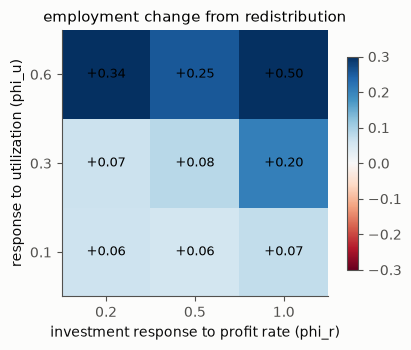

In [99]:
B17 = dict(households='continuous', Ns=1000, g_gamma=0.0, credit=True, mu_prem=0.5, theta_prem=0.15)
grid = [(pu, pr) for pu in (0.1, 0.3, 0.6) for pr in (0.2, 0.5, 1.0)]
cases17 = [(f'{pu}_{pr}_{tk}', dict(phi_u=pu, phi_r=pr, tau_k=tk)) for pu, pr in grid for tk in (0.2, 0.6)]
res17 = runs(cases17, seeds=range(3), T=400, keys=('E', 'top10_inc'), base=B17)
def mE(lab):
    ok = [r['E'][300:].mean() for r in res17[lab] if r is not None]
    return np.mean(ok) if ok else np.nan
M = np.array([[mE(f'{pu}_{pr}_0.6') / mE(f'{pu}_{pr}_0.2') - 1 for pr in (0.2, 0.5, 1.0)] for pu in (0.1, 0.3, 0.6)])
print('再分配(τ_k 0.2 → 0.6)による雇用の変化の割合(行: 稼働率への反応 φ_u、列: 利潤率への反応 φ_r)')
print('         φ_r=0.2   φ_r=0.5   φ_r=1.0')
for pu, row in zip((0.1, 0.3, 0.6), M):
    print(f'  φ_u={pu}  ' + '  '.join(f'{v:+.3f}' for v in row))
fig, ax = plt.subplots(figsize=(4.6, 3.6))
im_ = ax.imshow(M, cmap='RdBu', vmin=-0.3, vmax=0.3, origin='lower')
ax.set_xticks(range(3), ['0.2', '0.5', '1.0']); ax.set_yticks(range(3), ['0.1', '0.3', '0.6'])
ax.set(xlabel='investment response to profit rate (phi_r)', ylabel='response to utilization (phi_u)', title='employment change from redistribution')
for i in range(3):
    for j in range(3):
        ax.text(j, i, f'{M[i, j]:+.2f}', ha='center', va='center', fontsize=9)
plt.colorbar(im_, ax=ax, shrink=0.8); ax.grid(False); plt.tight_layout(); plt.show()

**既定の財政のルールのもとでは、再分配は、地図のどの場所でも雇用を上げた**。効き目の大きさは仮定で違い、投資が稼働率(需要)に強く反応する場所(需要主導)ほど大きい。構成案を書いたときの見込みは、「利潤主導の場所では向きが逆になる」だった(第 2 章の gj では、そうなった)。しかし、価格と信用のある im では、利潤率に強く反応する場所でも、逆にはならなかった。

では、第 3 章の記録の逆転(基準の経済で、再分配が雇用を下げた)は、どこから来たのか。財政のルールを替えて比べる。

In [100]:
cases17b = []
for fis, lab in (('burden', '利払いの重さ(既定)'), ('deficit', '赤字を 0 に(段 1〜4)')):
    for tk in (0.2, 0.6):
        cases17b.append((f'{lab}、τ_k = {tk}', dict(fiscal=fis, tau_k=tk)))
res17b = runs(cases17b, seeds=range(4), T=400, keys=('E', 'tau', 'infl'), base=B17)
table(res17b, [('雇用', 'E', 'mean', '.0f'), ('賃金への税率', 'tau', 'mean', '.2f'), ('物価上昇率', 'infl', 'mean', '+.3f')], burn=300, width=32)

  場合                               | 雇用 | 賃金への税率 | 物価上昇率
  利払いの重さ(既定)、τ_k = 0.2             | 627±6 | 0.16±0.01 | +0.021±+0.004
  利払いの重さ(既定)、τ_k = 0.6             | 677±1 | 0.00±0.00 | +0.044±+0.000
  赤字を 0 に(段 1〜4)、τ_k = 0.2         | 599±15 | 0.24±0.02 | -0.008±+0.005
  赤字を 0 に(段 1〜4)、τ_k = 0.6         | 468±45 | 0.37±0.08 | -0.038±+0.008
  (帳簿と標本の差/所得の最大 5e-11)


**逆転は、財政のルールから来ていた**。「赤字を 0 に」のルールでは、再分配で給付が増えると、ルールが税率を上げて赤字を消そうとし、需要を締める。種によっては、税率が上限に張り付き、デフレに落ちて崩れる(第 3 章で見た罠)。既定の「利払いの重さ」のルールでは、借りる余地の中で給付が需要を足し、資本所得の税収が賃金への税を肩代わりして(賃金への税率は 0 まで下がる)、雇用が上がる。

**問い 3 への答え**: 政策の効き方は、行動の仮定だけでなく、**ほかの政策のつまみ(財政のルール)との組み合わせ**で決まる。gj のような価格のない骨組みでは、投資の利潤への反応が向きを決めた。価格と信用のある経済では、その効き目は、利潤率から値上げ幅への道(第 3 章)と財政のルールに吸われ、向きを決めるのは財政のルールのほうだった。現実の経済が地図のどこにいるかは、模型の中では決まらない(実証の問い。Bhaduri and Marglin 1990 以来の論争)。このノートは、結論がどの組み合わせで成り立つかを並べて示すまでにとどめる。

### 17.4 既定と、各章の設定

13 の追加の要素を入れ終えたとき、既定の経済の調整を JRF に相談した。答えは「ノート 4 でお話がうまく進められるなら、どういう既定でもこだわりはない」だった。**既定は替えなかった**(前の段の記録が、そのまま再現できるように)。そのかわり、各章では、使った設定をセルの中に明記した。主なものは次のとおりである。

- 基準の経済(`nb4_tools.BASE`): 標本の家計(連続の分布、1000 記入)、信用、土地と知財、技術の進歩なし、資産効果 0.005。財政は利払いの重さのルール(第 6 章)、金利は固定。
- 第 3 章は土地なし。第 5 章の地域の実験と、第 6 章の記録の一部は、段 1〜4 のときの財政のルール(赤字を 0 に)で出した。
- 投資の反応は既定(φ_u 0.3、φ_r 0.5)。自動化(第 10 章)だけは、発散を防ぐため穏やかにした(0.1、0.25)。
- 株の値段は、既定では基本の値打ち。需要で値段を決める市場は、第 12、13 章でわざと使った。

### 17.5 この章のまとめ

- どの部品も、切れば前の段と同じ数が出る(関門で確かめた)。簡単な版は、詳細な版の特別な場合として含まれている(問い 5)。
- 既定の財政のルールのもとでは、再分配はどの投資の仮定でも雇用を上げた。向きを逆にしたのは財政のルールだった(問い 3)。

---

## 第 18 章 まとめと、シリーズの振り返り

### 18.1 このノートの問いへの答え

1. **作者の「経済を最適化で書く」は、統合した経済で成り立つか**。成り立つ。一年の三つの価格(地域があれば、すべての地域のすべての財の価格)を、均衡の残差の最小化で解き、帳簿を毎年閉じたまま、信用・土地・知財・株・地域と通貨・災害・学習と投票・危機時の生産・文化・年金・貸し手・一人のプレイヤーまで、二十の段にわたって積み上げられた。どの段の関門でも、帳簿と標本の差は所得の 1e-12 以下で、部品を切れば前の段と同じ数が出た。ただし、最適化で解くのは「年の中の釣り合い」だけで、年をまたぐ動き(投資、値上げ幅、賃金、信念、税率)は規則で書いた。模型が暴れたとき(投資の発散、値上げ幅の積み上がり、文化と技術の帰還、財政のルールの罠、需要で値段を決める株の泡)、その元はいつも規則の側にあった。**最適化で書く考えのキモは、年の中を「釣り合いの条件の残差を 0 にする」と書けば、部品をいくつ足しても同じ一つの最小化で解けることにある**。年をまたぐ動きまで最適化で書く(異時点の最適化)のは、このノートでは試していない。
2. **分配の集中は、何を起こすか**。貸し手の慎重さ(集中に反応する金利の上乗せ)を通じて、雇用と実質賃金を下げる。効き目の大部分は、集中が金利を上げ、金利が集中を進める回り道から来る(第 3 章)。土地は、その回り道を一段強める(第 4 章)。信用循環モデルの ρ_eff の折れ線の形は、富む家計の死蔵と、量の決まった準備から、仕組みとして出てくる(第 8 章)。ただし、雇用を動かす主役は量の縛りではなく、金利の上乗せである。
3. **政策のつまみの効き方は、行動の仮定でどう変わるか**。価格のない骨組みでは、再分配の向きが、投資の利潤への反応で逆になった(第 2 章)。価格と信用のある im では、既定の財政のルールのもとで、再分配はどの投資の仮定でも雇用を上げた。逆向きにしたのは、需要を締める財政のルールだった(第 17 章。このノートを書くときに確かめ直してわかった)。政策の向きは、行動の仮定と、ほかの政策のつまみの組み合わせで決まり、家計の分布の裾の形にも敏感である。
4. **危機にどう備えるか**。打撃の相関で、効く備えが変わる。ばらばらの打撃には相互の保険、局地の打撃には地域の間の分け合い(共通の通貨)、共通の打撃には打撃の前の守り(第 5、6 章)。長い品不足には「最後の生産者」がよく、作者の元の規則(損失の分担)はそれに近い(第 7 章)。「災害 → 財政破綻」は、災害のあとの物価の上昇に金利で戦うことから起きる(第 6 章)。社会は守りの量を災害の記録から学べるが、忘れない社会は古い記録に引きずられ、信念の区間がその歯止めになる(第 9 章)。
5. **簡単な版と詳細な版は、どう関係するか**。部品を切れば前の段と同じ数が出るので、簡単な版(me_c、gj)は、詳細な版の特別な場合として、数の上でそのまま含まれている(第 17 章の部品の表)。
6. **(あとから加わった問い)箱庭の中で一人として暮らしたら、何が見えるか**。一人の財布の選び方は本人の暮らしを大きく変えるが、経済を変えない。一票は決め手にならないが、群れの相関を動かす呼びかけは、投票の相転移の手前でだけ政策を替える(第 16 章)。

### 18.2 作者の元の関心への答え

| 元の関心(「ミクロ経済学の我流シミュレーション」) | 答え | 章 |
|---|---|---|
| 企業の数を連続にできないか | 分野ごとの生産能力を連続量にすると、参入と退出は能力の増減になり、利潤率の均等化がそこから出る。企業の数の飽和はなくなる。離散の企業の集まりも、部門の中の内訳として持てる(世界樹、貸し手) | 1、10 |
| 輸出入を考えられないか | 地域を増やしても、価格は一つの最小化で同時に解ける。共通の通貨は打撃を分け、変動の為替はひとりで負わせる | 5 |
| どの企業も生産したがらないとき、危機時の生産の構造を入れたら | 「作りたがらない」は、費用の急騰に価格の上限が重なると起きる。最後の生産者(生存の量まで作らせる)が最もよく、元の損失の分担はそれに近い | 7 |
| 経済を最適化で簡単に書く考えを、発展させられないか | 年の中の釣り合いを残差の最小化で書く形は、部品をいくつ足しても一つの最小化のまま保てる。動学は規則で書き、暴れは規則の側から出る | 1〜3、17 |

### 18.3 外れた目論見と、その教訓

模型を育てるとき、段ごとに、作る前に当初の目論見(こうなるはず)を書き、結果と比べた。各章では、その場で「当初の目論見『……』は外れた」と書いてきた。外れたものを並べる。

| 目論見 | 結果 | 教訓 | 章 |
|---|---|---|---|
| 再分配の向きは投資の仮定で逆になる | im の既定の財政のもとでは、どの仮定でも雇用が上がった。逆にしたのは財政のルール | 結論は、ほかのつまみとの組み合わせで確かめる | 17 |
| 文化(種類)は雇用を増やす | 雇用は変わらず、得は効用に出る | 何を物差しにするかで、得を見逃す | 11 |
| 関係融資と市場型は、企業の集まりの上で差が出る(段 15) | 効かなかった | 効く道が細ければ、部品は何も変えない。道を投資そのものに通して作り直した | 13 |
| 泡は新しい産業の据え付けを速める | 速めたのは損の行き先 | 金融の役割は、値段より、損を誰が負うか | 15 |
| 積立の年金で株を買えば投資に回る | 支出は増えず、q の道は雇用を減らした | 貯蓄が投資を決めるのではなく、投資が貯蓄を決める | 12 |
| 歴史の重点標本化で稀な危機を速く数えられる | 重みが潰れた。平行世界も素朴な数え上げに勝てなかった | 危機を引き起こすのが外からの災害なら、複製は災害を呼べない | 14 |
| 最後の生産者は国債を増やす | 経済が強くなり、国債はほとんど増えなかった | 品不足を防ぐと、税収で賄える | 7 |
| 慣性は泡を止める | 自己参照の泡は止まらなかった | 慣性が安定させるのは、流れの速さが不安定の元のとき | 9 |
| 自動化で資産家が増え、低い税が選ばれる | 高い税が選ばれ続けた | 労働者の賭け金が大きくなると投票率が上がる | 10 |
| 段 1 の回り道の増幅は 7 倍 | 種 0 だけの値。種を増やすと 2.5 倍ほど(向きは同じ) | 記録は種を増やして確かめ直す | 3 |

### 18.4 残る問い

- **年をまたぐ動きの最適化**: 投資、値上げ幅、信念を、規則ではなく、期待のもとの最適化で書けるか(作者の「最適化で書く」の次の一歩)。
- **財政のルールと政策の向き**: 政策の向きを決めていたのは財政のルールだった。財政のルールそのものを、投票や学習で内から決められるか。
- **文化と技術の帰還の頭打ち**: 波及の上限を、注意の有限さや研究者の数の上限から内に出せるか。
- **平行世界の次の手**: 災害の数を物差しに入れる、重点標本化を災害の前後の短い窓だけに使い、分割と組み合わせる。
- **株の値段から投資への道**: 需要で値がつく株の市場は、いつも基本の値打ちより高く張り付いた。景気に応じた q の効き方を出す市場の作り。
- **格上げの統合**: 財の数を一般にする書き直し。
- **ブラウザの版の次**: ブラウザの版(16.5 節)に写したのは、im の部品の一部である(企業の集まり、時間の層、株の市場などは写していない)。格上げの工房は、新しい財を古い贅沢品と同じ財として数えている。

### 18.5 シリーズの振り返り

このシリーズは、作者が AI の前に作った模型(2006〜2026 年)を、一つずつ読み直してきた。

- ノート 1 は、micro_economy の「価格を最適化で決める」を、均衡の条件の残差の最小化として読んだ。
- ノート O は、2011 年の外作用モデルを、経済の中で経済が育つ遷移として読んだ。
- ノート 2 は、2019 年の資産市場を、土地と知財と借金の模型として立て直した。
- ノート P は、ネットの小さな通貨の設計を、価値・証明・経路の三つの層で読んだ。
- ノート I は、「必需品と贅沢品の宇宙的独立関係」を、信念の区間として読んだ。
- ノート 3 は、シミュレーション仏教の経済から、一家離散の臨界と、裾の重い運と、死蔵の折れ線を取り出した。
- ノート M は、gj・縁故主義・投票・アセモグル拡張を、今の目で評価した。

このノート 4 は、それらを一つの帳簿の上に組み上げた。組み上げてみると、別々のノートで見つけたことが、互いにつながった。ノート 3 の死蔵の折れ線は、信用循環モデルの ρ_eff の正体の一つになった(第 8 章)。ノート M の投票の相関は、箱庭の中の一人の影響の道になった(第 16 章)。ノート I の探索は、文化から技術への道と、関係融資の探索の細りになった(第 11、13 章)。ノート O の埋め込みの遷移は、格上げの模型になった(第 15 章)。

そして、組み上げることで、別々には見えなかった誤りも見つかった。段 1 の記録の一つの種の値、再分配の向きを決めていた財政のルール、知財の「買えば不利」の正体、外れた目論見の数々である。模型は、つなげてはじめて、どこが本当に効いているかを教えてくれる。

---

## 付録 A: 再現のために

### A.1 ファイル

| ファイル | 中身 |
|---|---|
| `nb4_tools.py` | このノートが書き出す実験の道具(模型を探して読み込む、並列に回す、記録を読む、表にする) |
| `integrated_model.lean` | このノートが書き出す Lean の定理(章ごとに書き足す) |
| `im/im_core.py` | 帳簿(Ledger)とパラメータの登録簿(Params) |
| `im/im1.py` | 一国の模型(段 1〜19 の部品。すべてオプションで、既定では切ってある) |
| `im/im3.py` | 地域と通貨(段 3、3b、3c、6) |
| `im/im_firms.py` | 部門の中の企業の集まり(世界樹、国庫、貸し手) |
| `im/im_time.py` | 時間の層(粗い時間の進め方、平行世界、適応型の平行世界) |
| `im/upgrade.py` | 格上げの別枠の模型(段 18) |
| `im/im_gj.py`、`im/gj.py` | 骨組みの上の gj と、ノート M の gj |
| `me_c.py`、`v6b.py` | このノートが書き出す素材の模型(第 1 章。v6b は一つのファイルで動く版) |
| `im/me_c.py`、`im/v6a.py`、`im/v6b.py` | 素材の模型の置き場所の版(im/v6b.py は、既定の値と補助の関数を、前の版 im/v6a.py から借りる) |
| `im/test_im.py` | 段ごとの関門(2 分ほど) |
| `im/results_stage*.py`、`im/results_stage*.txt` | 段ごとの実験の台本と記録(標本 2000 記入、種 8〜12 個)。並列の数は環境変数 `IM_WORKERS`(既定 4) |
| `im/run_queue.sh` | 重い台本を順に、メモリの上限つきで回す |

### A.2 Lean の準備

次のセル(「Lean の準備」)が、Lean を用意する。このノートと同じディレクトリの `.leandir` に、Lean 4(v4.34.1)と Mathlib の入った lake のプロジェクトの場所(lakefile のあるディレクトリ)が書いてあれば、それを使う。なければ、elan(Lean の版の管理)を入れ、そのプロジェクト `jrf_lean/` を作って、`.leandir` に書く。Google Colab でも、そのまま通る。初めてのときは Mathlib の組み上がったものを取ってくるので 10 分ほどかかり、10GB ほどの場所を使う。同じディレクトリでほかのノートを動かすときは、それを使い回す。

手元の Lean を使うなら、たとえば次のようにして、`.leandir` を先に書いておく。

```bash
lake new leanproj math        # Mathlib を使うプロジェクトを作る
cd leanproj && lake exe cache get
pwd > /path/to/notebook/.leandir
```

In [101]:
# Lean の準備: .leandir に書いた lake のプロジェクト(Mathlib 入り)があれば、それを使う。
# なければ elan(Lean の版の管理)を入れ、Lean 4 v4.34.1 と Mathlib の入ったプロジェクト jrf_lean/ を作る(Google Colab でもそのまま通る)。
# 初めてのときは Mathlib の組み上がったものを取ってくるので、10 分ほどかかり、10GB ほどの場所を使う。同じディレクトリのほかのノートは、それを使い回す。
import os, shutil, subprocess

def lean_project_ok(d):
    return bool(d) and os.path.exists(os.path.join(d, 'lakefile.lean')) and os.path.isdir(os.path.join(d, '.lake', 'packages', 'mathlib'))

LEANDIR = open('.leandir').read().strip() if os.path.exists('.leandir') else None
if lean_project_ok(LEANDIR):
    print('Lean のプロジェクト: .leandir に書いた場所にあるものを使う')
else:
    elan_bin = os.path.expanduser('~/.elan/bin')
    os.environ['PATH'] = elan_bin + ':' + os.environ.get('PATH', '')
    if not shutil.which('lake'):
        subprocess.run('curl -sSfL https://raw.githubusercontent.com/leanprover/elan/master/elan-init.sh'
                       ' | sh -s -- -y --default-toolchain none', shell=True, check=True)
    LEANDIR = os.path.abspath('jrf_lean')
    os.makedirs(LEANDIR, exist_ok=True)
    with open(os.path.join(LEANDIR, 'lean-toolchain'), 'w') as f:
        f.write('leanprover/lean4:v4.34.1\n')
    with open(os.path.join(LEANDIR, 'lakefile.lean'), 'w') as f:
        f.write('import Lake\nopen Lake DSL\n\npackage jrf_lean\n\n'
                'require mathlib from git\n  "https://github.com/leanprover-community/mathlib4.git" @ "v4.34.1"\n')
    lake = shutil.which('lake') or os.path.join(elan_bin, 'lake')
    for args in (['update'], ['exe', 'cache', 'get']):
        r = subprocess.run([lake] + args, cwd=LEANDIR, capture_output=True, text=True)
        print(f'lake {" ".join(args)}: 終了コード {r.returncode}')
        if r.returncode != 0:
            print(r.stdout[-2000:], r.stderr[-2000:])
            raise RuntimeError('Lean のプロジェクトを作れなかった')
    with open('.leandir', 'w') as f:
        f.write(LEANDIR + '\n')
    print('Lean のプロジェクト: jrf_lean/ に作り、.leandir に書いた')

Lean のプロジェクト: .leandir に書いた場所にあるものを使う


### A.3 Lean による一括の確かめ

章ごとに書き足してきた `integrated_model.lean` の最後に、名前空間を閉じる行を足し、前の節で用意した Lean に一括して確かめさせる。

In [102]:
%%writefile -a integrated_model.lean
end IntegratedModel

Appending to integrated_model.lean


In [103]:
if LEANDIR:
    lake = shutil.which('lake') or os.path.expanduser('~/.elan/bin/lake')
    env = dict(os.environ, PATH=os.path.dirname(lake) + ':' + os.environ.get('PATH', ''))
    path = os.path.abspath('integrated_model.lean')
    r = subprocess.run([lake, 'env', 'lean', path], cwd=LEANDIR, capture_output=True, text=True, env=env)
    print(r.stdout[-3000:], r.stderr[-3000:])
    n_thm = sum(1 for line in open(path) if line.startswith('theorem '))
    print(f'=== integrated_model.lean: {n_thm} 個の定理を確かめた。終了コード {r.returncode}(0 なら、すべての証明が通った) ===')
    assert r.returncode == 0
else:
    print('Lean のプロジェクトがないので飛ばす(付録 A)')
print(f'ノート全体の計算: {(time.time() - T0) / 60:.1f} 分')

 
=== integrated_model.lean: 13 個の定理を確かめた。終了コード 0(0 なら、すべての証明が通った) ===
ノート全体の計算: 5.0 分


### A.4 実行環境

In [104]:
import platform, scipy
print('Python', sys.version.split()[0], '/', platform.platform())
print('numpy', np.__version__, '/ scipy', scipy.__version__, '/ matplotlib', matplotlib.__version__)
if LEANDIR:
    print('Lean のプロジェクト: あり(.leandir に書いた場所)')
    print(open(os.path.join(LEANDIR, 'lean-toolchain')).read().strip())

Python 3.14.4 / Linux-6.6.114.1-microsoft-standard-WSL2-x86_64-with-glibc2.43
numpy 2.5.4 / scipy 1.18.1 / matplotlib 3.11.2
Lean のプロジェクト: あり(.leandir に書いた場所)
leanprover/lean4:v4.34.1


並列の計算(`multiprocessing` の fork)を使うので、Linux か macOS を想定している(Python 3.14 からは、既定の始め方が fork でなくなったので、明示して fork を使う)。乱数の種を固定してあるので、同じ版の numpy なら同じ数が出る。記録(`im/results_stage*.txt`)は、Python 3.14 と numpy 2.3 で出した。

## 付録 B: 用語集

| 用語 | 意味 |
|---|---|
| im | このノートの統合模型(integrated model) |
| 段 | 模型を育てた順番の一区切り(段 0〜19)。段ごとに関門を確かめた |
| 関門 | 段ごとの確かめ。帳簿が閉じる、部品を切れば前の段と同じ数、重みの付け方によらない |
| 記入 | 家計の標本の一つの行。人数(重み)を持ち、その人数の世帯の集まりを代表する |
| 帳簿と標本の差 | 標本の預金の和と、帳簿の家計部門の預金の差。いつも所得の 1e-12 以下 |
| 均衡の残差 | 「価格 = (1 + 値上げ幅) × 単位費用」などの条件の、満たされていない分。その二乗和を最小にして価格を解く |
| r̄(標準の利潤率) | 企業が目指す利潤率。貸出の金利 + 持分の上乗せ |
| 貸し手の慎重さ | 所得の集中 Φ が閾値 θ を超えた分に応じた、貸出の金利の上乗せ(ρ_eff の形) |
| 回り道 | 集中 → 金利 → 金持ちの所得 → 集中、の帰還 |
| 死蔵 | 銀行の外に置かれた現金(利子がつかない) |
| 最後の生産者 | 必需品の企業の赤字を政府が埋め、生存の量まで作らせる仕組み |
| 損失の分担 | 赤字の部門の損を、ほかの部門が売上に応じて埋める(元の micro_economy の規則) |
| 世界樹 | 見返りを見ずに規則的に研究する者が支える、知識の源(JRF の見方) |
| 国庫の案 | 部門の利益に税をかけ、研究の当たりに比例して配る(作者の 2021〜22 年の構想) |
| 株式的富のペテン | 永続企業を前提に期待の利潤を資本還元した株式の値打ち。その信頼は分配的損失の記憶にかかる(作者の 2026 年の言い方) |
| 平行世界 | 危機に近づいた世界を複製し、乱数を替えて未来を分ける推定の方法(多段の分割) |
| 格上げ | 経済の中の部分経済が育ち、本体に取って代わること |
| プレイヤーの記入 | 標本から切り出した一人の世帯。選び方を外から与えられる |

## 付録 C: 過去の議論

このノートの元になった作者の考えの主な出典(記事の ID。http://jrockford.s1010.xrea.com/cocolog_helper/id2url.cgi?q= に続けると、記事の URL が得られる)。

- 「ミクロ経済学の我流シミュレーション」の発展のブレスト(企業の数の連続化、輸出入、危機時の生産、国庫の案): cocolog:93150989。
- 世界樹(規則的に手を出す者と、学習する者): cocolog:87083159(2017 年)、『宗教学雑考集』《ジャンケンと世界樹》(2023 年)。
- 株式的富と研究の在庫、株式的富のペテン: cocolog:95801369、cocolog:95875030(2026 年)。
- 比較優位と資本の移動(2011 年のメモと、その読み直し): misc_ipynb の ricardo_comparative_advantage.ipynb(第 13 章)。
- 信用循環モデル v5 と実効準備率 ρ_eff: cocolog:96189113 ほか(シリーズの credit_creation_v6、credit_linkage のノート)。

## 参考文献

- Acemoglu, D. and Restrepo, P. (2019) "Automation and New Tasks: How Technology Displaces and Reinstates Labor", *Journal of Economic Perspectives* 33(2).
- Armington, P. S. (1969) "A Theory of Demand for Products Distinguished by Place of Production", *IMF Staff Papers* 16(1).
- Benhabib, J., Bisin, A. and Zhu, S. (2011) "The Distribution of Wealth and Fiscal Policy in Economies with Finitely Lived Agents", *Econometrica* 79(1).
- Benhabib, J., Schmitt-Grohé, S. and Uribe, M. (2001) "The Perils of Taylor Rules", *Journal of Economic Theory* 96(1–2).
- Bewley, T. F. (2002) "Knightian Decision Theory. Part I", *Decisions in Economics and Finance* 25(2).
- Bhaduri, A. and Marglin, S. (1990) "Unemployment and the Real Wage: The Economic Basis for Contesting Political Ideologies", *Cambridge Journal of Economics* 14(4).
- Cérou, F. and Guyader, A. (2007) "Adaptive Multilevel Splitting for Rare Event Analysis", *Stochastic Analysis and Applications* 25(2).
- Corden, W. M. and Neary, J. P. (1982) "Booming Sector and De-Industrialisation in a Small Open Economy", *Economic Journal* 92(368).
- Dixit, A. K. and Stiglitz, J. E. (1977) "Monopolistic Competition and Optimum Product Diversity", *American Economic Review* 67(3).
- Dornbusch, R. (1976) "Expectations and Exchange Rate Dynamics", *Journal of Political Economy* 84(6).
- Dornbusch, R., Fischer, S. and Samuelson, P. A. (1977) "Comparative Advantage, Trade, and Payments in a Ricardian Model with a Continuum of Goods", *American Economic Review* 67(5).
- Downs, A. (1957) *An Economic Theory of Democracy*, Harper.
- Drucker, P. F. (1976) *The Unseen Revolution: How Pension Fund Socialism Came to America*, Harper & Row.
- E, W. and Engquist, B. (2003) "The Heterogeneous Multiscale Methods", *Communications in Mathematical Sciences* 1(1).
- Fleming, J. M. (1962) "Domestic Financial Policies under Fixed and under Floating Exchange Rates", *IMF Staff Papers* 9(3).
- Fisher, I. (1933) "The Debt-Deflation Theory of Great Depressions", *Econometrica* 1(4).
- Godley, W. and Lavoie, M. (2007) *Monetary Economics: An Integrated Approach to Credit, Money, Income, Production and Wealth*, Palgrave Macmillan.
- Guvenen, F., Kambourov, G., Kuruscu, B., Ocampo, S. and Chen, D. (2023) "Use It or Lose It: Efficiency and Redistributional Effects of Wealth Taxation", *Quarterly Journal of Economics* 138(2).
- Harrod, R. F. (1939) "An Essay in Dynamic Theory", *Economic Journal* 49(193).
- Jervis, R. (1978) "Cooperation under the Security Dilemma", *World Politics* 30(2).
- Jones, C. I. (1995) "R&D-Based Models of Economic Growth", *Journal of Political Economy* 103(4).
- Kahn, H. and Harris, T. E. (1951) "Estimation of Particle Transmission by Random Sampling", *National Bureau of Standards Applied Mathematics Series* 12.
- Kalecki, M. (1971) *Selected Essays on the Dynamics of the Capitalist Economy 1933–1970*, Cambridge University Press.
- Kevrekidis, I. G., Gear, C. W., Hyman, J. M., Kevrekidis, P. G., Runborg, O. and Theodoropoulos, C. (2003) "Equation-Free, Coarse-Grained Multiscale Computation", *Communications in Mathematical Sciences* 1(4).
- Keynes, J. M. (1936) *The General Theory of Employment, Interest and Money*, Macmillan.
- Keynes, J. M. (1929) "The German Transfer Problem", *Economic Journal* 39(153). Ohlin, B. (1929) "The Reparation Problem: A Discussion", 同 39(154).
- Kiyotaki, N. and Moore, J. (1997) "Credit Cycles", *Journal of Political Economy* 105(2).
- Krugman, P. (1980) "Scale Economies, Product Differentiation, and the Pattern of Trade", *American Economic Review* 70(5).
- Krusell, P. and Smith, A. A. (1998) "Income and Wealth Heterogeneity in the Macroeconomy", *Journal of Political Economy* 106(5).
- Mundell, R. A. (1963) "Capital Mobility and Stabilization Policy under Fixed and Flexible Exchange Rates", *Canadian Journal of Economics and Political Science* 29(4).
- Pasinetti, L. L. (1962) "Rate of Profit and Income Distribution in Relation to the Rate of Economic Growth", *Review of Economic Studies* 29(4).
- Perez, C. (2002) *Technological Revolutions and Financial Capital*, Edward Elgar.
- Pivetti, M. (1991) *An Essay on Money and Distribution*, Macmillan.
- Ricardo, D. (1817) *On the Principles of Political Economy and Taxation*, John Murray.
- Rey, H. (2013) "Dilemma not Trilemma: The Global Financial Cycle and Monetary Policy Independence", Jackson Hole Economic Policy Symposium.
- Richardson, L. F. (1960) *Arms and Insecurity: A Mathematical Study of the Causes and Origins of War*, Boxwood Press.
- Romer, P. M. (1990) "Endogenous Technological Change", *Journal of Political Economy* 98(5).
- Sinn, H.-W. and Wollmershäuser, T. (2012) "Target Loans, Current Account Balances and Capital Flows: The ECB's Rescue Facility", *International Tax and Public Finance* 19(4).
- Sraffa, P. (1960) *Production of Commodities by Means of Commodities*, Cambridge University Press.
- Tobin, J. (1978) "A Proposal for International Monetary Reform", *Eastern Economic Journal* 4(3–4).
- Villén-Altamirano, M. and Villén-Altamirano, J. (1991) "RESTART: A Method for Accelerating Rare Event Simulations", *Proceedings of the 13th International Teletraffic Congress*.
- Wachter, J. A. and Yogo, M. (2010) "Why Do Household Portfolio Shares Rise in Wealth?", *Review of Financial Studies* 23(11).
- Zucman, G. (2013) "The Missing Wealth of Nations: Are Europe and the U.S. Net Debtors or Net Creditors?", *Quarterly Journal of Economics* 128(3).